# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

In [1]:
pip install pandas # INSTALL THE MISSING PACKAGE


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# import the required packages
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format 

## Introduction to Pandas

In this notebook we will work with a dataset of transactions for an online fashion retailer. 

The features describing each transaction are as follows:

- *Transaction_ID*: A unique identifier assigned to each transaction
- *Transaction_Date*: The date on which the transaction occurred
- *Customer_ID*: A unique identifier indicating the customer involved in this transaction (i.e. the purchaser)
- *Product_ID*: A unique identifier assigned to each product
- *Prod_Cat*: The high-level category to which the product belongs
- *Prod_Description*: A brief text description of the product
- *Prod_Sub_Cat*: The sub-category within the product category
- *Campaign*: The marketing campaign associated with the product sale
- *Cost_Per_Unit*: The cost incurred by the retailer for each unit of the product
- *Discount*: The discount applied to the product during the transaction
- *On_Sale*: Indicates whether the product was on sale during the transaction
- *Price_Per_Unit*: The selling price per unit of the product
- *Profit_Per_Unit*: The profit earned per unit of the product sold
- *Quant*: The quantity of the product sold in the transaction
- *Sale_Amount*: The total amount of money generated from the transaction
- *Total_Cost*: The total cost incurred by the retailer for all units sold in the transaction
- *Total_Product_Sale*: The total revenue generated from all units sold of the product
- *Total_Profit*: The total profit earned by the retailer from the transaction

### Data Loading

We will load our dataset of transactions from the CSV file `urban_wear_transactions.csv` and store it in a Pandas DataFrame. 

This will represent our **Analytics Base Table (ABT)**. 

Each row in the ABT represents a transaction, while each column represents a descriptive feature describing the transaction. 

Note that we are going to use the column at position 0 ('Transaction_ID') as our unique identifier or **index label** for each row (specified via `index_col`).

In [3]:
datafile_name = "urban_wear_transactions.csv"
abt = pd.read_csv(datafile_name, index_col=0)

Check the **shape** of the ABT - i.e. the number of rows and columns in the DataFrame

In [4]:
abt.shape

(4411, 17)

Look at the first 10 rows in the DataFrame

In [5]:
abt.head(10)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


Look at the last 10 rows in the DataFrame

In [6]:
abt.tail(10)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579403,31/12/2019,C_ID_45321,P_ID_100080,Children,Hawaiian Print Sun Safe Two Piece,Girls_wear,No Campaign,8.57,0.00,No,17.50,8.93,2,17.50,17.15,35.00,17.85
T_ID_579408,31/12/2019,C_ID_45940,P_ID_100112,Homeware,Mola Headlamp,Design,No Campaign,25.80,0.00,No,43.00,17.20,1,43.00,25.80,43.00,17.20
T_ID_579350,31/12/2019,C_ID_47556,P_ID_100085,Children,Blue Floral Embroidered Mac,Girls_wear,No Campaign,17.15,0.00,No,35.00,17.85,1,35.00,17.15,35.00,17.85
T_ID_579270,31/12/2019,C_ID_49321,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,No Campaign,8.57,0.00,No,17.50,8.93,2,17.50,17.15,35.00,17.85
T_ID_579358,31/12/2019,C_ID_53100,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,29.00,11.60,1,29.00,17.40,29.00,11.60
T_ID_579402,31/12/2019,C_ID_54081,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,2,22.50,22.05,45.00,22.95
T_ID_579431,31/12/2019,C_ID_54950,P_ID_100083,Children,Multi Llama Vests Three Pack,Girls_wear,No Campaign,8.57,0.00,No,17.50,8.93,1,17.50,8.57,17.50,8.93
T_ID_579328,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,7,11.50,48.30,80.50,32.20
T_ID_579288,31/12/2019,C_ID_55537,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83


Check the labels (names) of all of the columns in the DataFrame

In [7]:
abt.columns

Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'On_Sale', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant',
       'Sale_Amount', 'Total_Cost', 'Total_Product_Sale', 'Total_Profit'],
      dtype='str')

The `index` attribute provides access to the index labels of the rows in the DataFrame

In [8]:
abt.index

Index(['T_ID_579441', 'T_ID_536370', 'T_ID_536367', 'T_ID_579462',
       'T_ID_579472', 'T_ID_536371', 'T_ID_536425', 'T_ID_536526',
       'T_ID_536405', 'T_ID_579508',
       ...
       'T_ID_579403', 'T_ID_579408', 'T_ID_579350', 'T_ID_579270',
       'T_ID_579358', 'T_ID_579402', 'T_ID_579431', 'T_ID_579328',
       'T_ID_579288', 'T_ID_579301'],
      dtype='str', name='Transaction_ID', length=4411)

### Accessing Columns

Accessing **columns** in a DataFrame is simply a matter of using the label of the column with square bracket notation, similar to dictionary selection in Python (note that each column is a Pandas Series)

In [9]:
# get the full Customer_ID column
abt["Customer_ID"]

Transaction_ID
T_ID_579441    C_ID_38950
T_ID_536370    C_ID_39321
T_ID_536367    C_ID_40771
T_ID_579462    C_ID_41284
T_ID_579472    C_ID_42253
                  ...    
T_ID_579402    C_ID_54081
T_ID_579431    C_ID_54950
T_ID_579328    C_ID_55346
T_ID_579288    C_ID_55537
T_ID_579301    C_ID_56618
Name: Customer_ID, Length: 4411, dtype: str

In [10]:
# get the first 10 values in the Product_ID column
abt["Product_ID"].head(10)

Transaction_ID
T_ID_579441    P_ID_100091
T_ID_536370    P_ID_100097
T_ID_536367    P_ID_100081
T_ID_579462    P_ID_100108
T_ID_579472    P_ID_100084
T_ID_536371    P_ID_100059
T_ID_536425    P_ID_100023
T_ID_536526    P_ID_100114
T_ID_536405    P_ID_100086
T_ID_579508    P_ID_100052
Name: Product_ID, dtype: str

We can easily select multiple columns by passing a list of column labels (names)

In [11]:
selection1 = abt[["Product_ID", "Prod_Cat"]]
selection1.head(10)

,Product_ID,Prod_Cat
Transaction_ID,,
T_ID_579441,P_ID_100091,Children
T_ID_536370,P_ID_100097,Children
T_ID_536367,P_ID_100081,Children
T_ID_579462,P_ID_100108,Homeware
T_ID_579472,P_ID_100084,Children
T_ID_536371,P_ID_100059,Men
T_ID_536425,P_ID_100023,Women
T_ID_536526,P_ID_100114,Homeware
T_ID_536405,P_ID_100086,Children


In [12]:
selection2 = abt[["Product_ID", "Prod_Cat", "Prod_Sub_Cat"]]
selection2.head(10)

,Product_ID,Prod_Cat,Prod_Sub_Cat
Transaction_ID,,,
T_ID_579441,P_ID_100091,Children,Boys_wear
T_ID_536370,P_ID_100097,Children,Boys_wear
T_ID_536367,P_ID_100081,Children,Girls_wear
T_ID_579462,P_ID_100108,Homeware,Bed_Bath
T_ID_579472,P_ID_100084,Children,Girls_wear
T_ID_536371,P_ID_100059,Men,Shirts
T_ID_536425,P_ID_100023,Women,Tops
T_ID_536526,P_ID_100114,Homeware,Design
T_ID_536405,P_ID_100086,Children,Girls_wear


In [13]:
selection3 = abt[["Product_ID", "Prod_Cat", "Prod_Sub_Cat", "Total_Product_Sale", "Total_Profit"]]
selection3.head(10)

,Product_ID,Prod_Cat,Prod_Sub_Cat,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,
T_ID_579441,P_ID_100091,Children,Boys_wear,67.50,34.42
T_ID_536370,P_ID_100097,Children,Boys_wear,16.50,8.41
T_ID_536367,P_ID_100081,Children,Girls_wear,7.50,3.83
T_ID_579462,P_ID_100108,Homeware,Bed_Bath,70.00,24.50
T_ID_579472,P_ID_100084,Children,Girls_wear,16.50,8.41
T_ID_536371,P_ID_100059,Men,Shirts,35.00,13.30
T_ID_536425,P_ID_100023,Women,Tops,35.00,21.00
T_ID_536526,P_ID_100114,Homeware,Design,23.00,9.20
T_ID_536405,P_ID_100086,Children,Girls_wear,52.00,26.52


### Accessing Rows

There are several different ways to access **rows** in a DataFrame.

The simplest way to access a row in a DataFrame is using its index label and the `loc` operator. 

For our retail dataset, this involves specifying the identifier of the transaction for that row.

In [14]:
# get the row for the specified transaction
abt.loc["T_ID_579508"]

Transaction_Date                               01/01/2019
Customer_ID                                    C_ID_44577
Product_ID                                    P_ID_100052
Prod_Cat                                              Men
Prod_Description      White Short Sleeve Bird Print Shirt
Prod_Sub_Cat                                       Shirts
Campaign                                      No Campaign
Cost_Per_Unit                                       17.98
Discount                                             0.00
On_Sale                                                No
Price_Per_Unit                                      29.00
Profit_Per_Unit                                     11.02
Quant                                                   1
Sale_Amount                                         29.00
Total_Cost                                          17.98
Total_Product_Sale                                  29.00
Total_Profit                                        11.02
Name: T_ID_579

In [15]:
# get the row for the specified transaction
abt.loc["T_ID_537211"]

Transaction_Date       08/01/2019
Customer_ID            C_ID_50446
Product_ID            P_ID_100083
Prod_Cat                 Children
Prod_Description              NaN
Prod_Sub_Cat           Girls_wear
Campaign              No Campaign
Cost_Per_Unit                8.57
Discount                     0.00
On_Sale                        No
Price_Per_Unit              17.50
Profit_Per_Unit              8.93
Quant                           1
Sale_Amount                 17.50
Total_Cost                   8.57
Total_Product_Sale          17.50
Total_Profit                 8.93
Name: T_ID_537211, dtype: object

Notice that the row is effectively returned as a Pandas Series, with the column names serving as index labels. 

We can access individual elements using these. 

In [16]:
row = abt.loc["T_ID_579508"]
print("Transaction Date:", row["Transaction_Date"])
print("Total Sale Amount:", row["Total_Product_Sale"])
print("Total Profit Amount:", row["Total_Profit"])

Transaction Date: 01/01/2019
Total Sale Amount: 29.0
Total Profit Amount: 11.02


In [17]:
row = abt.loc["T_ID_537211"]
print("Product ID:", row["Product_ID"])
print("Product Category:", row["Prod_Cat"])
print("Product Sub-Category:", row["Prod_Sub_Cat"])

Product ID: P_ID_100083
Product Category: Children
Product Sub-Category: Girls_wear


We can use the `loc` operator to return multiple rows, specified based on a list of their row labels. 

The output is a DataFrame.

In [18]:
abt.loc[["T_ID_537211","T_ID_536570"]]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_537211,08/01/2019,C_ID_50446,P_ID_100083,Children,NaN,Girls_wear,No Campaign,8.57,0.00,No,17.50,8.93,1,17.50,8.57,17.50,8.93
T_ID_536570,02/01/2019,C_ID_45300,P_ID_100051,Men,Navy/White Long Sleeve Gingham Cheque Shirt,Shirts,No Campaign,17.98,0.00,No,29.00,11.02,1,29.00,17.98,29.00,11.02


We can also access rows using numeric positions and the `iloc` operator. 

Note that positions start counting from 0, just like Python lists.

In [19]:
# get the first row
abt.iloc[0]

Transaction_Date                      01/01/2019
Customer_ID                           C_ID_38950
Product_ID                           P_ID_100091
Prod_Cat                                Children
Prod_Description      White Colour Block T-Shirt
Prod_Sub_Cat                           Boys_wear
Campaign                             No Campaign
Cost_Per_Unit                              11.03
Discount                                    0.00
On_Sale                                       No
Price_Per_Unit                             22.50
Profit_Per_Unit                            11.47
Quant                                          3
Sale_Amount                                22.50
Total_Cost                                 33.08
Total_Product_Sale                         67.50
Total_Profit                               34.42
Name: T_ID_579441, dtype: object

In [20]:
# get the 10th row
abt.iloc[9]

Transaction_Date                               01/01/2019
Customer_ID                                    C_ID_44577
Product_ID                                    P_ID_100052
Prod_Cat                                              Men
Prod_Description      White Short Sleeve Bird Print Shirt
Prod_Sub_Cat                                       Shirts
Campaign                                      No Campaign
Cost_Per_Unit                                       17.98
Discount                                             0.00
On_Sale                                                No
Price_Per_Unit                                      29.00
Profit_Per_Unit                                     11.02
Quant                                                   1
Sale_Amount                                         29.00
Total_Cost                                          17.98
Total_Product_Sale                                  29.00
Total_Profit                                        11.02
Name: T_ID_579

We can use negative indices to access rows from the end of the DataFrame, just like Python lists

In [21]:
# get the last row
abt.iloc[-1]

Transaction_Date                                31/12/2019
Customer_ID                                     C_ID_56618
Product_ID                                     P_ID_100098
Prod_Cat                                          Children
Prod_Description      Navy Colourblock Crew and Jogger Set
Prod_Sub_Cat                                     Boys_wear
Campaign                                New Customer Offer
Cost_Per_Unit                                         8.57
Discount                                              0.10
On_Sale                                                Yes
Price_Per_Unit                                       17.50
Profit_Per_Unit                                       8.93
Quant                                                    2
Sale_Amount                                          15.75
Total_Cost                                           17.15
Total_Product_Sale                                   31.50
Total_Profit                                         14.

We can also easily slice by numeric row positions to get a subset of rows from a DataFrame. 

Notice that the return value is a DataFrame when multiple rows are selected. 

In [22]:
# start at position 3, end before position 6
rows = abt.iloc[3:6]
rows

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30


In [23]:
# start from the first row, end before position 10
rows = abt.iloc[:10]
rows

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


### Accessing Individual Elements

If we want to access an individual element in a DataFrame, we can use the `loc` operator, specifying both the row label and the column label

In [24]:
# get the total profit for the specified transaction
abt.loc["T_ID_537211", "Total_Profit"]

np.float64(8.925)

In [25]:
# get the production description for the specified transaction
abt.loc["T_ID_579402", "Prod_Description"]

'White Colour Block T-Shirt'

Alternatively, we can use the `iloc` operator, specifying numeric row and column positions

In [26]:
# access value at first row and first column
abt.iloc[0, 0]

'01/01/2019'

In [27]:
# access value at 4th row, 3rd column
abt.iloc[3, 2]

'P_ID_100108'

We can even use the `loc` operator to select a subset of both rows and columns together by specifying a list of row labels and a list of column labels

In [28]:
abt.loc[["T_ID_537211","T_ID_536570"], ["Product_ID", "Prod_Cat"]]

,Product_ID,Prod_Cat
Transaction_ID,,
T_ID_537211,P_ID_100083,Children
T_ID_536570,P_ID_100051,Men


Similarly, we can use the `iloc` operator to select a subset of both rows and columns together using positional slicing

In [29]:
# slice rows and slice columns
abt.iloc[0:11, 1:6]

,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat
Transaction_ID,,,,,
T_ID_579441,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear
T_ID_536370,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear
T_ID_536367,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear
T_ID_579462,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath
T_ID_579472,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear
T_ID_536371,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts
T_ID_536425,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops
T_ID_536526,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design
T_ID_536405,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear


### Now you try...

Using the DataFrame above, perform the following:

- Select the first 15 rows in the data

In [30]:
abt.head(15)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


- Select just the column containing product descriptions

In [31]:
abt["Prod_Description"]

Transaction_ID
T_ID_579441              White Colour Block T-Shirt
T_ID_536370    Multi Short Sleeve Character T-shirt
T_ID_536367                     White Polo Two Pack
T_ID_579462                Feathers Printed Bed Set
T_ID_579472                 Pink Cheque Shirt Dress
                               ...                 
T_ID_579402              White Colour Block T-Shirt
T_ID_579431            Multi Llama Vests Three Pack
T_ID_579328                  Pennsylvania Notebooks
T_ID_579288                     White Polo Two Pack
T_ID_579301    Navy Colourblock Crew and Jogger Set
Name: Prod_Description, Length: 4411, dtype: str

- Select just the columns containing the product ID and product descriptions.

 Display the first 15 rows of the resulting DataFrame.

In [32]:
selection = abt[["Product_ID","Prod_Description"]]
selection.head(15)

,Product_ID,Prod_Description
Transaction_ID,,
T_ID_579441,P_ID_100091,White Colour Block T-Shirt
T_ID_536370,P_ID_100097,Multi Short Sleeve Character T-shirt
T_ID_536367,P_ID_100081,White Polo Two Pack
T_ID_579462,P_ID_100108,Feathers Printed Bed Set
T_ID_579472,P_ID_100084,Pink Cheque Shirt Dress
T_ID_536371,P_ID_100059,White Tie and Shirt Set
T_ID_536425,P_ID_100023,Harriet Chambray Top
T_ID_536526,P_ID_100114,Pennsylvania Notebooks
T_ID_536405,P_ID_100086,Lilac/Mint Long Sleeve Shirts


- Select the rows for the transactions with the following IDs:
'T_ID_579457', 'T_ID_536386', 'T_ID_579572', 'T_ID_537382', 'T_ID_579176'

In [33]:
abt.loc[['T_ID_579457', 'T_ID_536386', 'T_ID_579572', 'T_ID_537382', 'T_ID_579176']]
# tids = ['T_ID_579457', 'T_ID_536386', 'T_ID_579572', 'T_ID_537382', 'T_ID_579176']
# abt.loc[tids]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579457,01/01/2019,C_ID_46325,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,No,72.00,25.20,3,72.00,140.40,216.00,75.60
T_ID_536386,01/01/2019,C_ID_50090,P_ID_100008,Women,Black Tea Dress,Dresses,No Campaign,18.50,0.00,No,37.00,18.50,1,37.00,18.50,37.00,18.50
T_ID_579572,02/01/2019,C_ID_48106,P_ID_100058,Men,NaN,Shirts,No Campaign,17.98,0.00,No,29.00,11.02,1,29.00,17.98,29.00,11.02
T_ID_537382,09/01/2019,C_ID_52218,P_ID_100082,Children,Orange/Navy Shorts Three Pack,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,2,16.50,16.17,33.00,16.83
T_ID_579176,30/12/2019,C_ID_43593,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,2,7.50,7.35,15.00,7.65


### Modifying Elements in DataFrames

To modify an existing individual element in a DataFrame, we can use assignment with the `loc` operator, specifying both the row label and the column label

In [34]:
abt.loc["T_ID_536370", "Total_Profit"] = 9.0

Alternatively, we can use assignment with the `iloc` operator, specifying numeric row and column positions

In [35]:
# change the value in the 1st row, 5th column
abt.iloc[0, 4] = "Navy Colour T-Shirt"

In [36]:
# check the updated contents of the abt
abt.head()

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,Navy Colour T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,9.00
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41


In [37]:
abt.select_dtypes(include=[object]).describe() 
# selects columns with the object data type (e.g., strings, categorical data)

/var/folders/yt/p_mpkw6n1sl4ntss8hgt5wjc0000gn/T/ipykernel_15146/4261875799.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  abt.select_dtypes(include=[object]).describe()


,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,On_Sale
count,4411,4332,4337,4411,4323,4411,4411,4411
unique,365,2805,99,4,100,10,4,4
top,17/01/2019,C_ID_46596,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,No
freq,31,35,214,1856,211,963,3847,3797


Sometimes it can be easier to read a table like this with the features displayed as rows (i.e. the `transpose`)

In [38]:
abt.describe().transpose() 
# calculates summary statistics for numeric columns by default

,count,mean,std,min,25%,50%,75%,max
Cost_Per_Unit,"4,411.00",19.12,13.11,3.67,8.57,17.40,23.65,63.60
Discount,"4,411.00",0.01,0.03,0.00,0.00,0.00,0.00,0.10
Price_Per_Unit,"4,411.00",33.34,20.10,7.50,17.50,29.00,42.00,106.00
Profit_Per_Unit,"4,411.00",14.22,7.39,3.83,8.93,11.47,18.40,42.40
Quant,"4,411.00",1.69,1.18,-1.00,1.00,1.00,2.00,10.00
Sale_Amount,"4,411.00",33.00,20.02,6.75,17.50,29.00,42.00,106.00
Total_Cost,"4,411.00",34.78,43.73,3.67,15.68,19.80,34.50,289.25
Total_Product_Sale,"4,411.00",59.00,68.08,-1.00,29.00,35.00,63.00,445.00
Total_Profit,"4,367.00",24.57,24.53,3.08,11.02,17.85,26.77,169.60


### Summary Statistics

Pandas offers a range of functionality for calculating summary statistics for Series and DataFrames. 

For example, `mean`, `median`, `mode`, `var`, `std`, `quantile`, `min`, `max` and so on.

We can access individual columns from a DataFrame and apply these operations.

In [39]:
# calculate average of the total product sale value across all rows
abt["Total_Product_Sale"].mean()

np.float64(59.00148492405351)

In [40]:
# calculate the range of the total product sale value across all rows
abt["Total_Product_Sale"].min(), abt["Total_Product_Sale"].max()

(np.float64(-1.0), np.float64(445.0))

In [41]:
# calculate standard deviation of the total product sale value across all rows
abt["Total_Product_Sale"].std()

np.float64(68.08129968531829)

In [42]:
# calculate average of the transaction item quantities across all rows
abt["Quant"].mean()

np.float64(1.6862389480843347)

In [43]:
# calculate median of the transaction item quantities across all rows
abt["Quant"].median()

np.float64(1.0)

In [44]:
# calculate the range of the transaction item quantities across all rows
abt["Quant"].min(), abt["Quant"].max()

(np.int64(-1), np.int64(10))

For a categorical column, we might want to look at the `mode` - i.e., the most frequently occurring category

In [45]:
# get the mode (most frequent value) for the product category across all rows
abt["Prod_Cat"].mode()

0    Children
Name: Prod_Cat, dtype: str

For a categorical column, we might also want to look at the number of `unique` values it takes and what they represent

In [46]:
# what are the unique product categories?
abt["Prod_Cat"].unique()

<StringArray>
['Children', 'Homeware', 'Men', 'Women']
Length: 4, dtype: str

In [47]:
# how many unique customers?
len(abt["Customer_ID"].unique())

2806

We can also apply the methods on multiple columns in a DataFrame at the same time

In [48]:
# get the mean for both columns
selection1 = abt[["Cost_Per_Unit", "Price_Per_Unit"]]
selection1.mean()

Cost_Per_Unit    19.12
Price_Per_Unit   33.34
dtype: float64

In [49]:
# get the maximum for all three columns
selection2 = abt[["Quant", "Cost_Per_Unit", "Price_Per_Unit"]]
selection2.max()

Quant             10.00
Cost_Per_Unit     63.60
Price_Per_Unit   106.00
dtype: float64

We can also calculate descriptive statistics for all columns (although we need to be careful about mixed type `DataFrames`). 

So generally it is more useful to only include numeric columns.

In [50]:
abt.mean(numeric_only=True)

Cost_Per_Unit        19.12
Discount              0.01
Price_Per_Unit       33.34
Profit_Per_Unit      14.22
Quant                 1.69
Sale_Amount          33.00
Total_Cost           34.78
Total_Product_Sale   59.00
Total_Profit         24.57
dtype: float64

In [51]:
abt.max(numeric_only=True)

Cost_Per_Unit         63.60
Discount               0.10
Price_Per_Unit       106.00
Profit_Per_Unit       42.40
Quant                 10.00
Sale_Amount          106.00
Total_Cost           289.25
Total_Product_Sale   445.00
Total_Profit         169.60
dtype: float64

### Summary Statistics Reports

The `describe` method provides a useful statistical summary of all columns in a DataFrame. 

By default, we get details for the numeric columns.

In [52]:
abt.describe()

,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
count,"4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,367.00"
mean,19.12,0.01,33.34,14.22,1.69,33.00,34.78,59.00,24.57
std,13.11,0.03,20.10,7.39,1.18,20.02,43.73,68.08,24.53
min,3.67,0.00,7.50,3.83,-1.00,6.75,3.67,-1.00,3.08
25%,8.57,0.00,17.50,8.93,1.00,17.50,15.68,29.00,11.02
50%,17.40,0.00,29.00,11.47,1.00,29.00,19.80,35.00,17.85
75%,23.65,0.00,42.00,18.40,2.00,42.00,34.50,63.00,26.77
max,63.60,0.10,106.00,42.40,10.00,106.00,289.25,445.00,169.60


We can either explicitly ask for details for numeric columns

In [53]:
abt.select_dtypes(include=[np.number]).describe()

,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
count,"4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,411.00","4,367.00"
mean,19.12,0.01,33.34,14.22,1.69,33.00,34.78,59.00,24.57
std,13.11,0.03,20.10,7.39,1.18,20.02,43.73,68.08,24.53
min,3.67,0.00,7.50,3.83,-1.00,6.75,3.67,-1.00,3.08
25%,8.57,0.00,17.50,8.93,1.00,17.50,15.68,29.00,11.02
50%,17.40,0.00,29.00,11.47,1.00,29.00,19.80,35.00,17.85
75%,23.65,0.00,42.00,18.40,2.00,42.00,34.50,63.00,26.77
max,63.60,0.10,106.00,42.40,10.00,106.00,289.25,445.00,169.60


... or explicitly ask for details for the non-numeric columns

In [54]:
abt.select_dtypes(include=[object]).describe()

/var/folders/yt/p_mpkw6n1sl4ntss8hgt5wjc0000gn/T/ipykernel_15146/366597916.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  abt.select_dtypes(include=[object]).describe()


,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,On_Sale
count,4411,4332,4337,4411,4323,4411,4411,4411
unique,365,2805,99,4,100,10,4,4
top,17/01/2019,C_ID_46596,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,No
freq,31,35,214,1856,211,963,3847,3797


### Now you try...

- Calculate the mean total profit amount across all transactions

In [55]:
abt["Total_Profit"].mean()

np.float64(24.57471376230822)

- Calculate the range for the total profit amount across all transactions (i.e. the minimum and maximum)

In [56]:
abt["Total_Profit"].min(), abt["Total_Profit"].max()
# min_value = abt["Total_Profit"].min()
# max_value = abt["Total_Profit"].max()
# min_value, max_value

(np.float64(3.075), np.float64(169.6))

- Produce a full set of descriptive statistics for the following numeric columns:
['Cost_Per_Unit', 'Price_Per_Unit', 'Profit_Per_Unit']

In [57]:
selection = abt[['Cost_Per_Unit', 'Price_Per_Unit', 'Profit_Per_Unit']]
selection.describe()
# selection.describe().transpose()

,Cost_Per_Unit,Price_Per_Unit,Profit_Per_Unit
count,"4,411.00","4,411.00","4,411.00"
mean,19.12,33.34,14.22
std,13.11,20.10,7.39
min,3.67,7.50,3.83
25%,8.57,17.50,8.93
50%,17.40,29.00,11.47
75%,23.65,42.00,18.40
max,63.60,106.00,42.40


- What are the unique product sub-categories in the dataset?

In [58]:
abt["Prod_Sub_Cat"].unique()

<StringArray>
[ 'Boys_wear', 'Girls_wear',   'Bed_Bath',     'Shirts',       'Tops',
     'Design',    'Dresses',   'Trousers',      'Shoes',      'Jeans']
Length: 10, dtype: str

- How many unique products are there in the dataset?

In [59]:
len(abt["Product_ID"].unique())

100

### Frequency Tables

Frequency tables in Pandas are tables that show the frequency (or count) of each unique value in a categorical column in our ABT.

We can create them by accessing a particular column of interest and applying the `value_counts()` method.

As an example, let's calculate the frequency of the product categories in our data, across all transactions.

In [60]:
abt["Prod_Cat"].value_counts()

Prod_Cat
Children    1856
Men         1435
Homeware     919
Women        201
Name: count, dtype: int64

By default, the table is sorted by frequency, highest to lowest. 

We could sort the rows in the table alphabetically (i.e. based on the index).

In [61]:
prod_cat_freq = abt["Prod_Cat"].value_counts()
prod_cat_freq.sort_index()

Prod_Cat
Children    1856
Homeware     919
Men         1435
Women        201
Name: count, dtype: int64

As another example, we could create a frequency table for the 'Campaign' column, which indicates whether there was a marketing campaign associated with a particular transaction

In [62]:
abt["Campaign"].value_counts()

Campaign
No Campaign           3847
New Customer Offer     454
No                      70
New Customer            40
Name: count, dtype: int64

### Now you try...

- Create a **frequency table** for the product sub-categories in the dataset

In [63]:
abt["Prod_Sub_Cat"].value_counts()

Prod_Sub_Cat
Boys_wear     963
Girls_wear    893
Shirts        763
Design        566
Jeans         428
Bed_Bath      353
Shoes         156
Trousers      111
Dresses       103
Tops           75
Name: count, dtype: int64

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Data Visualisation in Python

In [64]:
pip install matplotlib # INSTALL THE MISSING PACKAGE


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [65]:
pip install scipy # INSTALL THE MISSING PACKAGE


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [66]:
# import the required packages
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS
import matplotlib # TO PLOT
import matplotlib.pyplot as plt # TO PLOT
import scipy # TO PERFORM COMPUTATIONS

# this line is needed to ensure plots will appear in the notebook
%matplotlib inline

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format 

### Data Loading

We will load our previous dataset of transactions for an online fashion retailer from the CSV file `urban_wear_transactions.csv` and store it in a Pandas DataFrame. 

This will represent the **Analytics Base Table (ABT)** for which we will generate various visualisations. 

In [67]:
datafile_name = "urban_wear_transactions.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first 10 rows
abt.head(10)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


### Bar Charts

Vertical bar charts (`bar`) are ideal for showing comparisons of numeric values, including frequencies.

As an example, we will calculate the frequency of the product categories in our data, by applying the `value_counts` method to the 'Prod_Cat' column in the DataFrame.

In [68]:
# calculate the frequency table for the specified column
prod_cat_freq = abt["Prod_Cat"].value_counts()
prod_cat_freq

Prod_Cat
Children    1856
Men         1435
Homeware     919
Women        201
Name: count, dtype: int64

A bar chart would be a good way to visualise this information. 

Pandas provides a very easy way of creating visualisations from a DataFrame by using its associated `plot` method, where the `kind` argument tells Pandas what kind of plot we want. 

So, we can create a bar plot from our frequency table by calling `plot` and specifying `kind=bar`.

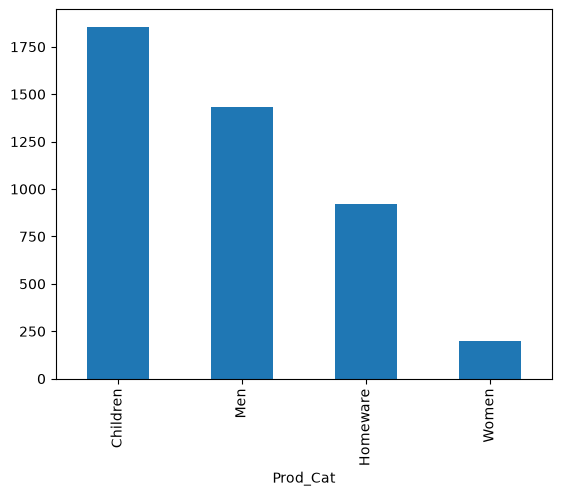

In [69]:
prod_cat_freq.plot(kind="bar")
plt.show()

We can customise the appearance of this bar chart. For instance, we can change the figure size using `figsize`, which specifies the `width` and `height` of the figure as a tuple. 

We can also specify a `color` argument (either a name or a HTML colour code) -- note the American spelling of the argument name!

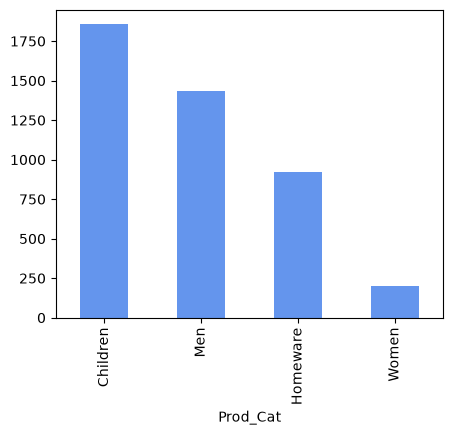

In [70]:
prod_cat_freq.plot(kind="bar",
                   figsize=(5, 4), color="cornflowerblue")
plt.show()

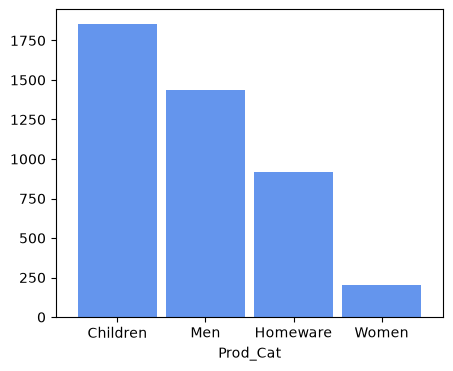

In [71]:
prod_cat_freq.plot(kind="bar", 
                   figsize=(5, 4), color="cornflowerblue",
                   rot=0, width=0.9)
# rotates the x-axis tick labels by 0 degrees, so they appear horizontally
# sets each bar's width to 90% of the available space between bar positions, making the bars relatively wide
plt.show()

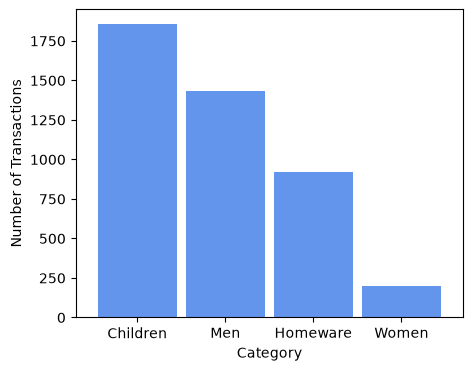

In [72]:
prod_cat_freq.plot(kind="bar", 
                   figsize=(5, 4), color="cornflowerblue",
                   rot=0, width=0.9,
                   ylabel="Number of Transactions", xlabel="Category")
plt.show()

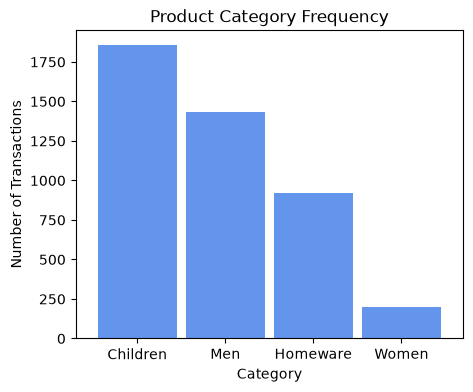

In [73]:
prod_cat_freq.plot(kind="bar", 
                   figsize=(5, 4), color="cornflowerblue",
                   rot=0, width=0.9,
                   ylabel="Number of Transactions", xlabel="Category",
                   title="Product Category Frequency")
plt.show()

### Horizontal Bar Charts 

Horizontal bar charts (`barh`) simply rotate the bars. 

These are very useful when bars have long labels or when we have many bars.

As an example, let's calculate the frequency of the product categories in our data, by applying the `value_counts` function to the 'Prod_Sub_Cat' column in our DataFrame.

In [74]:
prod_sub_cat_freq = abt["Prod_Sub_Cat"].value_counts()
prod_sub_cat_freq

Prod_Sub_Cat
Boys_wear     963
Girls_wear    893
Shirts        763
Design        566
Jeans         428
Bed_Bath      353
Shoes         156
Trousers      111
Dresses       103
Tops           75
Name: count, dtype: int64

Again, we call the Pandas `plot` function, but this time we specify the argument `kind=barh`

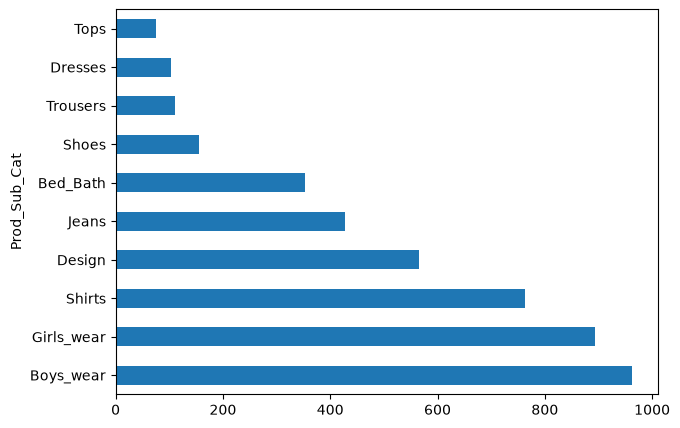

In [75]:
prod_sub_cat_freq.plot(kind="barh", 
                       figsize=(7,5))
plt.show()

We can customise the appearance of the horizontal bar chart

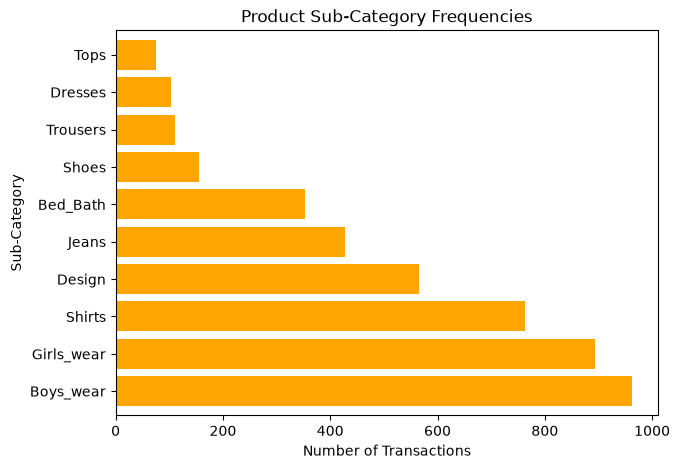

In [76]:
prod_sub_cat_freq.plot(kind="barh", 
                       figsize=(7,5), color="orange", 
                       width=0.8,
                       xlabel="Number of Transactions", ylabel="Sub-Category",
                       title="Product Sub-Category Frequencies")
plt.show()

Note we can change the range and ticks on the numeric axis

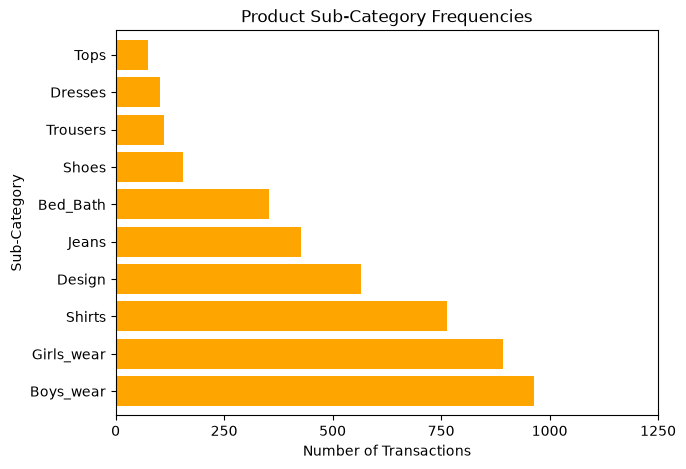

In [77]:
prod_sub_cat_freq.plot(kind="barh", 
                       figsize=(7,5), color="orange", 
                       width=0.8,
                       xlabel="Number of Transactions", ylabel="Sub-Category",
                       title="Product Sub-Category Frequencies",
                       xlim=(0, 1250), xticks=(0, 250, 500, 750, 1000, 1250))
plt.show()

Sometimes we want to flip the ordering of the bars in a horizontal bar chart. 

A convenient way of doing this is to use `iloc[::-1]` to reverse a Series.

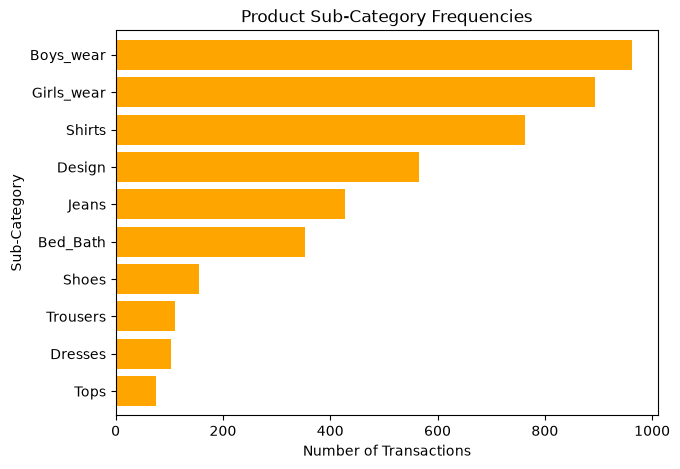

In [78]:
# reverse the ordering of the frequency table
reversed = prod_sub_cat_freq.iloc[::-1]
# now create the plot
reversed.plot(kind="barh", 
              figsize=(7,5), color="orange", 
              width=0.8,
              xlabel="Number of Transactions", ylabel="Sub-Category",
              title="Product Sub-Category Frequencies")
plt.show()

### Now you try...


The 'Campaign' column in the transaction data indicates whether the transaction related to a particular marketing campaign.

- Create a frequency table for this column

In [79]:
campaign_freq = abt["Campaign"].value_counts()
campaign_freq

Campaign
No Campaign           3847
New Customer Offer     454
No                      70
New Customer            40
Name: count, dtype: int64

- Create a `bar` chart showing the campaign frequency table from above

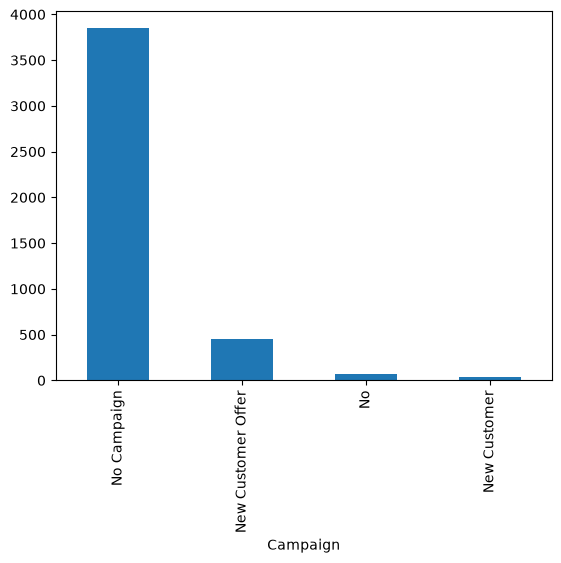

In [80]:
campaign_freq.plot(kind="bar")
plt.show()

- Experiment with various options (e.g. colours, size, grid lines, ...) to change the appearance of the chart

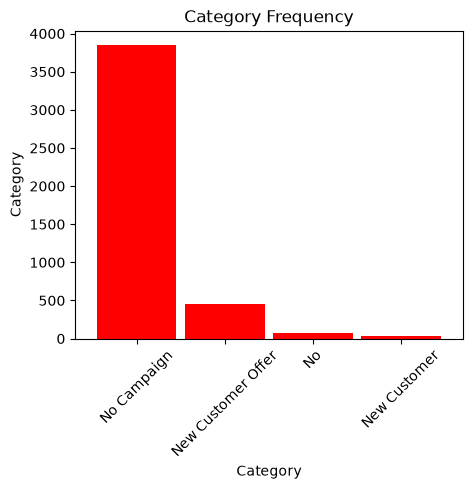

In [81]:
campaign_freq.plot(kind="bar",                  
               figsize=(5, 4), color="red",
               rot=45, width=0.9,
               ylabel="Category", xlabel="Category",
               title="Category Frequency")
plt.show()
# campaign_freq.plot(kind="bar", figsize=(7, 4), rot=0, color="green",
#                   ylabel="Number of Transactions", title="Transaction Campaign Frequencies",
#                   yticks=[0,1000,2000,3000,4000])
# plt.show()

- Represent the same information using a horizontal bar chart

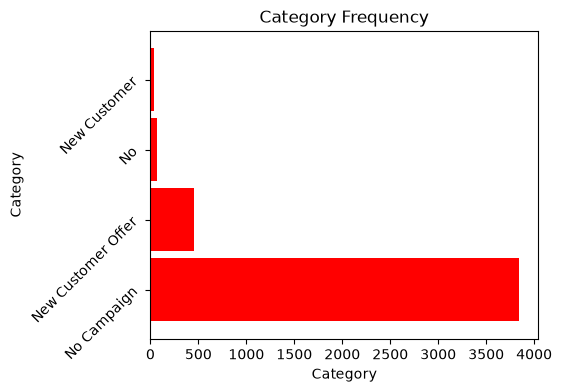

In [82]:
campaign_freq.plot(kind="barh",                  
               figsize=(5, 4), color="red",
               rot=45, width=0.9,
               ylabel="Category", xlabel="Category",
               title="Category Frequency")
plt.show()
# reversed = campaign_freq.iloc[::-1]
# reversed.plot(kind="barh", figsize=(7, 4), 
#                        color="green", width=0.8,
#                        xlabel="Number of Transactions", ylabel="",
#                        title="Transaction Campaign Frequencies")
# plt.show()

### Pie Charts

Pie charts are much maligned in the data visualisation community, but can be useful to show *parts of a whole* relationships (for example the share of votes in an election or the distribution of categories). 

Avoid pie charts when there are a large number of categories (more than 6), or if the differences between segments is very small - it is hard for people to perceive small differences. 

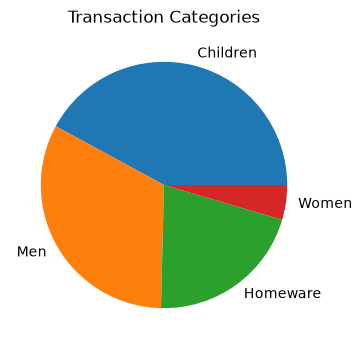

In [83]:
prod_cat_freq.plot(kind="pie", 
                   figsize=(5, 4), 
                   title="Transaction Categories")
plt.show()

Again we can customise the appearance of the chart. Colour maps provide defined colour palettes. 

The pie chart cycles through the colours in the `colormap`. 

Matplotlib colour maps are described [here](https://matplotlib.org/stable/tutorials/colors/colormaps.html). 

Note the American spelling of the argument name!

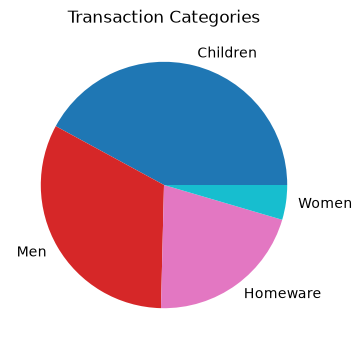

In [84]:
prod_cat_freq.plot(kind="pie", 
                   figsize=(5, 4), 
                   title="Transaction Categories",
                   colormap="tab10")
plt.show()

We can add percentage labels to a pie chart using the `autopct` argument which we set to the format of the labels (in this example, to display two decimal places). 

We can also remove the spurious "None" label on the left of the plot be setting `label = ""`.

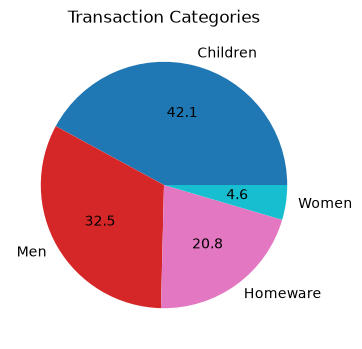

In [85]:
prod_cat_freq.plot(kind="pie", 
                   figsize=(5, 4), 
                   title="Transaction Categories",
                   colormap="tab10",
                   autopct="%.1f",
                   label="")
plt.show()

### Histograms

Histograms are a great way to visualise the distribution of numeric values in a feature in our data.

For example, we might want to visualise the distribution of the total product sale amount across all of our retail transactions. 

We can do this by accessing the 'Total_Product_sale' column in our DataFrame and calling the `plot` function with the argument `kind=hist`.

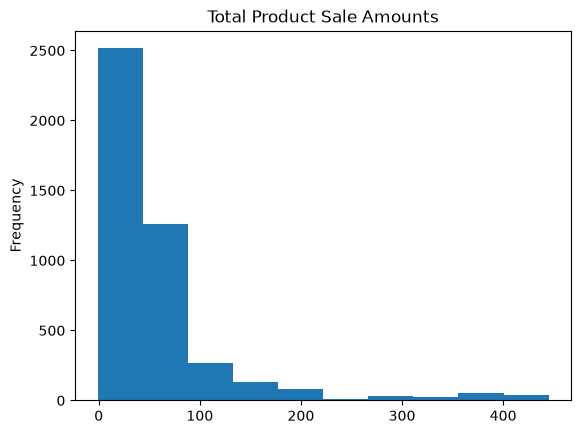

In [86]:
# access the Total_Product_Sale column and call plot
abt["Total_Product_Sale"].plot(kind="hist", 
                               title="Total Product Sale Amounts")
plt.show()

We can change the appearance of the histogram, including changing the limits on the numeric axis (for example starting at 0)

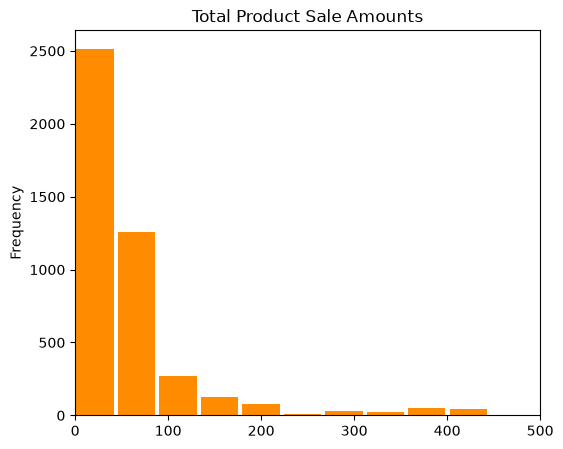

In [87]:
# access the Total_Product_Sale column and call plot
abt["Total_Product_Sale"].plot(kind="hist", 
                               figsize=(6, 5), color="darkorange",
                               rwidth=0.9,
                               title="Total Product Sale Amounts",
                               xlim=(0, 500))
plt.show()

### Box Plots & Density Plots

Box plots (`box`) and density plots (`kde`) are a useful alternative to histograms for showing distributions for a feature in a DataFrame (although we will see later that they are more useful for comparing distributions of multiple features). 

As a simple example, we could look at the distribution of total product sale amounts across all of the transactions in the data.

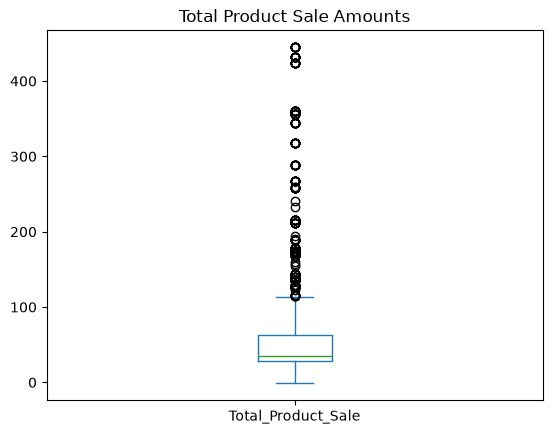

In [88]:
abt["Total_Product_Sale"].plot(kind="box", title="Total Product Sale Amounts")
plt.show()

We could also create a density plot to examine the same data

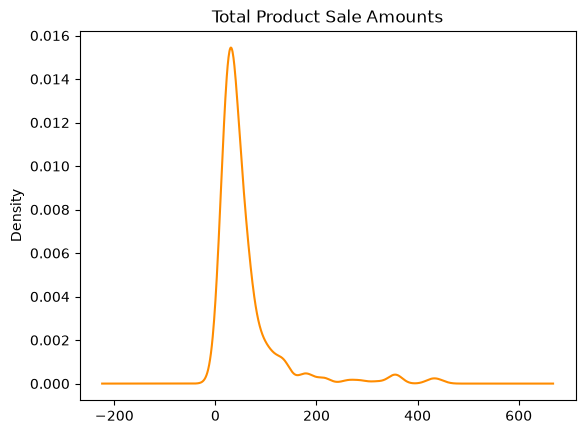

In [89]:
abt["Total_Product_Sale"].plot(kind="kde", # scipy 
                               color="darkorange",
                               title="Total Product Sale Amounts")
plt.show()

### Line Plots

A `line` plot displays numeric values connected by a continuous line. This is often used to show trends or changes in data over time.

Let's calculate the number of transactions per day...

In [90]:
# we won't sort the dates
transaction_freqs = abt["Transaction_Date"].value_counts(sort=False) 
# preserves the order in which distinct values first appear in the data
transaction_freqs

Transaction_Date
01/01/2019    24
02/01/2019    24
03/01/2019    24
04/01/2019    21
05/01/2019    25
              ..
27/12/2019    12
28/12/2019    10
29/12/2019    10
30/12/2019    14
31/12/2019    19
Name: count, Length: 365, dtype: int64

Next, we will produce a line plot of the number of transactions in the first 30 days in our dataset

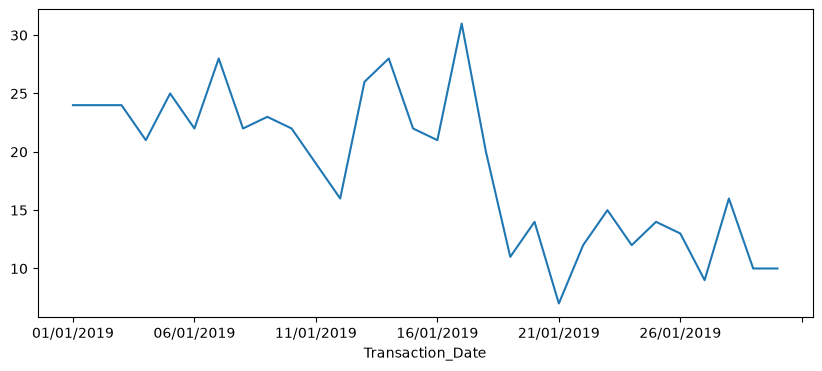

In [91]:
first30_transaction_freqs = transaction_freqs.head(30)
first30_transaction_freqs.plot(kind="line",
                               figsize=(10,4))
plt.show()

We can customise this just like with other charts that we have seen

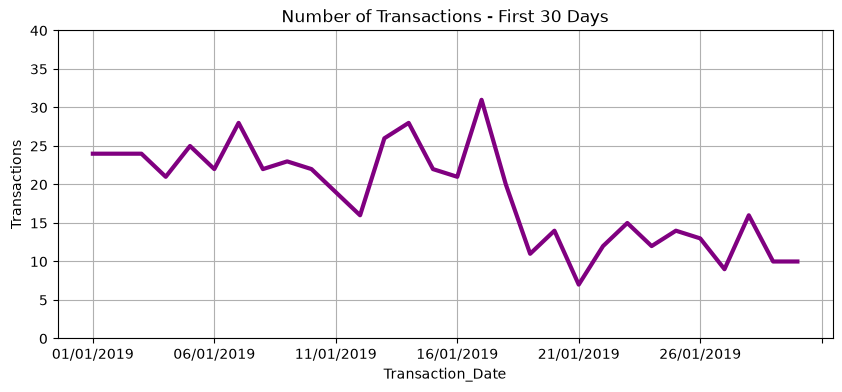

In [92]:
first30_transaction_freqs.plot(kind="line",
                               figsize=(10,4), color="purple",
                               lw=3, # linewidth
                               ylabel="Transactions",
                               title="Number of Transactions - First 30 Days",
                               ylim=(0, 40),
                               grid=True, 
                               zorder=3) # controls which plotting elements appear in front of or behind other elements
plt.show()

### Area Plots

`Area` plots just fill in the area under a line chart. 

Again this can be useful for plotting time series data and they are often used for showing cumulative totals over time.

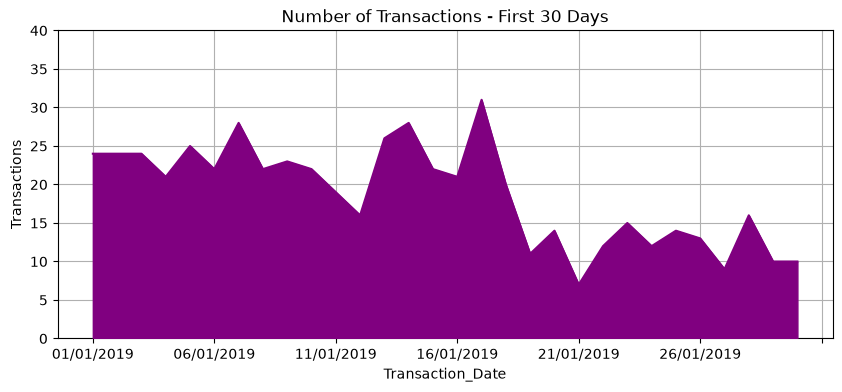

In [93]:
first30_transaction_freqs.plot(kind="area",
                               figsize=(10,4), color="purple",
                               ylabel="Transactions",
                               title="Number of Transactions - First 30 Days",
                               ylim=(0, 40),
                               grid=True, 
                               zorder=3)
plt.show()

### Now you try...

- Create a histogram showing the distribution of values for the total profit amounts on each transaction, based on the 'Total_Profit' column in the data

In [94]:
abt.index.is_unique                    

True

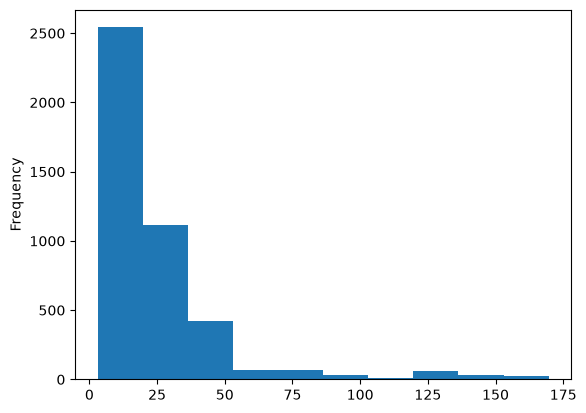

In [95]:
abt["Total_Profit"].plot(kind="hist") 
plt.show()
# abt["Total_Profit"].plot(kind="hist", title="Total Profit Amounts",
#                               figsize=(6, 5), xlim=(0, 200),
#                               color="darkorange", rwidth=0.9)
# plt.show()

- Create a box plot showing the distribution of the price per unit of the products in each transaction, based on the 'Price_Per_Unit' column

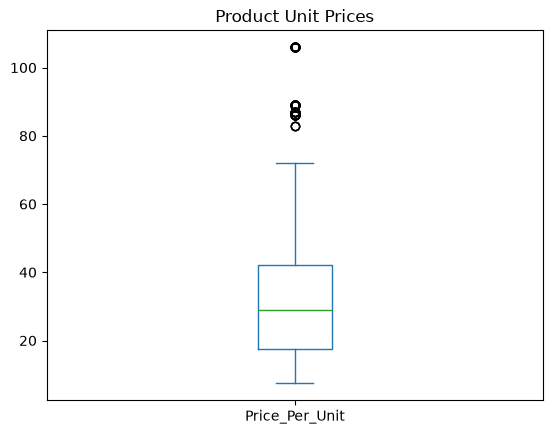

In [96]:
abt["Price_Per_Unit"].plot(kind="box", title="Product Unit Prices")
plt.show()

- Create a line plot of the number of transactions per day over the last 90 days in our dataset (Hint: use the 'Transaction_Date' column like before).

 Customise various aspects of the appearance of the plot.

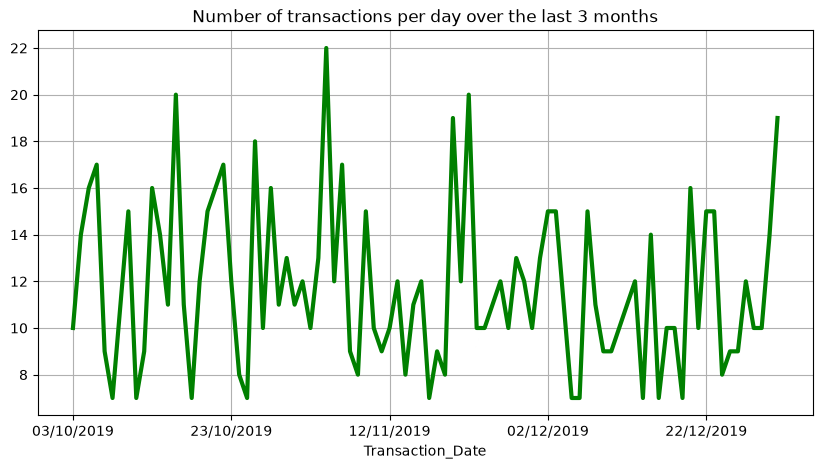

In [97]:
abt["Transaction_Date"].value_counts(sort=False).tail(90).plot(kind="line",
                                                              figsize=(10,5), color="green",
                                                              lw=3,
                                                              title="Number of transactions per day over the last 3 months",
                                                              grid=True)
plt.show()
# transaction_freqs = abt["Transaction_Date"].value_counts(sort=False)
# last90_transaction_freqs = transaction_freqs.head(90)
# last90_transaction_freqs.plot(kind="line",
#                                figsize=(10,4),
#                                color="purple",
#                                lw=2,
#                                title="Number of Transactions - Last 90 Days",
#                                ylabel="Transactions",
#                                ylim=(0, 40),
#                                grid=True, zorder=3)
# plt.show()

### Saving Plots

Matplotlib (the engine underlying the plots we draw in Pandas) can generate high quality graphics that we can save out to different image formats using the `savefig` function. 

The extension of the output filename will determine the format.

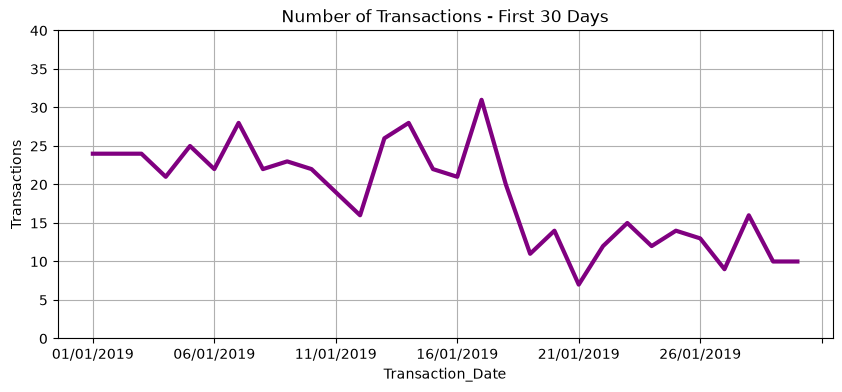

In [98]:
# create the plot
ax = first30_transaction_freqs.plot(kind="line",
                                    figsize=(10,4), color="purple",
                                    lw=3,
                                    ylabel="Transactions",
                                    title="Number of Transactions - First 30 Days",
                                    ylim=(0, 40),
                                    grid=True, zorder=3)
plt.show()

In [99]:
# save the plot as a JPEG image
ax.figure.savefig("lineplot.jpg", bbox_inches="tight") 
# crops the saved image to fit the plot elements more closely (e.g., titles, axis labels, tick labels, ..).

In [100]:
# save the plot as a PNG image
ax.figure.savefig("lineplot.png", bbox_inches="tight")

In [101]:
# save the plot  as a PDF
ax.figure.savefig('lineplot.pdf', bbox_inches="tight")

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Preparing Data with Pandas

In [102]:
pip install scikit-learn # INSTALL THE MISSING PACKAGE


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [103]:
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS
import matplotlib # TO PLOT
import matplotlib.pyplot as plt # TO PLOT

# this line is needed to ensure plots will appear in the notebook
%matplotlib inline

# import a custom set of functions
import krisolisutils

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format 

### Data Loading

We will load our previous dataset of transactions for an online fashion retailer from the CSV file `urban_wear_transactions.csv` and store it in a Pandas DataFrame as our **Analytics Base Table (ABT)**

In [104]:
datafile_name = "urban_wear_transactions.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first 10 rows
abt.head(10)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


Check the size of the DataFrame and the list of its columns

In [105]:
print(abt.columns)
print("Dataset has %d rows and %d columns" % abt.shape)

Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'On_Sale', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant',
       'Sale_Amount', 'Total_Cost', 'Total_Product_Sale', 'Total_Profit'],
      dtype='str')
Dataset has 4411 rows and 17 columns


Next, check the type of the columns

In [106]:
abt.dtypes

Transaction_Date          str
Customer_ID               str
Product_ID                str
Prod_Cat                  str
Prod_Description          str
Prod_Sub_Cat              str
Campaign                  str
Cost_Per_Unit         float64
Discount              float64
On_Sale                   str
Price_Per_Unit        float64
Profit_Per_Unit       float64
Quant                   int64
Sale_Amount           float64
Total_Cost            float64
Total_Product_Sale    float64
Total_Profit          float64
dtype: object

### Initial Characterisation of the Data

We start the process by printing **descriptive statistics** for all of the columns in our ABT. 

Note that we need to check numeric and categorical columns separately.

In [107]:
# display numeric columns
abt.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Cost_Per_Unit,"4,411.00",19.12,13.11,3.67,8.57,17.40,23.65,63.60
Discount,"4,411.00",0.01,0.03,0.00,0.00,0.00,0.00,0.10
Price_Per_Unit,"4,411.00",33.34,20.10,7.50,17.50,29.00,42.00,106.00
Profit_Per_Unit,"4,411.00",14.22,7.39,3.83,8.93,11.47,18.40,42.40
Quant,"4,411.00",1.69,1.18,-1.00,1.00,1.00,2.00,10.00
Sale_Amount,"4,411.00",33.00,20.02,6.75,17.50,29.00,42.00,106.00
Total_Cost,"4,411.00",34.78,43.73,3.67,15.68,19.80,34.50,289.25
Total_Product_Sale,"4,411.00",59.00,68.08,-1.00,29.00,35.00,63.00,445.00
Total_Profit,"4,367.00",24.57,24.53,3.08,11.02,17.85,26.77,169.60


In [108]:
# manually select and display categorical columns
abt.select_dtypes(include=[object]).describe().transpose()

/var/folders/yt/p_mpkw6n1sl4ntss8hgt5wjc0000gn/T/ipykernel_15146/4190706618.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  abt.select_dtypes(include=[object]).describe().transpose()


,count,unique,top,freq
Transaction_Date,4411,365,17/01/2019,31
Customer_ID,4332,2805,C_ID_46596,35
Product_ID,4337,99,P_ID_100091,214
Prod_Cat,4411,4,Children,1856
Prod_Description,4323,99,White Colour Block T-Shirt,212
Prod_Sub_Cat,4411,10,Boys_wear,963
Campaign,4411,4,No Campaign,3847
On_Sale,4411,4,No,3797


We can use the utility function `data_viz` in the custom `krisolisutils` package to produce simple visualisations to show the distributions of the **numeric** and **categorical** columns in the data

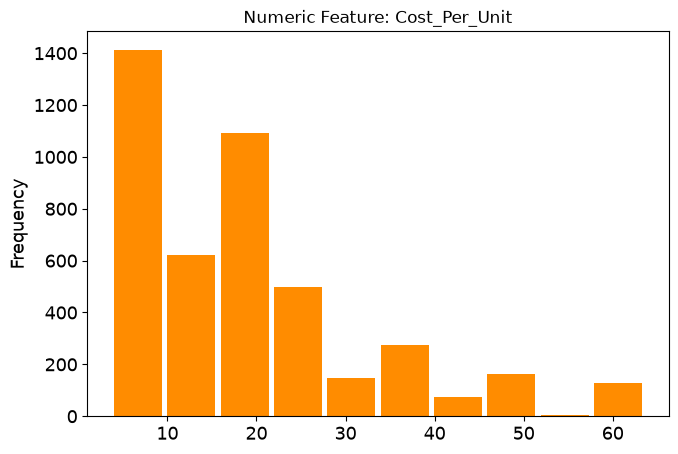

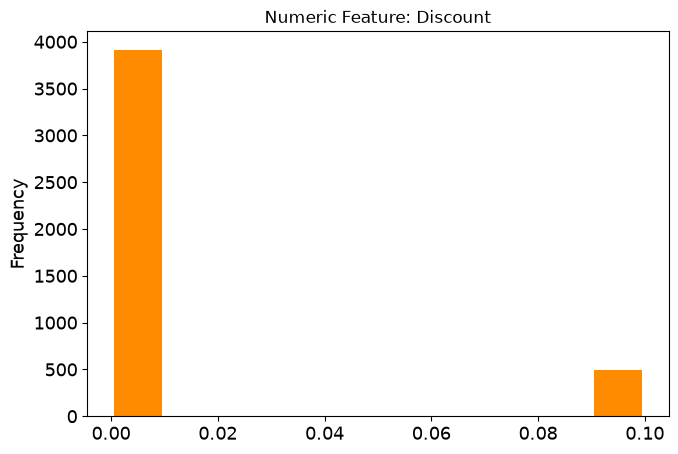

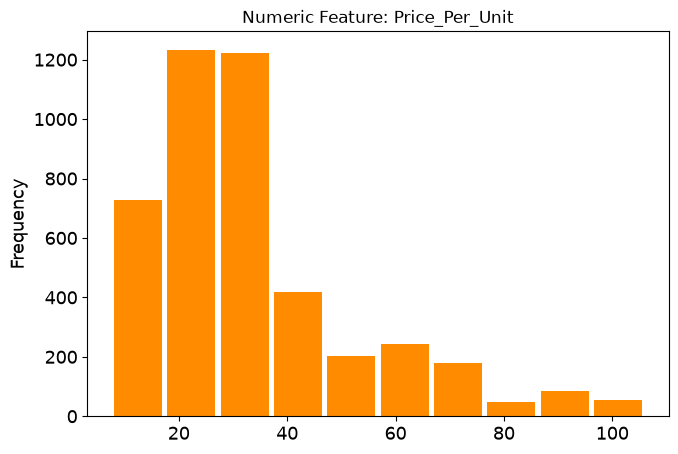

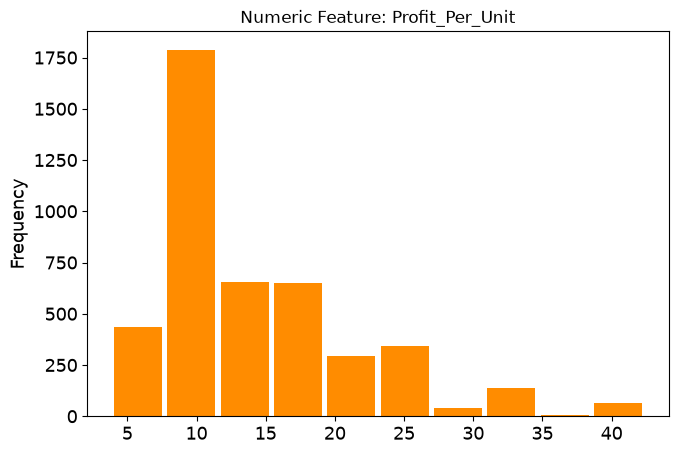

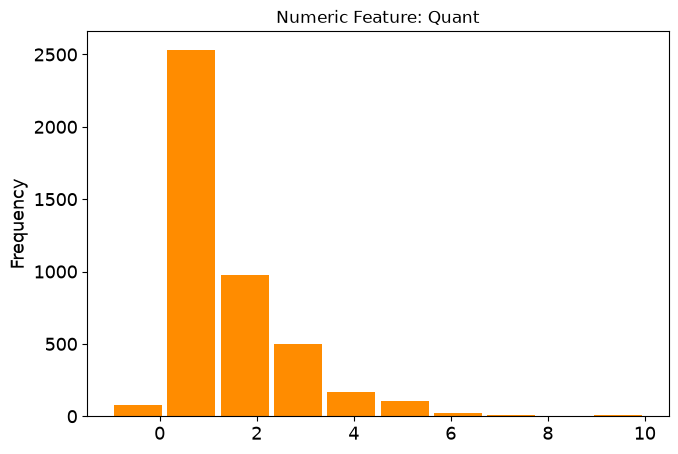

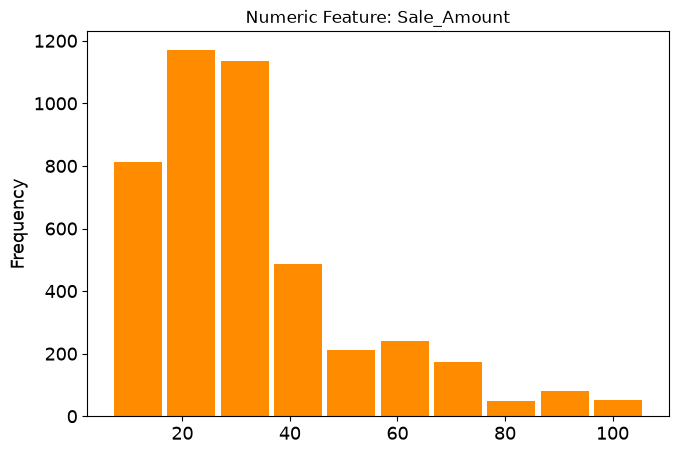

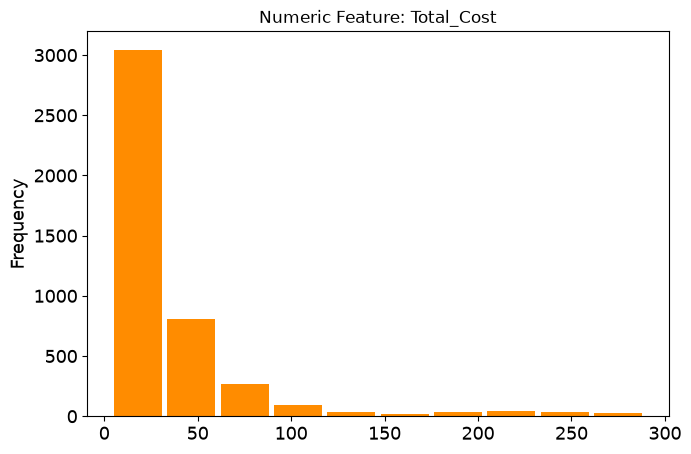

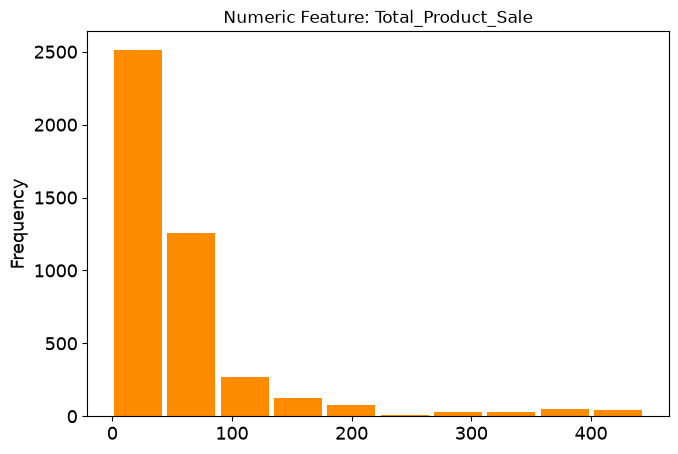

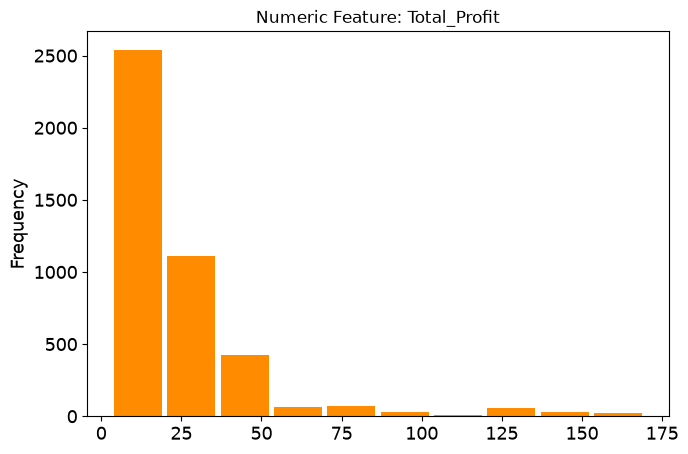

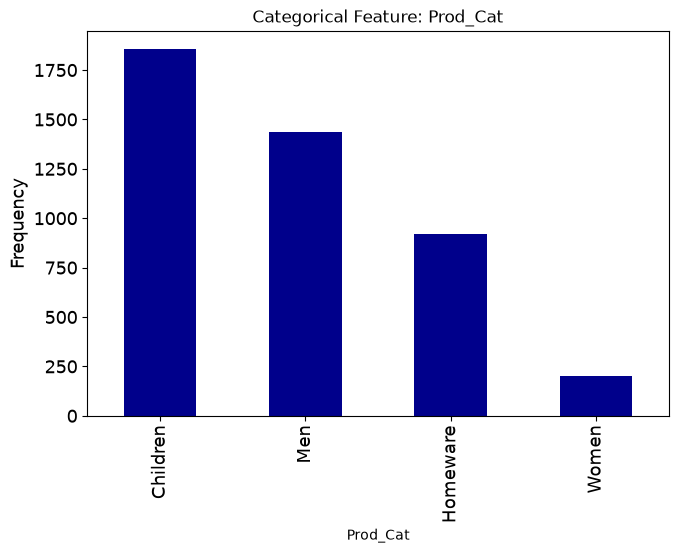

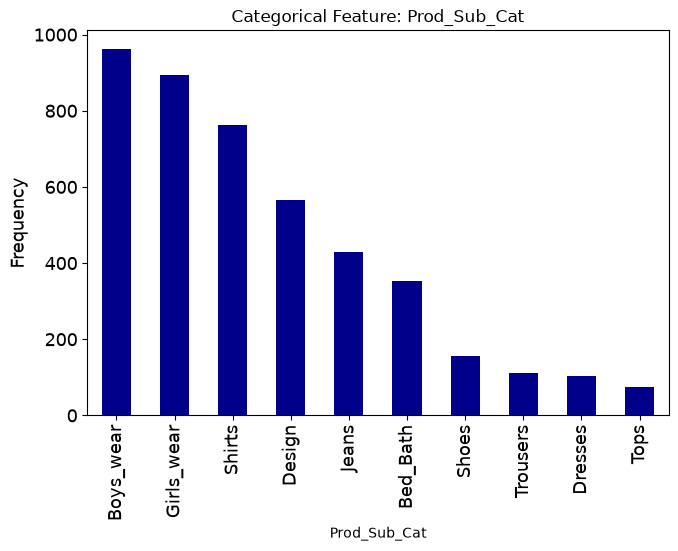

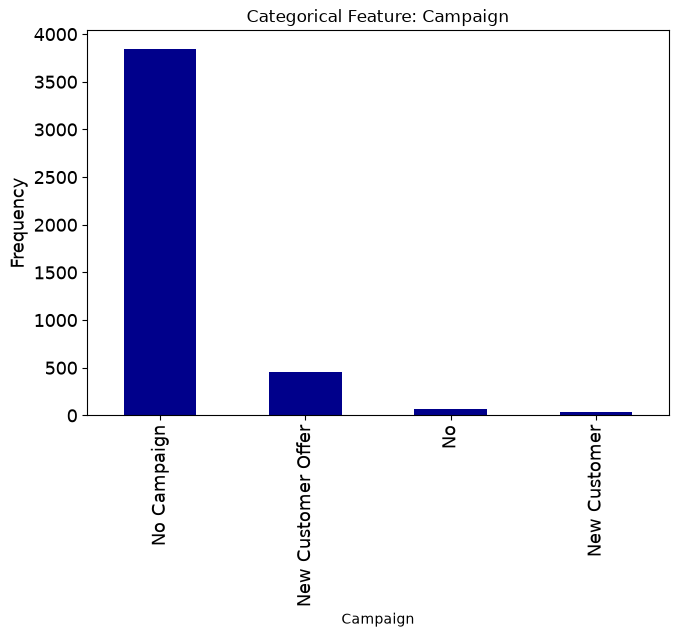

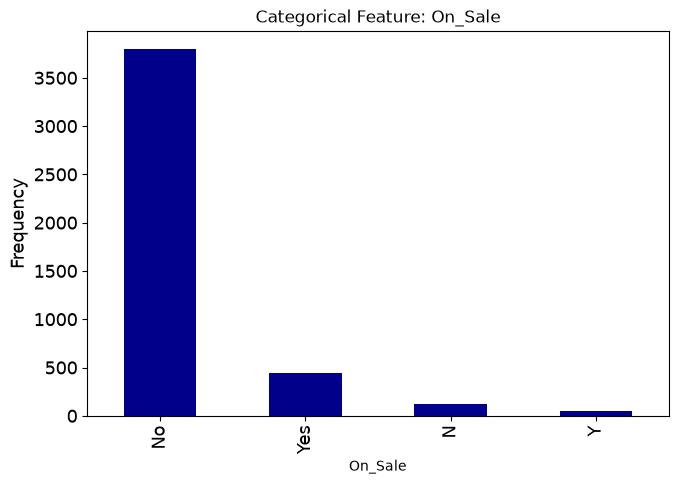

In [109]:
krisolisutils.data_viz(abt)

### Identifying Data Quality Issues

Next, we need to figure out if our dataset contains any data quality issues.

Check for **irregular cardinality** in the categorical columns in the data.

In [110]:
# get the categorical variables
abt_categorical = abt.select_dtypes(include=[object])
# count the levels
count_levels = {}
for col in abt_categorical.columns:
    count_levels[col] = len(abt_categorical[col].unique())
# turn this into a DataFrame
df_levels = pd.Series(count_levels, name="Levels").to_frame()
df_levels.sort_values(by="Levels", ascending=False)

/var/folders/yt/p_mpkw6n1sl4ntss8hgt5wjc0000gn/T/ipykernel_15146/315014198.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  abt_categorical = abt.select_dtypes(include=[object])


,Levels
Customer_ID,2806
Transaction_Date,365
Product_ID,100
Prod_Description,100
Prod_Sub_Cat,10
Prod_Cat,4
Campaign,4
On_Sale,4


Some of these columns would be expected to have high cardinality (e.g. unique transaction, product, or customer IDs). 

But others may need to be investigated.

As an example, let's look at the 'On_Sale' column.

In [111]:
abt["On_Sale"].value_counts()

On_Sale
No     3797
Yes     447
N       120
Y        47
Name: count, dtype: int64

Check for presence of **missing values** in each column

In [112]:
# get the number and percentage of missing values
num_missing = abt.isnull().sum()
per_missing = num_missing*100.0/len(abt)
# turn this into a DataFrame to make it easier to read
df_missing = pd.DataFrame({"Num Missing":num_missing, "% Missing":per_missing})
df_missing.sort_values(by="Num Missing", ascending=False)

,Num Missing,% Missing
Prod_Description,88,2.00
Customer_ID,79,1.79
Product_ID,74,1.68
Total_Profit,44,1.00
Price_Per_Unit,0,0.00
Total_Product_Sale,0,0.00
Total_Cost,0,0.00
Sale_Amount,0,0.00
Quant,0,0.00
Profit_Per_Unit,0,0.00


Finally, we will check for **outliers**. 

Let's look at the ranges for our numeric columns again. 

Are there any values that look unusual here?

In [113]:
numeric_description = abt.select_dtypes(include=[np.number]).describe().transpose()
numeric_description[["min","max"]]

,min,max
Cost_Per_Unit,3.67,63.60
Discount,0.00,0.10
Price_Per_Unit,7.50,106.00
Profit_Per_Unit,3.83,42.40
Quant,-1.00,10.00
Sale_Amount,6.75,106.00
Total_Cost,3.67,289.25
Total_Product_Sale,-1.00,445.00
Total_Profit,3.08,169.60


### Fix Data Quality Issues

Next, we need to fix any data quality issues in our ABT that were identified in the previous step.

In terms of **irregular cardinality**, let's fix the spurious categories in the 'On_Sale' column using the `replace` method.

In [114]:
abt["On_Sale"] = abt["On_Sale"].replace({"Y": "Yes", "N": "No"})

In [115]:
# check the frequencies for this column now
abt["On_Sale"].value_counts()

On_Sale
No     3917
Yes     494
Name: count, dtype: int64

Next we handle columns **missing values**.

For the missing product description values, we could fill in a default description string. 

Note that we could also do something more advanced, such as creating a description based on the existing product category and sub-category information.

In [116]:
abt["Prod_Description"] = abt["Prod_Description"].fillna("No description")

For the rows with missing 'Customer_ID' information, we might decide to remove those rows entirely, as they might be essential to our analysis. 

Apply this strategy with care, as it this can also remove potentially useful data.

We perform this operation by calling the `dropna` method associated with the full DataFrame and specifying the `subset` of column names that we want to use to filter data based on missing values.

In [117]:
# drop rows where 'Customer_ID' is missing
abt = abt.dropna(subset=["Customer_ID"])

Finally, we will look at **outliers**.

For the column 'Quant', the observed lowest value of -1 does not make sense. Let's assume that there will also be at least one product (i.e. minimum quantity of 1).

We can do this by accessing the column in question and call the `clip` method. 

We specify a `lower` threshold argument, an `upper` threshold, or both. Anything outside of these limits gets replaced with either the `lower` or `upper` value.

In [118]:
# specify a lower threshold
abt["Quant"] = abt["Quant"].clip(lower=1)
# check the range of the column now
abt["Quant"].min(), abt["Quant"].max()

(np.int64(1), np.int64(10))

### Now you try...

- Check the column 'Campaign' for irregular cardinality and fix any issues that your encounter

In [119]:
# check the frequencies in this column
# abt["Campaign"].value_counts()
# replace spurious values
abt["Campaign"] = abt["Campaign"].replace({"No":"No Campaign", "New Customer":"New Customer Offer"})
# check the frequencies in this column again
abt["Campaign"].value_counts()

Campaign
No Campaign           3842
New Customer Offer     490
Name: count, dtype: int64

- Remove any rows from the ABT for which the 'Product_ID' column contains a missing value

In [120]:
abt = abt.dropna(subset=["Product_ID"])

- Handle missing values in the 'Total_Profit' column by replacing any missing value with a profit of 0

In [121]:
abt["Total_Profit"] = abt["Total_Profit"].fillna(0)

- Handle outliers in the 'Total_Product_Sale' column by ensuring that values in this column are non-negative (>=0) and do not exceed 400

In [122]:
abt["Total_Product_Sale"] = abt["Total_Product_Sale"].clip(lower=0, upper=400)

### Further Characterisation of the Data

Once we have addressed the data quality issues, we might typically want to characterise our newly-cleaned data again.

We might recalculate descriptive statistics for the **numeric columns** in the data.

In [123]:
abt.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Cost_Per_Unit,"4,258.00",19.19,13.13,3.67,8.57,17.40,23.65,63.60
Discount,"4,258.00",0.01,0.03,0.00,0.00,0.00,0.00,0.10
Price_Per_Unit,"4,258.00",33.45,20.14,7.50,17.50,29.00,42.00,106.00
Profit_Per_Unit,"4,258.00",14.26,7.41,3.83,8.93,11.47,18.40,42.40
Quant,"4,258.00",1.73,1.14,1.00,1.00,1.00,2.00,10.00
Sale_Amount,"4,258.00",33.11,20.06,6.75,17.50,29.00,42.00,106.00
Total_Cost,"4,258.00",35.02,43.99,3.67,16.17,19.80,34.80,289.25
Total_Product_Sale,"4,258.00",59.05,66.74,0.00,29.00,35.00,63.00,400.00
Total_Profit,"4,258.00",24.46,24.67,0.00,11.02,17.85,26.77,169.60


Also recalculate descriptive statistics for the **categorical columns** in the data

In [124]:
abt.select_dtypes(include=[object]).describe().transpose()

/var/folders/yt/p_mpkw6n1sl4ntss8hgt5wjc0000gn/T/ipykernel_15146/879508252.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  abt.select_dtypes(include=[object]).describe().transpose()


,count,unique,top,freq
Transaction_Date,4258,365,17/01/2019,30
Customer_ID,4258,2771,C_ID_46596,35
Product_ID,4258,99,P_ID_100091,210
Prod_Cat,4258,4,Children,1784
Prod_Description,4258,100,White Colour Block T-Shirt,206
Prod_Sub_Cat,4258,10,Boys_wear,931
Campaign,4258,2,No Campaign,3772
On_Sale,4258,2,No,3772


### Now you try...

- Verify that there are no longer any missing values in the ABT

In [125]:
A = abt.isnull().sum()
A
# num_missing = abt.isnull().sum()
# per_missing = num_missing*100.0/len(abt)
# df_missing = pd.DataFrame({"Num Missing":num_missing, "% Missing":per_missing})
# df_missing.sort_values(by="Num Missing", ascending=False)

Transaction_Date      0
Customer_ID           0
Product_ID            0
Prod_Cat              0
Prod_Description      0
Prod_Sub_Cat          0
Campaign              0
Cost_Per_Unit         0
Discount              0
On_Sale               0
Price_Per_Unit        0
Profit_Per_Unit       0
Quant                 0
Sale_Amount           0
Total_Cost            0
Total_Product_Sale    0
Total_Profit          0
dtype: int64

- Produce a set of simple visualisations to show the distributions of the numeric and categorical columns in the ABT

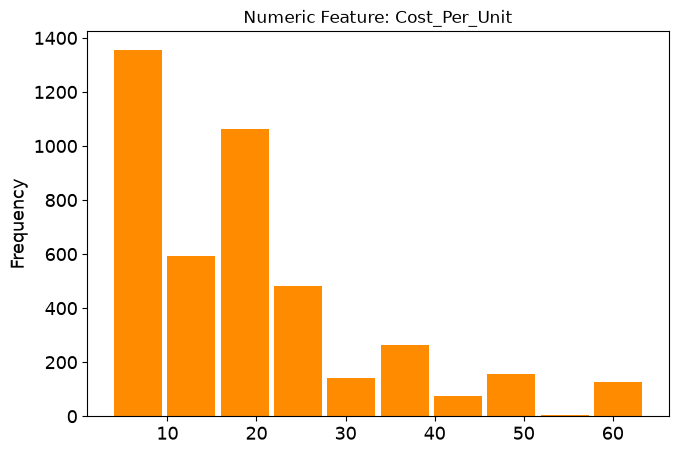

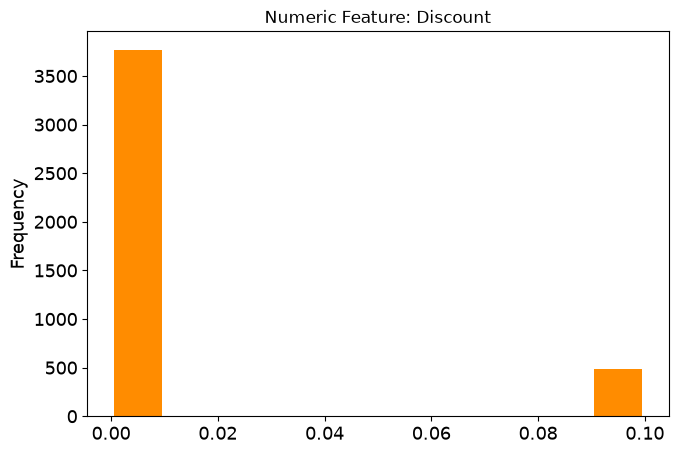

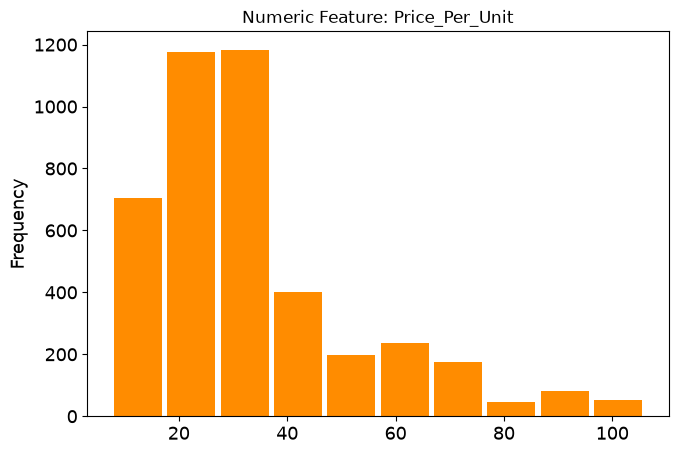

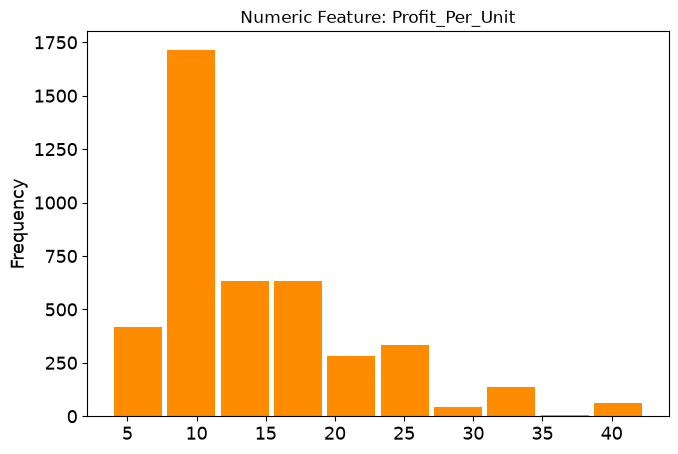

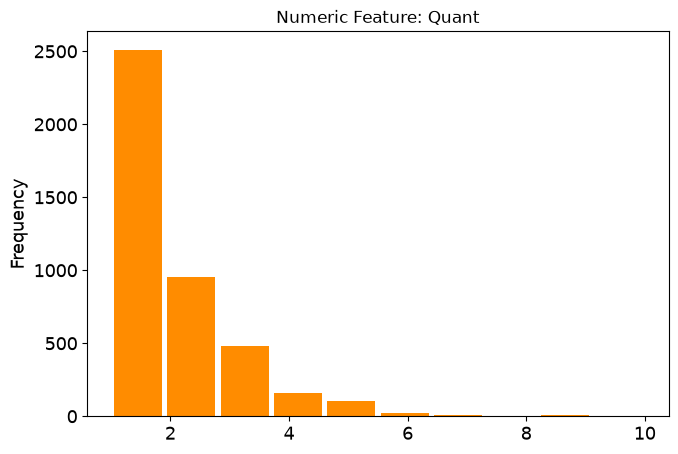

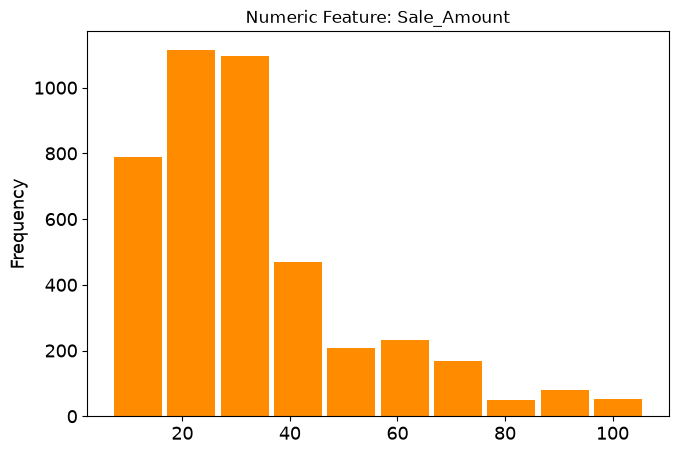

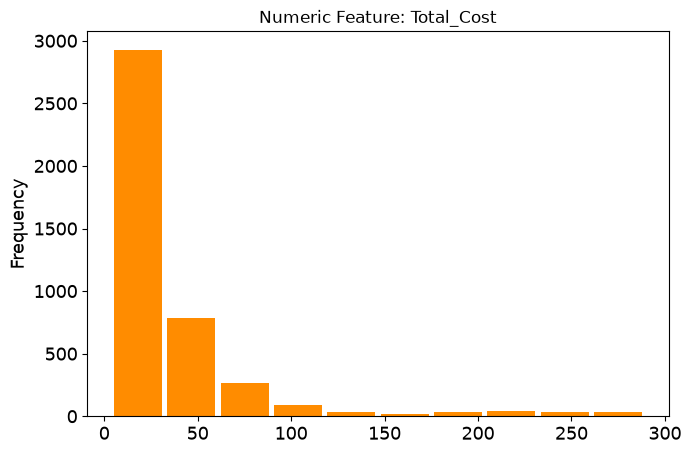

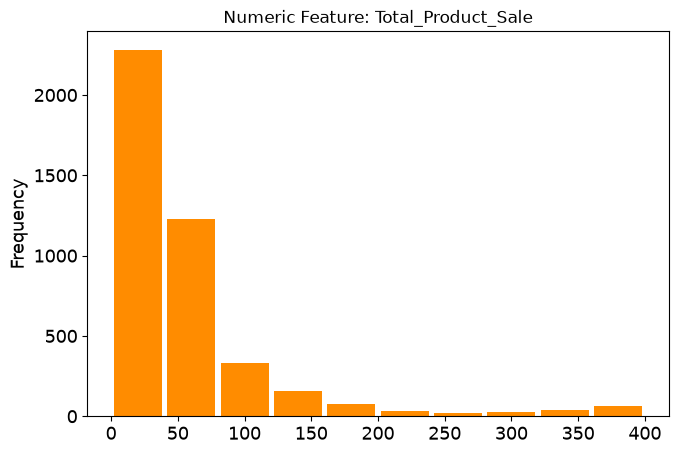

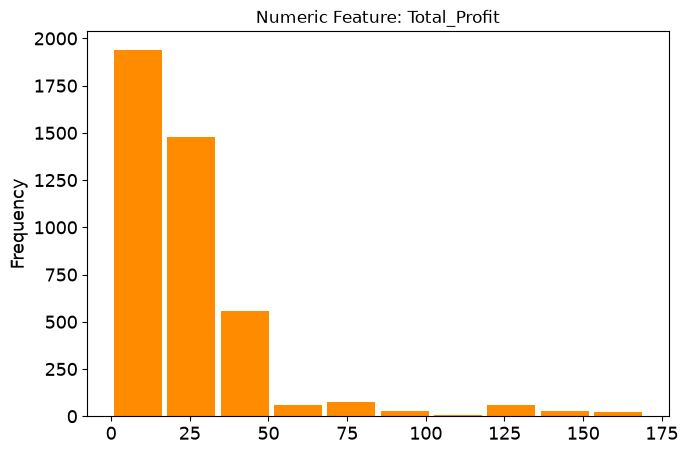

/var/folders/yt/p_mpkw6n1sl4ntss8hgt5wjc0000gn/T/ipykernel_15146/3104161485.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  krisolisutils.data_viz(abt.select_dtypes(include=[object]))


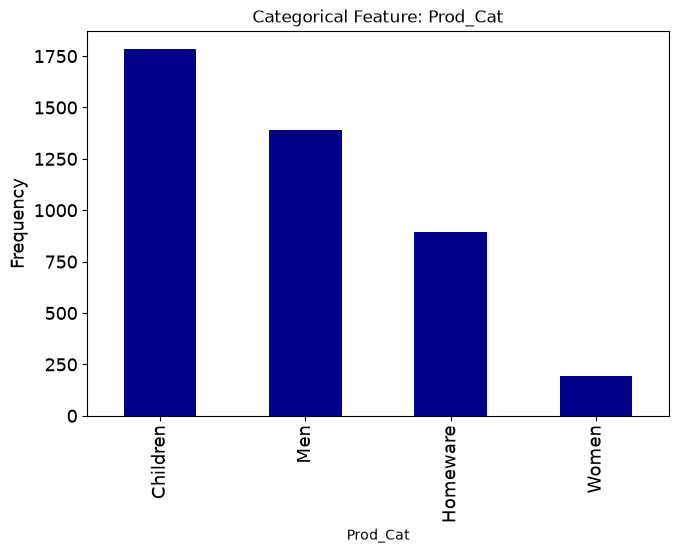

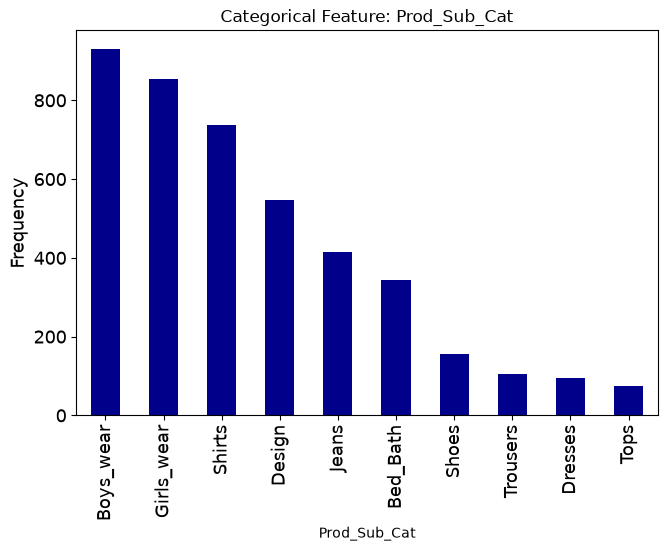

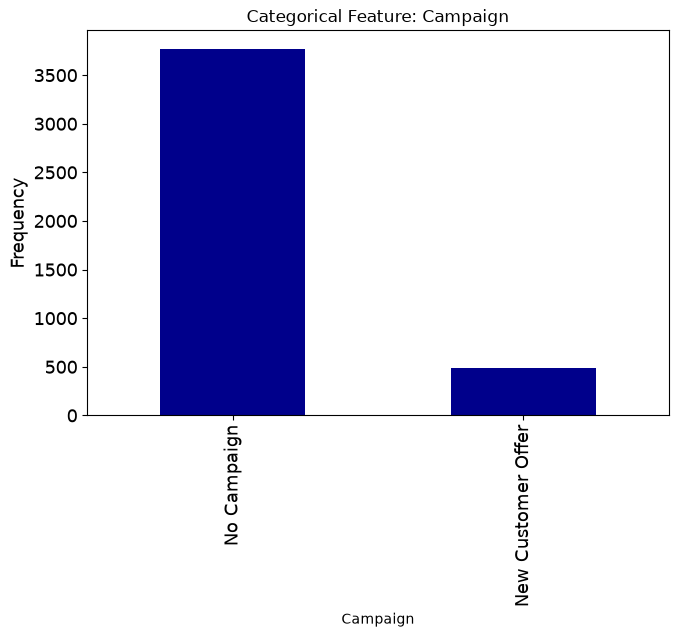

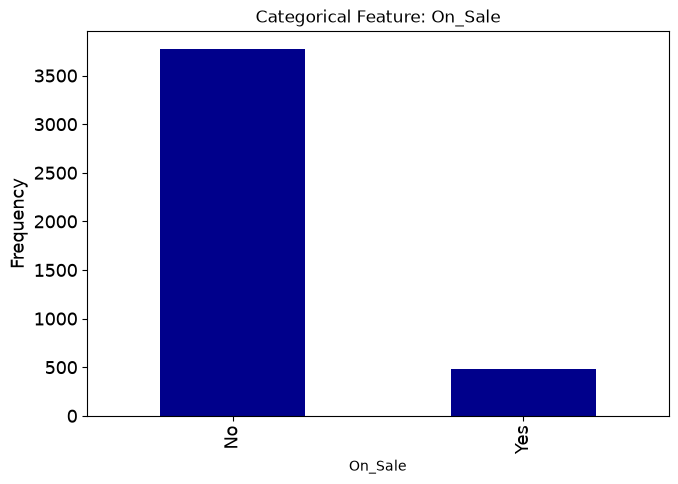

In [126]:
krisolisutils.data_viz(abt.select_dtypes(include=[np.number]))
krisolisutils.data_viz(abt.select_dtypes(include=[object]))
# krisolisutils.data_viz(abt)

### Data Export

Once we have finished cleaning our data, we will save the cleaned ABT as a new CSV file for later analysis

In [127]:
outfile_name = "urban_wear_transactions_clean.csv"
abt.to_csv(outfile_name)

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Simple Data Analysis with Pandas

In [128]:
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS
import matplotlib # TO PLOT
import matplotlib.pyplot as plt # TO PLOT

# this line is needed to ensure plots will appear in the notebook
%matplotlib inline

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format 

### Data Loading

For this notebook, we will use the **cleaned version** of the retail transaction dataset which we created in Demo Notebook 3 and is stored in the CSV file `urban_wear_transactions_clean.csv`

In [129]:
datafile_name = "urban_wear_transactions_clean.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first 10 rows
abt.head(10)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


### Sorting Data

Often we might want to sort values, either in a single column in a DataFrame, or to sort an entire DataFrame based on one or more columns.

To sort a single column, we access the column and then call the associated `sort_values` method.

In [130]:
# get the total cost, lowest to highest
abt["Total_Cost"].sort_values()

Transaction_ID
T_ID_577832     3.67
T_ID_580160     3.67
T_ID_578091     3.67
T_ID_553952     3.67
T_ID_563432     3.67
               ...  
T_ID_550134   289.25
T_ID_550539   289.25
T_ID_564065   289.25
T_ID_561047   289.25
T_ID_546917   289.25
Name: Total_Cost, Length: 4258, dtype: float64

By default, values are ordered in ascending order. We can sort in descending order by specifying the argument `ascending=False`

In [131]:
# get the total cost, highest to lowest
abt["Total_Cost"].sort_values(ascending=False)

Transaction_ID
T_ID_546917   289.25
T_ID_552280   289.25
T_ID_569262   289.25
T_ID_561047   289.25
T_ID_551148   289.25
               ...  
T_ID_543600     3.67
T_ID_556258     3.67
T_ID_550641     3.67
T_ID_578289     3.67
T_ID_540387     3.67
Name: Total_Cost, Length: 4258, dtype: float64

We could just show the top-20 highest values by using `sort_values` together with the `head` method

In [132]:
abt["Total_Cost"].sort_values(ascending=False).head(20)

Transaction_ID
T_ID_546917   289.25
T_ID_552280   289.25
T_ID_569262   289.25
T_ID_561047   289.25
T_ID_551148   289.25
T_ID_560554   289.25
T_ID_569664   289.25
T_ID_565784   289.25
T_ID_545435   289.25
T_ID_555556   289.25
T_ID_564065   289.25
T_ID_550134   289.25
T_ID_550539   289.25
T_ID_555400   280.80
T_ID_557057   280.80
T_ID_549015   280.80
T_ID_580397   280.80
T_ID_551390   280.80
T_ID_538201   280.80
T_ID_566558   280.80
Name: Total_Cost, dtype: float64

We can sort all the rows in an entire DataFrame, again using the associated `sort_values` method and specifying the `by` argument to specify the column on which to sort on

In [133]:
# sort by Customer_ID
abt.sort_values(by="Customer_ID")

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_562032,04/08/2019,C_ID_38584,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,29.00,11.60,1,29.00,17.40,29.00,11.60
T_ID_573511,11/11/2019,C_ID_38584,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_541998,13/02/2019,C_ID_38587,P_ID_100112,Homeware,Mola Headlamp,Design,No Campaign,25.80,0.00,No,43.00,17.20,2,43.00,51.60,86.00,34.40
T_ID_539318,25/01/2019,C_ID_38587,P_ID_100113,Homeware,Dawson Trolley,Design,No Campaign,34.20,0.00,No,57.00,22.80,1,57.00,34.20,57.00,22.80
T_ID_543037,22/02/2019,C_ID_38593,P_ID_100096,Children,Fluro Shorts Two Pack,Boys_wear,No Campaign,8.57,0.00,No,17.50,8.93,4,17.50,34.30,70.00,35.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_575668,28/11/2019,C_ID_57134,P_ID_100085,Children,Blue Floral Embroidered Mac,Girls_wear,No Campaign,17.15,0.00,No,35.00,17.85,1,35.00,17.15,35.00,17.85
T_ID_578262,23/12/2019,C_ID_57134,P_ID_100103,Homeware,1000 Thread Count Cotton Sateen Collection,Bed_Bath,No Campaign,57.85,0.00,No,89.00,31.15,4,89.00,231.40,356.00,124.60
T_ID_573093,06/11/2019,C_ID_57134,P_ID_100089,Children,White Puff Sleeve T-shirt Five Pack,Girls_wear,No Campaign,10.54,0.00,No,21.50,10.96,2,21.50,21.07,43.00,21.93


We can also specify a list of multiple columns to sort by, which can be used to resolve ties

In [134]:
# sort by Customer_ID, then by Product_ID
abt.sort_values(by=["Customer_ID", "Product_ID"])

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_562032,04/08/2019,C_ID_38584,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,29.00,11.60,1,29.00,17.40,29.00,11.60
T_ID_573511,11/11/2019,C_ID_38584,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_541998,13/02/2019,C_ID_38587,P_ID_100112,Homeware,Mola Headlamp,Design,No Campaign,25.80,0.00,No,43.00,17.20,2,43.00,51.60,86.00,34.40
T_ID_539318,25/01/2019,C_ID_38587,P_ID_100113,Homeware,Dawson Trolley,Design,No Campaign,34.20,0.00,No,57.00,22.80,1,57.00,34.20,57.00,22.80
T_ID_543037,22/02/2019,C_ID_38593,P_ID_100096,Children,Fluro Shorts Two Pack,Boys_wear,No Campaign,8.57,0.00,No,17.50,8.93,4,17.50,34.30,70.00,35.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_575668,28/11/2019,C_ID_57134,P_ID_100085,Children,Blue Floral Embroidered Mac,Girls_wear,No Campaign,17.15,0.00,No,35.00,17.85,1,35.00,17.15,35.00,17.85
T_ID_573093,06/11/2019,C_ID_57134,P_ID_100089,Children,White Puff Sleeve T-shirt Five Pack,Girls_wear,No Campaign,10.54,0.00,No,21.50,10.96,2,21.50,21.07,43.00,21.93
T_ID_578262,23/12/2019,C_ID_57134,P_ID_100103,Homeware,1000 Thread Count Cotton Sateen Collection,Bed_Bath,No Campaign,57.85,0.00,No,89.00,31.15,4,89.00,231.40,356.00,124.60


In [135]:
# sort by Customer_ID first (ascending order), then Product_ID (descending order)
abt.sort_values(by=["Customer_ID", "Product_ID"], ascending=[True, False])

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_573511,11/11/2019,C_ID_38584,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_562032,04/08/2019,C_ID_38584,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,29.00,11.60,1,29.00,17.40,29.00,11.60
T_ID_539318,25/01/2019,C_ID_38587,P_ID_100113,Homeware,Dawson Trolley,Design,No Campaign,34.20,0.00,No,57.00,22.80,1,57.00,34.20,57.00,22.80
T_ID_541998,13/02/2019,C_ID_38587,P_ID_100112,Homeware,Mola Headlamp,Design,No Campaign,25.80,0.00,No,43.00,17.20,2,43.00,51.60,86.00,34.40
T_ID_543037,22/02/2019,C_ID_38593,P_ID_100096,Children,Fluro Shorts Two Pack,Boys_wear,No Campaign,8.57,0.00,No,17.50,8.93,4,17.50,34.30,70.00,35.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_573093,06/11/2019,C_ID_57134,P_ID_100089,Children,White Puff Sleeve T-shirt Five Pack,Girls_wear,No Campaign,10.54,0.00,No,21.50,10.96,2,21.50,21.07,43.00,21.93
T_ID_575668,28/11/2019,C_ID_57134,P_ID_100085,Children,Blue Floral Embroidered Mac,Girls_wear,No Campaign,17.15,0.00,No,35.00,17.85,1,35.00,17.15,35.00,17.85
T_ID_541854,12/02/2019,C_ID_57134,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,29.00,11.60,1,29.00,17.40,29.00,11.60


### Now you try...

- Sort the rows in the transaction data in descending order, based on the date of the transaction and then by highest 'Total_Profit'

In [136]:
abt.sort_values(by=["Transaction_Date", "Total_Profit"], ascending=[False, False])

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579345,31/12/2019,C_ID_39771,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,5,35.00,108.50,175.00,66.50
T_ID_579289,31/12/2019,C_ID_44560,P_ID_100010,Men,Black Signature Point Court Shoes,Shoes,No Campaign,24.20,0.00,No,44.00,19.80,2,44.00,48.40,88.00,39.60
T_ID_579287,31/12/2019,C_ID_42175,P_ID_100092,Children,Blue Stripe Snuggle Fit Pyjamas,Boys_wear,No Campaign,9.06,0.00,No,18.50,9.44,4,18.50,36.26,74.00,37.74
T_ID_579328,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,7,11.50,48.30,80.50,32.20
T_ID_579391,31/12/2019,C_ID_44534,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,No Campaign,8.57,0.00,No,17.50,8.93,3,17.50,25.73,52.50,26.77
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_579491,01/01/2019,C_ID_46009,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,No Campaign,8.57,0.00,No,17.50,8.93,1,17.50,8.57,17.50,8.93
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41


- Select the columns ['Cost_Per_Unit', 'Price_Per_Unit', 'Profit_Per_Unit', 'Total_Profit'] from the DataFrame and report the top-20 transactions sorted in descending order by 'Total_Profit'
(Hint: Recall how we selected columns in Demo Notebook 1)

In [137]:
selection = abt[['Cost_Per_Unit', 'Price_Per_Unit', 'Profit_Per_Unit', 'Total_Profit']]
sorted_selection = selection.sort_values(by="Total_Profit", ascending=False)
sorted_selection.head(20)

,Cost_Per_Unit,Price_Per_Unit,Profit_Per_Unit,Total_Profit
Transaction_ID,,,,
T_ID_557676,63.60,106.00,42.40,169.60
T_ID_572703,63.60,106.00,42.40,169.60
T_ID_562607,63.60,106.00,42.40,169.60
T_ID_577264,63.60,106.00,42.40,169.60
T_ID_541121,63.60,106.00,42.40,169.60
T_ID_553901,63.60,106.00,42.40,169.60
T_ID_542643,63.60,106.00,42.40,169.60
T_ID_578333,63.60,106.00,42.40,169.60
T_ID_569024,63.60,106.00,42.40,169.60


### Frequency Tables

Recall, frequency tables in Pandas are tables that show the counts for each unique value in a single categorical column in our ABT

In [138]:
abt["Prod_Cat"].value_counts()

Prod_Cat
Children    1784
Men         1389
Homeware     892
Women        193
Name: count, dtype: int64

In [139]:
abt["Campaign"].value_counts()

Campaign
No Campaign           3772
New Customer Offer     486
Name: count, dtype: int64

### Cross Tabulations

Instead of just looking at one column, we will often want to examine the relationship between multiple columns in our ABT. 

We can compare two **categorical columns** by calling the `pd.crosstab` function and passing in the two relevant columns from the DataFrame.

For example, we might want to look at the relationship between product category and marketing campaign in our transactions.

In [140]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"])

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,254,1530
Homeware,46,846
Men,78,1311
Women,108,85


We can normalise counts within a frequency table - notice different behaviour depending on different values of the `normalize` parameter passed to `pd.crosstab`

In [141]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"], normalize="all") 
# proportion of the total observations belonging to each combination 

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,0.06,0.36
Homeware,0.01,0.20
Men,0.02,0.31
Women,0.03,0.02


In [142]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"], normalize="index") 
# distribution of campaigns within each product category

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,0.14,0.86
Homeware,0.05,0.95
Men,0.06,0.94
Women,0.56,0.44


In [143]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"], normalize="columns") # distribution of product categories within each campaign

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,0.52,0.41
Homeware,0.09,0.22
Men,0.16,0.35
Women,0.22,0.02


Adding `margins` creates summary totals across rows and columns

In [144]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"], margins=True)

Campaign,New Customer Offer,No Campaign,All
Prod_Cat,,,
Children,254,1530,1784
Homeware,46,846,892
Men,78,1311,1389
Women,108,85,193
All,486,3772,4258


In [145]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"], normalize="index", margins=True)

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,0.14,0.86
Homeware,0.05,0.95
Men,0.06,0.94
Women,0.56,0.44
All,0.11,0.89


### Now you try...

 - Create a **frequency table** from the transaction date for the 'On_Sale' column

In [146]:
abt["On_Sale"].value_counts()

On_Sale
No     3772
Yes     486
Name: count, dtype: int64

- Using the transaction data, build a **cross-tabulation** of the number of transactions involving different product sub-categories and whether the products involved in a transaction were on sale.

 Which product sub-category was most frequently on sale?

In [147]:
A = pd.crosstab(abt["Prod_Sub_Cat"], abt["On_Sale"])
A

On_Sale,No,Yes
Prod_Sub_Cat,,
Bed_Bath,318,27
Boys_wear,751,180
Design,528,19
Dresses,69,27
Girls_wear,779,74
Jeans,381,34
Shirts,703,34
Shoes,127,28
Tops,13,61


In [148]:
A["Yes"].idxmax()

'Boys_wear'

- Build a normalised cross tabulation of product sub-categories and marketing campaign.

 Is there an even distribution for product sub-categories across the campaign values?

In [149]:
B = pd.crosstab(abt["Prod_Sub_Cat"], abt["Campaign"], normalize="columns")
B
# pd.crosstab(abt["Prod_Sub_Cat"], abt["Campaign"], normalize="index")

Campaign,New Customer Offer,No Campaign
Prod_Sub_Cat,,
Bed_Bath,0.06,0.08
Boys_wear,0.37,0.20
Design,0.04,0.14
Dresses,0.06,0.02
Girls_wear,0.15,0.21
Jeans,0.07,0.10
Shirts,0.07,0.19
Shoes,0.06,0.03
Tops,0.13,0.00


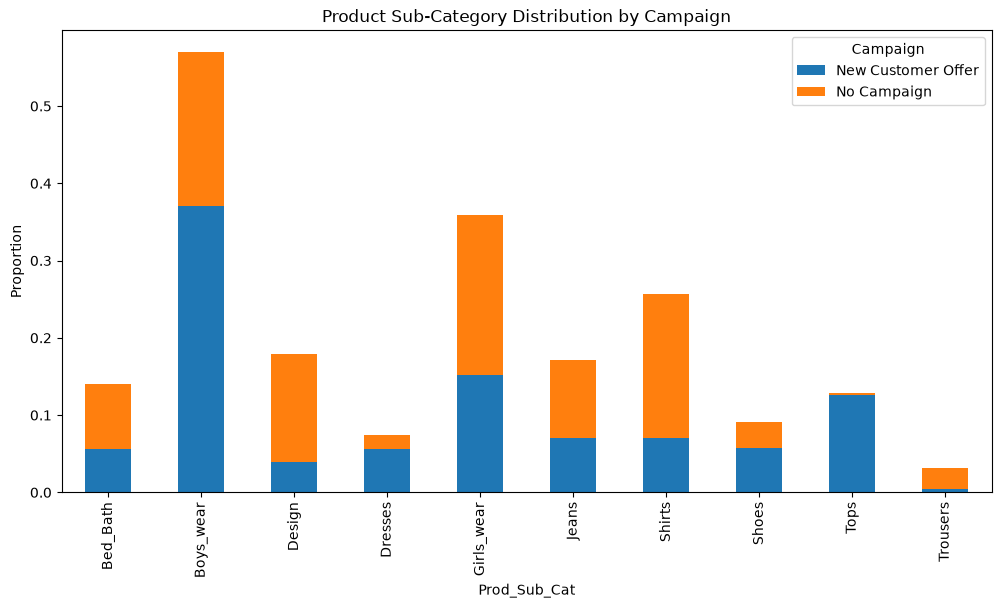

In [150]:
B.plot(kind="bar", 
       figsize=(12, 6),
       ylabel="Proportion", 
       title="Product Sub-Category Distribution by Campaign",
       stacked=True)
plt.show()

### Pivot Tables

A pivot table is a real data analysis workhorse allowing us to see summary statistics for different values grouped by the values of one or more columns in a DataFrame.

We can compare two columns by calling the `pd.pivot_table` function, passing in the DataFrame and the two column names. 

By default, the resulting table will show the mean values for each of the categories in the second column.

For example, we might want to look at the relationship between the cost per unit and product category for transactions. 

The values in the table are the mean for each category.

In [151]:
pd.pivot_table(abt, 
               index="Prod_Cat",
               values="Cost_Per_Unit")

,Cost_Per_Unit
Prod_Cat,
Children,9.68
Homeware,33.15
Men,22.73
Women,16.99


We can further partition by another column. 

For example, we could look at the relationship between cost per unit and product category, in terms of the type of marketing campaign involved in the transaction.

In [152]:
pd.pivot_table(abt, 
               index="Prod_Cat",
               columns="Campaign",
               values="Cost_Per_Unit")

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,9.86,9.65
Homeware,31.88,33.22
Men,21.51,22.81
Women,19.01,14.43


We can also add different aggregation functions, by specifying a value for the `aggfunc` argument (e.g. `min`, `max`, `mean`) 

In [153]:
pd.pivot_table(abt, 
               index="Prod_Cat",
               columns="Campaign",
               values="Cost_Per_Unit", 
               aggfunc="max")

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,21.07,18.13
Homeware,63.60,63.60
Men,47.85,47.85
Women,47.85,35.75


In [154]:
pd.pivot_table(abt, 
               index="Prod_Cat", 
               columns="Campaign",
               values="Cost_Per_Unit", 
               aggfunc="min")

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,3.67,3.67
Homeware,6.90,6.90
Men,12.24,12.24
Women,9.60,9.60


We can also add multiple aggregation functions to create a more complex pivot table. We do this by passing a list of values for the `aggfunc` argument

In [155]:
pd.pivot_table(abt, 
               index="Prod_Cat", 
               columns="Campaign",
               values="Cost_Per_Unit", 
               aggfunc=["min", "max", "mean"])

min                            max              \
Campaign New Customer Offer No Campaign New Customer Offer No Campaign   
Prod_Cat                                                                 
Children               3.67        3.67              21.07       18.13   
Homeware               6.90        6.90              63.60       63.60   
Men                   12.24       12.24              47.85       47.85   
Women                  9.60        9.60              47.85       35.75   

                       mean              
Campaign New Customer Offer No Campaign  
Prod_Cat                                 
Children               9.86        9.65  
Homeware              31.88       33.22  
Men                   21.51       22.81  
Women                 19.01       14.43

Finally, we can create a pivot table considering multiple numeric columns by passing a list of column names for the `values` argument

In [156]:
pd.pivot_table(abt, 
               index="Prod_Cat",
               values=["Cost_Per_Unit", "Profit_Per_Unit"]) 

,Cost_Per_Unit,Profit_Per_Unit
Prod_Cat,,
Children,9.68,10.08
Homeware,33.15,19.88
Men,22.73,15.30
Women,16.99,19.58


In [157]:
pd.pivot_table(abt,
               index="Prod_Cat",
               values=["Cost_Per_Unit", "Profit_Per_Unit"], 
               aggfunc=["min", "max", "mean"])

min                           max                  \
         Cost_Per_Unit Profit_Per_Unit Cost_Per_Unit Profit_Per_Unit   
Prod_Cat                                                               
Children          3.67            3.83         21.07           21.93   
Homeware          6.90            4.60         63.60           42.40   
Men              12.24            8.93         47.85           39.15   
Women             9.60           11.25         47.85           39.15   

                  mean                  
         Cost_Per_Unit Profit_Per_Unit  
Prod_Cat                                
Children          9.68           10.08  
Homeware         33.15           19.88  
Men              22.73           15.30  
Women            16.99           19.58

### Now you try...

- Create a **pivot table** to calculate the average 'Total_Profit' for different product sub-categories

In [158]:
pd.pivot_table(abt,
               index="Prod_Sub_Cat",
               values="Total_Profit",
               aggfunc="mean")
# pd.pivot_table(abt, 
#                values="Total_Profit", 
#                index="Prod_Sub_Cat")

,Total_Profit
Prod_Sub_Cat,
Bed_Bath,68.40
Boys_wear,21.12
Design,30.44
Dresses,14.59
Girls_wear,14.10
Jeans,14.65
Shirts,21.07
Shoes,27.56
Tops,29.46


- Create a **pivot table** to report the minimum, maximum and average 'Total_Profit', as broken down by product sub-category and whether the product was on sale

In [159]:
pd.pivot_table(abt, 
               index=["Prod_Sub_Cat", "On_Sale"],
               values="Total_Profit", 
               aggfunc=["min", "max", "mean"])
# pd.pivot_table(abt, 
#                values="Total_Profit", 
#                index="Prod_Sub_Cat",
#                columns="On_Sale",
#                aggfunc=["min", "max", "mean"])

min          max         mean
                     Total_Profit Total_Profit Total_Profit
Prod_Sub_Cat On_Sale                                       
Bed_Bath     No              0.00       155.75        72.20
             Yes             8.25        72.00        23.69
Boys_wear    No              0.00        47.17        23.44
             Yes             0.00        37.92        11.46
Design       No              0.00       169.60        30.82
             Yes             3.45        77.40        19.80
Dresses      No             11.25        25.50        13.83
             Yes             9.00        29.60        16.53
Girls_wear   No              0.00        48.96        14.23
             Yes             3.08        39.36        12.72
Jeans        No              0.00        30.40        14.88
             Yes             8.70        28.80        12.06
Shirts       No              0.00        71.82        21.42
             Yes             6.58        52.92        13.76
Shoes        No              0.00        77.40        29.52
             Yes             0.00        38.85        18.69
Tops         No             14.40        66.00        32.49
             Yes            12.00        85.50        28.82
Trousers     No              0.00        82.32        26.32
             Yes             9.36        22.23        15.79

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Data Manipulation Operations

This notebook explores a number of common data manipulation operations in Pandas, specifically:

- Filtering columns
- Filtering rows
- Sampling data
- Deriving new features

In [160]:
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format 

### Data Loading

For this notebook, we will use the **cleaned version** of the retail transaction dataset which we created in Demo Notebook 3 and is stored in the CSV file `urban_wear_transactions_clean.csv`

In [161]:
datafile_name = "urban_wear_transactions_clean.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first few rows
abt.head(10)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,No,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,No,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,No,26.00,13.26,2,26.00,25.48,52.00,26.52


### Filtering Columns

As we have seen, accessing a column in a DataFrame is simply a matter of using the name of the column (similar to dictionary selection). 

This returns back a Series corresponding to the column.

In [162]:
descriptions = abt["Prod_Description"]
descriptions.head(10)

Transaction_ID
T_ID_579441              White Colour Block T-Shirt
T_ID_536370    Multi Short Sleeve Character T-shirt
T_ID_536367                     White Polo Two Pack
T_ID_579462                Feathers Printed Bed Set
T_ID_579472                 Pink Cheque Shirt Dress
T_ID_536371                 White Tie and Shirt Set
T_ID_536425                    Harriet Chambray Top
T_ID_536526                  Pennsylvania Notebooks
T_ID_536405           Lilac/Mint Long Sleeve Shirts
T_ID_579508     White Short Sleeve Bird Print Shirt
Name: Prod_Description, dtype: str

If we want to keep single columns as a DataFrame, rather than a Series, we provide the name in a single-item list

In [163]:
descriptions = abt[["Prod_Description"]]
descriptions.head(10)

,Prod_Description
Transaction_ID,
T_ID_579441,White Colour Block T-Shirt
T_ID_536370,Multi Short Sleeve Character T-shirt
T_ID_536367,White Polo Two Pack
T_ID_579462,Feathers Printed Bed Set
T_ID_579472,Pink Cheque Shirt Dress
T_ID_536371,White Tie and Shirt Set
T_ID_536425,Harriet Chambray Top
T_ID_536526,Pennsylvania Notebooks
T_ID_536405,Lilac/Mint Long Sleeve Shirts


We can easily select multiple columns by passing a list of column names

In [164]:
cat_descriptions = abt[["Prod_Cat", "Prod_Description"]]
cat_descriptions.head(10)

,Prod_Cat,Prod_Description
Transaction_ID,,
T_ID_579441,Children,White Colour Block T-Shirt
T_ID_536370,Children,Multi Short Sleeve Character T-shirt
T_ID_536367,Children,White Polo Two Pack
T_ID_579462,Homeware,Feathers Printed Bed Set
T_ID_579472,Children,Pink Cheque Shirt Dress
T_ID_536371,Men,White Tie and Shirt Set
T_ID_536425,Women,Harriet Chambray Top
T_ID_536526,Homeware,Pennsylvania Notebooks
T_ID_536405,Children,Lilac/Mint Long Sleeve Shirts


We can also specify the columns that we do not want to include

In [165]:
cols_not_required = ["Campaign", "Cost_Per_Unit", "Discount", "On_Sale", "Price_Per_Unit", "Profit_Per_Unit"]
cols_required = abt.columns.difference(cols_not_required)
selection = abt[cols_required]
selection.head(10)

,Customer_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Product_ID,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit,Transaction_Date
Transaction_ID,,,,,,,,,,,
T_ID_579441,C_ID_38950,Children,White Colour Block T-Shirt,Boys_wear,P_ID_100091,3,22.50,33.08,67.50,34.42,01/01/2019
T_ID_536370,C_ID_39321,Children,Multi Short Sleeve Character T-shirt,Boys_wear,P_ID_100097,1,16.50,8.09,16.50,8.41,01/01/2019
T_ID_536367,C_ID_40771,Children,White Polo Two Pack,Girls_wear,P_ID_100081,1,7.50,3.67,7.50,3.83,01/01/2019
T_ID_579462,C_ID_41284,Homeware,Feathers Printed Bed Set,Bed_Bath,P_ID_100108,2,35.00,45.50,70.00,24.50,01/01/2019
T_ID_579472,C_ID_42253,Children,Pink Cheque Shirt Dress,Girls_wear,P_ID_100084,1,16.50,8.09,16.50,8.41,01/01/2019
T_ID_536371,C_ID_42962,Men,White Tie and Shirt Set,Shirts,P_ID_100059,1,35.00,21.70,35.00,13.30,01/01/2019
T_ID_536425,C_ID_42993,Women,Harriet Chambray Top,Tops,P_ID_100023,1,35.00,14.00,35.00,21.00,01/01/2019
T_ID_536526,C_ID_43753,Homeware,Pennsylvania Notebooks,Design,P_ID_100114,2,11.50,13.80,23.00,9.20,01/01/2019
T_ID_536405,C_ID_43890,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,P_ID_100086,2,26.00,25.48,52.00,26.52,01/01/2019


Columns in a DataFrame can be fully removed using `del` operator. Use this carefully!

In [166]:
del abt["On_Sale"]
# check the list of columns after deletion
abt.columns

Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant', 'Sale_Amount',
       'Total_Cost', 'Total_Product_Sale', 'Total_Profit'],
      dtype='str')

### Filtering Rows

As we have seen, Pandas provides ways to access different rows in a DataFrame.

We can access one or more rows based on their index label(s).

In [167]:
# get the row for the specified transaction, based on a label
abt.loc["T_ID_579508"]

Transaction_Date                               01/01/2019
Customer_ID                                    C_ID_44577
Product_ID                                    P_ID_100052
Prod_Cat                                              Men
Prod_Description      White Short Sleeve Bird Print Shirt
Prod_Sub_Cat                                       Shirts
Campaign                                      No Campaign
Cost_Per_Unit                                       17.98
Discount                                             0.00
Price_Per_Unit                                      29.00
Profit_Per_Unit                                     11.02
Quant                                                   1
Sale_Amount                                         29.00
Total_Cost                                          17.98
Total_Product_Sale                                  29.00
Total_Profit                                        11.02
Name: T_ID_579508, dtype: object

In [168]:
# get several different rows, based on a list of labels
abt.loc[["T_ID_537211","T_ID_536570"]]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_537211,08/01/2019,C_ID_50446,P_ID_100083,Children,No description,Girls_wear,No Campaign,8.57,0.00,17.50,8.93,1,17.50,8.57,17.50,8.93
T_ID_536570,02/01/2019,C_ID_45300,P_ID_100051,Men,Navy/White Long Sleeve Gingham Cheque Shirt,Shirts,No Campaign,17.98,0.00,29.00,11.02,1,29.00,17.98,29.00,11.02


Or we can access one or more rows based on their row positions

In [169]:
# get the first row, based on position
abt.iloc[0]

Transaction_Date                      01/01/2019
Customer_ID                           C_ID_38950
Product_ID                           P_ID_100091
Prod_Cat                                Children
Prod_Description      White Colour Block T-Shirt
Prod_Sub_Cat                           Boys_wear
Campaign                             No Campaign
Cost_Per_Unit                              11.03
Discount                                    0.00
Price_Per_Unit                             22.50
Profit_Per_Unit                            11.47
Quant                                          3
Sale_Amount                                22.50
Total_Cost                                 33.08
Total_Product_Sale                         67.50
Total_Profit                               34.42
Name: T_ID_579441, dtype: object

In [170]:
# access the last row of the DataFrame, using negative positions
abt.iloc[-1]

Transaction_Date                                31/12/2019
Customer_ID                                     C_ID_56618
Product_ID                                     P_ID_100098
Prod_Cat                                          Children
Prod_Description      Navy Colourblock Crew and Jogger Set
Prod_Sub_Cat                                     Boys_wear
Campaign                                New Customer Offer
Cost_Per_Unit                                         8.57
Discount                                              0.10
Price_Per_Unit                                       17.50
Profit_Per_Unit                                       8.93
Quant                                                    2
Sale_Amount                                          15.75
Total_Cost                                           17.15
Total_Product_Sale                                   31.50
Total_Profit                                         14.35
Name: T_ID_579301, dtype: object

In [171]:
# access a slice of the DataFrame
abt.iloc[4:9]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,26.00,13.26,2,26.00,25.48,52.00,26.52


We often want to filter the rows in a DataFrame by applying some condition based on a column in the data. 

We can apply a conditional statement to a column in a DataFrame. 

This returns a Series of Boolean values indicating which rows satisfy the conditions.

In [172]:
abt["Total_Profit"] > 25

Transaction_ID
T_ID_579441     True
T_ID_536370    False
T_ID_536367    False
T_ID_579462    False
T_ID_579472    False
               ...  
T_ID_579402    False
T_ID_579431    False
T_ID_579328     True
T_ID_579288    False
T_ID_579301    False
Name: Total_Profit, Length: 4258, dtype: bool

In [173]:
abt["Prod_Cat"] == "Homeware"

Transaction_ID
T_ID_579441    False
T_ID_536370    False
T_ID_536367    False
T_ID_579462     True
T_ID_579472    False
               ...  
T_ID_579402    False
T_ID_579431    False
T_ID_579328     True
T_ID_579288    False
T_ID_579301    False
Name: Prod_Cat, Length: 4258, dtype: bool

We can use this Series of Boolean values to make a selection from a DataFrame via the `loc` operator. 

The output is a DataFrame with the relevant rows.

In [174]:
abt[abt["Total_Profit"] > 25]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,26.00,13.26,2,26.00,25.48,52.00,26.52
T_ID_579457,01/01/2019,C_ID_46325,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,72.00,25.20,3,72.00,140.40,216.00,75.60
T_ID_536388,01/01/2019,C_ID_50781,P_ID_100007,Women,White Ric-Rac Dress,Dresses,No Campaign,25.50,0.00,51.00,25.50,1,51.00,25.50,51.00,25.50
T_ID_536420,01/01/2019,C_ID_51821,P_ID_100020,Women,Lodge Women's Shirt,Tops,New Customer Offer,14.80,0.10,37.00,22.20,2,33.30,29.60,66.60,37.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_579345,31/12/2019,C_ID_39771,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,35.00,13.30,5,35.00,108.50,175.00,66.50
T_ID_579287,31/12/2019,C_ID_42175,P_ID_100092,Children,Blue Stripe Snuggle Fit Pyjamas,Boys_wear,No Campaign,9.06,0.00,18.50,9.44,4,18.50,36.26,74.00,37.74
T_ID_579391,31/12/2019,C_ID_44534,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,No Campaign,8.57,0.00,17.50,8.93,3,17.50,25.73,52.50,26.77


In [175]:
abt.loc[abt["Prod_Cat"] == "Homeware"]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_579457,01/01/2019,C_ID_46325,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,72.00,25.20,3,72.00,140.40,216.00,75.60
T_ID_579470,01/01/2019,C_ID_51715,P_ID_100118,Homeware,Set of 3 Animal Canvas Prints,Design,No Campaign,14.10,0.00,23.50,9.40,1,23.50,14.10,23.50,9.40
T_ID_579550,02/01/2019,C_ID_39468,P_ID_100110,Homeware,Double Wall Mug,Design,No Campaign,7.50,0.00,12.50,5.00,1,12.50,7.50,12.50,5.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_579179,30/12/2019,C_ID_53865,P_ID_100103,Homeware,1000 Thread Count Cotton Sateen Collection,Bed_Bath,No Campaign,57.85,0.00,89.00,31.15,3,89.00,173.55,267.00,93.45
T_ID_579155,30/12/2019,C_ID_56565,P_ID_100118,Homeware,Set of 3 Animal Canvas Prints,Design,No Campaign,14.10,0.00,23.50,9.40,1,23.50,14.10,23.50,9.40
T_ID_579272,31/12/2019,C_ID_44559,P_ID_100110,Homeware,Double Wall Mug,Design,No Campaign,7.50,0.00,12.50,5.00,1,12.50,7.50,12.50,5.00


We can combine several different conditions using a Boolean operator such as AND (`&`) or OR (`|`). 

Note that each condition is surrounded by parentheses

In [176]:
abt.loc[(abt["Total_Profit"] > 25) 
	| (abt["Prod_Cat"] == "Homeware")]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,26.00,13.26,2,26.00,25.48,52.00,26.52
T_ID_579457,01/01/2019,C_ID_46325,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,72.00,25.20,3,72.00,140.40,216.00,75.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_579391,31/12/2019,C_ID_44534,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,No Campaign,8.57,0.00,17.50,8.93,3,17.50,25.73,52.50,26.77
T_ID_579272,31/12/2019,C_ID_44559,P_ID_100110,Homeware,Double Wall Mug,Design,No Campaign,7.50,0.00,12.50,5.00,1,12.50,7.50,12.50,5.00
T_ID_579289,31/12/2019,C_ID_44560,P_ID_100010,Men,Black Signature Point Court Shoes,Shoes,No Campaign,24.20,0.00,44.00,19.80,2,44.00,48.40,88.00,39.60


In [177]:
# select rows which satisfy both 1st condition AND 2nd condition
abt.loc[(abt["Total_Profit"] > 25) & (abt["Prod_Cat"] == "Homeware")]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_579457,01/01/2019,C_ID_46325,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,72.00,25.20,3,72.00,140.40,216.00,75.60
T_ID_536562,02/01/2019,C_ID_42087,P_ID_100101,Homeware,Ultimate Feels Like Down Duvet,Bed_Bath,No Campaign,44.20,0.00,68.00,23.80,2,68.00,88.40,136.00,47.60
T_ID_579523,02/01/2019,C_ID_49696,P_ID_100115,Homeware,Soft Velour Eyelet Lined Curtains,Design,No Campaign,63.60,0.00,106.00,42.40,3,106.00,190.80,318.00,127.20
T_ID_536804,04/01/2019,C_ID_43846,P_ID_100102,Homeware,Starlight Rug,Bed_Bath,No Campaign,53.95,0.00,83.00,29.05,1,83.00,53.95,83.00,29.05
T_ID_580047,05/01/2019,C_ID_40590,P_ID_100109,Homeware,Crinkle Velvet Bed Set,Bed_Bath,No Campaign,35.75,0.00,55.00,19.25,2,55.00,71.50,110.00,38.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_578944,28/12/2019,C_ID_50015,P_ID_100116,Homeware,Lattice Runner,Design,No Campaign,51.60,0.00,86.00,34.40,1,86.00,51.60,86.00,34.40
T_ID_579145,29/12/2019,C_ID_45615,P_ID_100109,Homeware,Crinkle Velvet Bed Set,Bed_Bath,No Campaign,35.75,0.00,55.00,19.25,2,55.00,71.50,110.00,38.50
T_ID_579256,30/12/2019,C_ID_41715,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,72.00,25.20,2,72.00,93.60,144.00,50.40


In [178]:
# select rows which satisfy either 1st condition OR 2nd condition
abt.loc[(abt["Total_Profit"] > 25) | (abt["Prod_Cat"] == "Homeware")]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_536526,01/01/2019,C_ID_43753,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,11.50,4.60,2,11.50,13.80,23.00,9.20
T_ID_536405,01/01/2019,C_ID_43890,P_ID_100086,Children,Lilac/Mint Long Sleeve Shirts,Girls_wear,No Campaign,12.74,0.00,26.00,13.26,2,26.00,25.48,52.00,26.52
T_ID_579457,01/01/2019,C_ID_46325,P_ID_100106,Homeware,Cream Vintage Bin,Bed_Bath,No Campaign,46.80,0.00,72.00,25.20,3,72.00,140.40,216.00,75.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_579391,31/12/2019,C_ID_44534,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,No Campaign,8.57,0.00,17.50,8.93,3,17.50,25.73,52.50,26.77
T_ID_579272,31/12/2019,C_ID_44559,P_ID_100110,Homeware,Double Wall Mug,Design,No Campaign,7.50,0.00,12.50,5.00,1,12.50,7.50,12.50,5.00
T_ID_579289,31/12/2019,C_ID_44560,P_ID_100010,Men,Black Signature Point Court Shoes,Shoes,No Campaign,24.20,0.00,44.00,19.80,2,44.00,48.40,88.00,39.60


We can also use the `isin` method when filtering to match a categorical column to one of a list of values

In [179]:
abt.loc[abt["Prod_Cat"].isin(["Women", "Men"])]

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_536371,01/01/2019,C_ID_42962,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,35.00,13.30,1,35.00,21.70,35.00,13.30
T_ID_536425,01/01/2019,C_ID_42993,P_ID_100023,Women,Harriet Chambray Top,Tops,No Campaign,14.00,0.00,35.00,21.00,1,35.00,14.00,35.00,21.00
T_ID_579508,01/01/2019,C_ID_44577,P_ID_100052,Men,White Short Sleeve Bird Print Shirt,Shirts,No Campaign,17.98,0.00,29.00,11.02,1,29.00,17.98,29.00,11.02
T_ID_536386,01/01/2019,C_ID_50090,P_ID_100008,Women,Black Tea Dress,Dresses,No Campaign,18.50,0.00,37.00,18.50,1,37.00,18.50,37.00,18.50
T_ID_536388,01/01/2019,C_ID_50781,P_ID_100007,Women,White Ric-Rac Dress,Dresses,No Campaign,25.50,0.00,51.00,25.50,1,51.00,25.50,51.00,25.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_579267,30/12/2019,C_ID_46753,P_ID_100031,Men,Navy Chino Trousers,Trousers,No Campaign,18.36,0.00,36.00,17.64,1,36.00,18.36,36.00,17.64
T_ID_579169,30/12/2019,C_ID_56012,P_ID_100046,Men,Mid Blue Straight Fit Jeans,Jeans,No Campaign,22.80,0.00,38.00,15.20,1,38.00,22.80,38.00,15.20
T_ID_579345,31/12/2019,C_ID_39771,P_ID_100059,Men,White Tie and Shirt Set,Shirts,No Campaign,21.70,0.00,35.00,13.30,5,35.00,108.50,175.00,66.50


### Filtering Rows and Columns

Filtering rows and columns together in a DataFrame can be achieved by using the `loc` operators with a condition and one or more column names

In [180]:
reduced_data = abt.loc[(abt["Total_Profit"] > 25), 
            ["Prod_Cat", "Prod_Description"]]
reduced_data.head(10)

,Prod_Cat,Prod_Description
Transaction_ID,,
T_ID_579441,Children,White Colour Block T-Shirt
T_ID_536405,Children,Lilac/Mint Long Sleeve Shirts
T_ID_579457,Homeware,Cream Vintage Bin
T_ID_536388,Women,White Ric-Rac Dress
T_ID_536420,Women,Lodge Women's Shirt
T_ID_536508,Women,Whitney Pullover
T_ID_579516,Children,Fluro Shorts Two Pack
T_ID_536373,Women,Lunar Cirque Blouse
T_ID_536397,Women,Lodge Women's Shirt


### Now you try...

- Create a subset of the transaction data including just the 'Customer_ID', 'Product_ID', and 'Total_Product_Sale' columns

In [181]:
small1 = abt[["Customer_ID", "Product_ID", "Total_Product_Sale"]]

- Count the number of transactions where the product category is 'Homeware'

In [182]:
small2=abt[abt["Prod_Cat"] == "Homeware"]
# len(small2=abt[abt["Prod_Cat"] == "Homeware"])
small2.shape
# rows = abt.loc[abt["Prod_Cat"] == "Homeware"]
# len(rows)

(892, 16)

- Count the number of transactions where the product category is 'Homeware' **or** the product category is 'Women'

In [183]:
small3=abt.loc[(abt["Prod_Cat"] == "Homeware") | (abt["Prod_Cat"] == "Women")]
small3.shape
# rows = abt.loc[(abt["Prod_Cat"] == "Homeware") | (abt["Prod_Cat"] == "Women")]
# len(rows)

(1085, 16)

- Count the number of transactions where the product category is 'Homeware' **and** the product subcategory is 'Design'

In [184]:
small4=abt.loc[(abt["Prod_Cat"] == "Homeware") & (abt["Prod_Sub_Cat"] == "Design")]
small4.shape
# rows = abt.loc[(abt["Prod_Cat"] == "Homeware") & (abt["Prod_Sub_Cat"] == "Design")]
# len(rows)

(547, 16)

- Create a subset of the transaction data including just the 'Customer_ID', 'Product_ID', and 'Total_Product_Sale' columns, where the product category is 'Homeware'

In [185]:
small5 = abt[[ 'Customer_ID', 'Product_ID', 'Total_Product_Sale']]
small3=small5.loc[(abt["Prod_Cat"] == "Homeware")]
# abt.loc[(abt["Prod_Cat"] == "Homeware"), 
#     ["Customer_ID", "Product_ID", "Total_Product_Sale"]]

### Data Sampling

We often wish to take smaller random samples of a larger dataset. 

The `sample` method associated with a Pandas DataFrame makes this easy.

We can specify the number of rows `n` that we want to randomly sample.

In [186]:
sampled_rows = abt.sample(n=10)
print(sampled_rows.shape)
sampled_rows

(10, 16)


,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_558119,01/07/2019,C_ID_42932,P_ID_100082,Children,Orange/Navy Shorts Three Pack,Girls_wear,No Campaign,8.09,0.00,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_546556,24/03/2019,C_ID_50487,P_ID_100014,Men,Fancy Ballerina Shoes,Shoes,No Campaign,23.65,0.00,43.00,19.35,4,43.00,94.60,172.00,77.40
T_ID_581116,15/01/2019,C_ID_53850,P_ID_100052,Men,White Short Sleeve Bird Print Shirt,Shirts,No Campaign,17.98,0.00,29.00,11.02,1,29.00,17.98,29.00,11.02
T_ID_575162,25/11/2019,C_ID_44243,P_ID_100118,Homeware,Set of 3 Animal Canvas Prints,Design,No Campaign,14.10,0.00,23.50,9.40,1,23.50,14.10,23.50,9.40
T_ID_552479,14/05/2019,C_ID_40065,P_ID_100116,Homeware,Lattice Runner,Design,No Campaign,51.60,0.00,86.00,34.40,2,86.00,103.20,172.00,68.80
T_ID_549997,24/04/2019,C_ID_47465,P_ID_100083,Children,Multi Llama Vests Three Pack,Girls_wear,No Campaign,8.57,0.00,17.50,8.93,1,17.50,8.57,17.50,8.93
T_ID_539001,22/01/2019,C_ID_51103,P_ID_100099,Children,Cobalt Corbed Sandals,Boys_wear,No Campaign,9.06,0.00,18.50,9.44,1,18.50,9.06,18.50,9.44
T_ID_569347,03/10/2019,C_ID_43795,P_ID_100052,Men,White Short Sleeve Bird Print Shirt,Shirts,No Campaign,17.98,0.00,29.00,11.02,1,29.00,17.98,29.00,11.02
T_ID_575340,26/11/2019,C_ID_48390,P_ID_100092,Children,Blue Stripe Snuggle Fit Pyjamas,Boys_wear,No Campaign,9.06,0.00,18.50,9.44,3,18.50,27.20,55.50,28.30


Or can specify the fraction of rows `frac` that we want to randomly sample

In [187]:
sampled_rows = abt.sample(frac=0.1)
print(sampled_rows.shape)
sampled_rows

(426, 16)


,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,
T_ID_556258,16/06/2019,C_ID_39668,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_570010,10/10/2019,C_ID_47803,P_ID_100094,Children,Grey Marl Panda Face Crew,Boys_wear,No Campaign,5.63,0.00,11.50,5.87,3,11.50,16.91,34.50,17.59
T_ID_570516,15/10/2019,C_ID_44128,P_ID_100040,Men,Black Slim Fit Jeans with Stretch,Jeans,No Campaign,27.60,0.00,46.00,18.40,1,46.00,27.60,46.00,18.40
T_ID_573403,10/11/2019,C_ID_51581,P_ID_100088,Children,Floral Embroidered Kaftan,Girls_wear,No Campaign,15.68,0.00,32.00,16.32,1,32.00,15.68,32.00,16.32
T_ID_578333,24/12/2019,C_ID_38971,P_ID_100115,Homeware,Soft Velour Eyelet Lined Curtains,Design,No Campaign,63.60,0.00,106.00,42.40,4,106.00,254.40,400.00,169.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T_ID_563712,17/08/2019,C_ID_39625,P_ID_100082,Children,Orange/Navy Shorts Three Pack,Girls_wear,No Campaign,8.09,0.00,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_546383,22/03/2019,C_ID_42668,P_ID_100046,Men,Mid Blue Straight Fit Jeans,Jeans,No Campaign,22.80,0.00,38.00,15.20,1,38.00,22.80,38.00,15.20
T_ID_545910,19/03/2019,C_ID_45581,P_ID_100096,Children,Fluro Shorts Two Pack,Boys_wear,New Customer Offer,8.57,0.10,17.50,8.93,1,15.75,8.57,15.75,7.17


### Deriving New Features

In any data analysis project, it is common to create new features based on calculations performed on the existing features in the ABT or when combining multiple raw data sources.

In Pandas to create a new column in a DataFrame we simply refer to it using an assignment expression.

In [188]:
# create a new numeric column containing a single value
abt["Prod_Rating"] = 100
# check the columns in the DataFrame
print(abt.columns)
# check the contents of the new column
abt["Prod_Rating"].head(10)

Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant', 'Sale_Amount',
       'Total_Cost', 'Total_Product_Sale', 'Total_Profit', 'Prod_Rating'],
      dtype='str')


Transaction_ID
T_ID_579441    100
T_ID_536370    100
T_ID_536367    100
T_ID_579462    100
T_ID_579472    100
T_ID_536371    100
T_ID_536425    100
T_ID_536526    100
T_ID_536405    100
T_ID_579508    100
Name: Prod_Rating, dtype: int64

In [189]:
# create a new Boolean column containing a single value
abt["Transaction_Complete"] = True
# check the columns in the DataFrame
print(abt.columns)
# check the contents of the new column
abt["Transaction_Complete"].head(10)

Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant', 'Sale_Amount',
       'Total_Cost', 'Total_Product_Sale', 'Total_Profit', 'Prod_Rating',
       'Transaction_Complete'],
      dtype='str')


Transaction_ID
T_ID_579441    True
T_ID_536370    True
T_ID_536367    True
T_ID_579462    True
T_ID_579472    True
T_ID_536371    True
T_ID_536425    True
T_ID_536526    True
T_ID_536405    True
T_ID_579508    True
Name: Transaction_Complete, dtype: bool

Often, we might create a new column based on a Boolean condition. 

Again, we use an assignment expression.

In [190]:
# create a new Boolean column based on the profit level
abt["High_Profit"] = abt["Total_Profit"] >= 100
# check the columns in the DataFrame
print(abt.columns)
# check the contents of the new column using a frequency table
abt["High_Profit"].value_counts()

Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant', 'Sale_Amount',
       'Total_Cost', 'Total_Product_Sale', 'Total_Profit', 'Prod_Rating',
       'Transaction_Complete', 'High_Profit'],
      dtype='str')


High_Profit
False    4124
True      134
Name: count, dtype: int64

We can also create a new feature as the result of a calculation involving multiple existing columns.

For instance, at the transaction level we could derive a 'Profit_Ratio' feature from the existing 'Total_Profit' and 'Total_Product_Sale' features. 

This ratio tells us how much profit is generated per euro of sales for each transaction.

In [191]:
# apply the calculation
abt["Profit_Ratio"] = abt["Total_Profit"] / abt["Total_Product_Sale"]
# look at the new feature
abt["Profit_Ratio"].head(10)

Transaction_ID
T_ID_579441   0.51
T_ID_536370   0.51
T_ID_536367   0.51
T_ID_579462   0.35
T_ID_579472   0.51
T_ID_536371   0.38
T_ID_536425   0.60
T_ID_536526   0.40
T_ID_536405   0.51
T_ID_579508   0.38
Name: Profit_Ratio, dtype: float64

In [192]:
# compare to existing features
abt[["Total_Profit", "Total_Product_Sale", "Profit_Ratio"]].head(10)

,Total_Profit,Total_Product_Sale,Profit_Ratio
Transaction_ID,,,
T_ID_579441,34.42,67.50,0.51
T_ID_536370,8.41,16.50,0.51
T_ID_536367,3.83,7.50,0.51
T_ID_579462,24.50,70.00,0.35
T_ID_579472,8.41,16.50,0.51
T_ID_536371,13.30,35.00,0.38
T_ID_536425,21.00,35.00,0.60
T_ID_536526,9.20,23.00,0.40
T_ID_536405,26.52,52.00,0.51


### Recoding Existing Features

A common way to derive a new feature is to recode an existing categorical feature in our data – i.e., transform its categories to make it easier to work with or interpret.

In Pandas we can use a lookup table and the `replace` method to recode a categorical column.

In [193]:
# create our look table
lookup = {True:"High", False:"Low"}
# apply the recoding
abt["High_Profit"] = abt["High_Profit"].replace(lookup)
# check the contents of the modified column
abt["High_Profit"].head(10)

Transaction_ID
T_ID_579441    Low
T_ID_536370    Low
T_ID_536367    Low
T_ID_579462    Low
T_ID_579472    Low
T_ID_536371    Low
T_ID_536425    Low
T_ID_536526    Low
T_ID_536405    Low
T_ID_579508    Low
Name: High_Profit, dtype: object

In [194]:
# check the contents of the modified column using a frequency table
abt["High_Profit"].value_counts()

High_Profit
Low     4124
High     134
Name: count, dtype: int64

If we want to recode an existing numeric column in a DataFrame as a categorical column, we can use the Pandas `cut` function. 

This function returns the bin to which each value in a series belongs, based on a specified set of breakpoints.

For example, we could recode the existing numeric 'Total_Profit' column as a new categorical feature with 3 levels: "Low", "Medium", "High".

In [195]:
# define our breakpoints (bins)
break_points = [0, 50, 100, 500] 
# define our new category labels
labels = ["Low", "Medium", "High"]
# apply recoding
abt["Total_Profit_Bin"] = pd.cut(abt["Total_Profit"], 
                                 bins=break_points, 
                                 labels=labels, 
                                 include_lowest=True)

In [196]:
# check the contents of the new column using a frequency table
abt["Total_Profit_Bin"].value_counts()

Total_Profit_Bin
Low       3953
Medium     171
High       134
Name: count, dtype: int64

### Now you try...

- Create a subset of the transaction data including just the 'Customer_ID', 'Product_ID', and 'Total_Product_Sale' columns.

 Now randomly sample 20% of this data. Check the number of rows in the sample that you have generated.

In [197]:
subset = abt[['Customer_ID', 'Product_ID', 'Total_Product_Sale']]
subset.sample(frac = 0.2)
# selection = abt[["Customer_ID", "Product_ID", "Total_Product_Sale"]]
# sampled_rows = selection.sample(frac=0.2)
# len(sampled_rows)

,Customer_ID,Product_ID,Total_Product_Sale
Transaction_ID,,,
T_ID_572048,C_ID_45240,P_ID_100057,84.00
T_ID_550272,C_ID_56496,P_ID_100036,92.00
T_ID_542107,C_ID_50693,P_ID_100058,29.00
T_ID_552905,C_ID_49918,P_ID_100044,29.00
T_ID_570284,C_ID_45059,P_ID_100000,30.00
...,...,...,...
T_ID_573002,C_ID_45768,P_ID_100046,38.00
T_ID_550755,C_ID_54837,P_ID_100092,55.50
T_ID_558079,C_ID_54381,P_ID_100080,0.00


- Create a new Boolean column called 'Is_Discounted' indicating whether or not the value in the 'Discount' column is greater than 0.

 Generate a frequency table for the new column.

In [198]:
# create the column
abt["Is_Discounted"] = abt["Discount"] > 0
# check the frequency table for the new column
abt["Is_Discounted"].value_counts()

Is_Discounted
False    3772
True      486
Name: count, dtype: int64

- Create a new 'Profit_Ratio_per_Product' column which calculates the ratio of profit at the individual product level for each transaction (Hint: You can use the 'Profit_Per_Unit' and 'Price_Per_Unit' columns)

In [199]:
abt['Profit_Ratio_per_Product'] = abt['Profit_Per_Unit'] / abt['Price_Per_Unit']
abt[["Profit_Ratio_per_Product"]].head()

,Profit_Ratio_per_Product
Transaction_ID,
T_ID_579441,0.51
T_ID_536370,0.51
T_ID_536367,0.51
T_ID_579462,0.35
T_ID_579472,0.51


- Recode the product categories in the transaction data as follows:
 - "Women" -> "Womenswear"
 - "Men" -> "Menswear"
 - "Children" -> "Childrenswear"
 - "Homeware" -> "House & Home"

In [200]:
# create the lookup table containing the replacements
lookup = {"Women":"Womenswear", "Men":"Menswear", "Childre":"Childrenswear", "Homeware":"House & Home"}
# apply the recoding
abt["Prod_Cat"] = abt["Prod_Cat"].replace(lookup)
# check the frequency table for the modified feature
abt["Prod_Cat"].value_counts()

Prod_Cat
Children        1784
Menswear        1389
House & Home     892
Womenswear       193
Name: count, dtype: int64

- Using the `cut` function, create a new column called 'Quant_Level' that categorises transactions based on the numeric 'Quant' column (i.e., the quantity of products in a given transaction):

 - "Single Order": Quant = 1 
 - "Multi Order": 2 ≥ Quant ≥ 9
 - "Bulk Order": Quant ≥ 10

In [201]:
abt['Quant_Level'] = pd.cut(abt["Quant"],
                            bins = [1, 2, 10, 999],
                            labels = ["Single Order", "Multi Order", "Bulk Order"],
                            include_lowest = True)
# define our breakpoints (bins)
# break_points = [0, 1, 9, 100] 
# define our new category labels
# labels = ["Single Order", "Multi Order", "Bulk Order"]
# apply recoding
# abt["Quant_Level"] = pd.cut(abt["Quant"], 
#                                  bins=break_points, 
#                                  labels=labels, 
#                                  include_lowest=True)
# check the frequency table for the new column
# abt["Quant_Level"].value_counts()

In [202]:
abt[['Quant', 'Quant_Level']].head(10)

,Quant,Quant_Level
Transaction_ID,,
T_ID_579441,3,Multi Order
T_ID_536370,1,Single Order
T_ID_536367,1,Single Order
T_ID_579462,2,Single Order
T_ID_579472,1,Single Order
T_ID_536371,1,Single Order
T_ID_536425,1,Single Order
T_ID_536526,2,Single Order
T_ID_536405,2,Single Order


# Programming with Python for Data Analytics

[Krisolis](http://www.krisolis.ie)

## Joining Data Sources

In [203]:
# import the required packages
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format

### Introduction

In this notebook we will look at applying different types of **join** operations in Pandas to combine data sources, including:

- Joining DataFrames via concatenation
- Joining DataFrames via merging

### Data Loading

For this notebook, we will use the **cleaned version** of the retail transaction dataset which we created in Demo Notebook 3 and is stored in the CSV file `urban_wear_transactions_clean.csv`

In [204]:
datafile_name = "urban_wear_transactions_clean.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first 5 rows
abt.head()

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41


### Concatenating DataFrames

One way to join data sources is to **concatenate** rows from one DataFrame to another to stack them vertically.

We can achieve this in Pandas by using the `concat` function and passing a list of the DataFrames that we want to concatenate.

To demonstrate this, we will first load a small dataset of additional transactions from the CSV file `urban_wear_transactions_short.csv`.

In [205]:
extra_rows = pd.read_csv("urban_wear_transactions_short.csv", index_col=0)
extra_rows

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_606388,01/01/2020,C_ID_50781,P_ID_100007,Women,White Ric-Rac Dress,Dresses,No Campaign,25.50,0.00,No,51.00,25.50,1,51.00,25.50,51.00,25.50
T_ID_606400,01/01/2020,C_ID_51715,P_ID_100118,Homeware,Set of 3 Animal Canvas Prints,Design,No Campaign,14.10,0.00,No,23.50,9.40,1,23.50,14.10,23.50,9.40
T_ID_606420,01/01/2020,C_ID_51821,P_ID_100020,Women,Lodge Women's Shirt,Tops,New Customer Offer,14.80,0.10,Yes,37.00,22.20,2,33.30,29.60,66.60,37.00
T_ID_606567,01/01/2020,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_617247,02/01/2020,C_ID_42087,P_ID_100110,Homeware,Double Wall Mug,Design,No Campaign,7.50,0.00,No,12.50,5.00,1,12.50,7.50,12.50,5.00
T_ID_617298,02/01/2020,C_ID_41715,P_ID_100058,Men,Pink Slim Fit Double Cuff Shirt,Shirts,No Campaign,17.98,0.00,No,29.00,11.02,1,29.00,17.98,29.00,11.02
T_ID_619090,03/01/2020,C_ID_38834,P_ID_100028,Women,Ayres Chambray Top,Tops,New Customer Offer,25.20,0.10,Yes,63.00,37.80,1,56.70,25.20,56.70,31.50
T_ID_619289,03/01/2020,C_ID_44560,P_ID_100010,Men,Black Signature Point Court Shoes,Shoes,No Campaign,24.20,0.00,No,44.00,19.80,2,44.00,48.40,88.00,39.60
T_ID_619403,03/01/2020,C_ID_52203,P_ID_100080,Children,Hawaiian Print Sun Safe Two Piece,Girls_wear,No Campaign,8.57,0.00,No,17.50,8.93,2,17.50,17.15,35.00,17.85


Check the sizes of the two existing DataFrames

In [206]:
len(abt), len(extra_rows)

(4258, 10)

We can append the rows from the new DataFrame to the existing one

In [207]:
abt_combined = pd.concat([abt, extra_rows], axis=0)
# check the number of rows
len(abt_combined)

4268

If we look at the tail of the new DataFrame `abt_combined`, we can see the rows that we have added from the second DataFrame

In [208]:
abt_combined.tail(15)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579402,31/12/2019,C_ID_54081,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,2,22.50,22.05,45.00,22.95
T_ID_579431,31/12/2019,C_ID_54950,P_ID_100083,Children,Multi Llama Vests Three Pack,Girls_wear,No Campaign,8.57,0.00,No,17.50,8.93,1,17.50,8.57,17.50,8.93
T_ID_579328,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,11.50,4.60,7,11.50,48.30,80.50,32.20
T_ID_579288,31/12/2019,C_ID_55537,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579301,31/12/2019,C_ID_56618,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,New Customer Offer,8.57,0.10,Yes,17.50,8.93,2,15.75,17.15,31.50,14.35
T_ID_606388,01/01/2020,C_ID_50781,P_ID_100007,Women,White Ric-Rac Dress,Dresses,No Campaign,25.50,0.00,No,51.00,25.50,1,51.00,25.50,51.00,25.50
T_ID_606400,01/01/2020,C_ID_51715,P_ID_100118,Homeware,Set of 3 Animal Canvas Prints,Design,No Campaign,14.10,0.00,No,23.50,9.40,1,23.50,14.10,23.50,9.40
T_ID_606420,01/01/2020,C_ID_51821,P_ID_100020,Women,Lodge Women's Shirt,Tops,New Customer Offer,14.80,0.10,Yes,37.00,22.20,2,33.30,29.60,66.60,37.00
T_ID_606567,01/01/2020,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83


### Merging DataFrames

We can also merge together DataFrames in database-style join operations using the Pandas `merge` method. 

To demonstrate this, we will load additional data about the customers related to our set of retail transactions from the file `urban_wear_customers.csv`.

In [209]:
customers = pd.read_csv("urban_wear_customers.csv")
print(len(customers))
customers.head(10)

5435


,Customer_ID,Segment,Gender,First_Initial,Last_Name,Age,DoB,Date_Joined
0,C_ID_38581,B,Male,L,Fuller,24,18/09/1995,21/07/2016
1,C_ID_38584,D,Female,T,Brotherheed,56,08/12/1964,21/12/2016
2,C_ID_38587,B,Female,P,Garriock,30,30/05/1990,26/12/2016
3,C_ID_38590,B,Male,A,Tropman,19,24/09/2000,02/11/2016
4,C_ID_38593,D,Female,L,De Miranda,58,25/12/1962,11/11/2016
5,C_ID_38600,A,Female,L,Pordal,37,19/07/1983,10/11/2016
6,C_ID_38603,D,Male,J,Sallter,53,23/09/1967,25/08/2016
7,C_ID_38606,A,Female,T,Martusewicz,41,08/05/1979,29/10/2016
8,C_ID_38609,E,Male,D,de Clercq,46,05/06/1974,21/11/2016
9,C_ID_38612,E,Male,A,Boyack,35,22/12/1984,02/11/2016


Now we perform a `merge` of transactions and customer details using 'Customer_ID' as the common key

In [210]:
abt_with_customers = pd.merge(abt, customers, on="Customer_ID")
abt_with_customers

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,...,Total_Cost,Total_Product_Sale,Total_Profit,Segment,Gender,First_Initial,Last_Name,Age,DoB,Date_Joined
0,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,33.08,67.50,34.42,B,Female,J,Cammell,19,05/05/2001,14/07/2016
1,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,D,Female,Z,Jedrzej,51,15/09/1969,30/12/2016
2,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,7.50,3.83,A,Female,A,Berrigan,32,29/07/1988,29/10/2016
3,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,...,45.50,70.00,24.50,A,Male,B,Salling,30,04/11/1989,15/10/2016
4,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,A,Female,M,Litchfield,28,02/02/1992,19/03/2017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4253,31/12/2019,C_ID_54081,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,22.05,45.00,22.95,A,Female,A,Grant,30,31/10/1989,07/01/2017
4254,31/12/2019,C_ID_54950,P_ID_100083,Children,Multi Llama Vests Three Pack,Girls_wear,No Campaign,8.57,0.00,No,...,8.57,17.50,8.93,A,Female,M,Drache,44,20/01/1977,07/05/2017
4255,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,...,48.30,80.50,32.20,A,Female,B,Aucutt,24,13/04/1996,01/03/2017
4256,31/12/2019,C_ID_55537,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,7.50,3.83,A,Female,E,Champneys,33,04/11/1987,11/07/2017


In [211]:
# examine the combined ABT
display(abt_with_customers)
print(abt.shape)
print(customers.shape)
print(abt_with_customers.shape)
print(abt_with_customers.columns)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,...,Total_Cost,Total_Product_Sale,Total_Profit,Segment,Gender,First_Initial,Last_Name,Age,DoB,Date_Joined
0,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,33.08,67.50,34.42,B,Female,J,Cammell,19,05/05/2001,14/07/2016
1,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,D,Female,Z,Jedrzej,51,15/09/1969,30/12/2016
2,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,7.50,3.83,A,Female,A,Berrigan,32,29/07/1988,29/10/2016
3,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,...,45.50,70.00,24.50,A,Male,B,Salling,30,04/11/1989,15/10/2016
4,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,A,Female,M,Litchfield,28,02/02/1992,19/03/2017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4253,31/12/2019,C_ID_54081,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,22.05,45.00,22.95,A,Female,A,Grant,30,31/10/1989,07/01/2017
4254,31/12/2019,C_ID_54950,P_ID_100083,Children,Multi Llama Vests Three Pack,Girls_wear,No Campaign,8.57,0.00,No,...,8.57,17.50,8.93,A,Female,M,Drache,44,20/01/1977,07/05/2017
4255,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,...,48.30,80.50,32.20,A,Female,B,Aucutt,24,13/04/1996,01/03/2017
4256,31/12/2019,C_ID_55537,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,7.50,3.83,A,Female,E,Champneys,33,04/11/1987,11/07/2017


(4258, 17)
(5435, 8)
(4258, 24)
Index(['Transaction_Date', 'Customer_ID', 'Product_ID', 'Prod_Cat',
       'Prod_Description', 'Prod_Sub_Cat', 'Campaign', 'Cost_Per_Unit',
       'Discount', 'On_Sale', 'Price_Per_Unit', 'Profit_Per_Unit', 'Quant',
       'Sale_Amount', 'Total_Cost', 'Total_Product_Sale', 'Total_Profit',
       'Segment', 'Gender', 'First_Initial', 'Last_Name', 'Age', 'DoB',
       'Date_Joined'],
      dtype='str')


We use the `how` parameter to choose the merge strategy which determines the type of join that is performed - the options are `left`, `right`, `outer`, `inner` (note the default is an `inner` join).

We can try a `left` join.

In [212]:
abt_with_customers = pd.merge(abt, customers, on="Customer_ID", how="left")
# examine the combined ABT
display(abt_with_customers)
print(abt.shape)
print(customers.shape)
print(abt_with_customers.shape)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,...,Total_Cost,Total_Product_Sale,Total_Profit,Segment,Gender,First_Initial,Last_Name,Age,DoB,Date_Joined
0,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,33.08,67.50,34.42,B,Female,J,Cammell,19,05/05/2001,14/07/2016
1,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,D,Female,Z,Jedrzej,51,15/09/1969,30/12/2016
2,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,7.50,3.83,A,Female,A,Berrigan,32,29/07/1988,29/10/2016
3,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,...,45.50,70.00,24.50,A,Male,B,Salling,30,04/11/1989,15/10/2016
4,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,A,Female,M,Litchfield,28,02/02/1992,19/03/2017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4253,31/12/2019,C_ID_54081,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,22.05,45.00,22.95,A,Female,A,Grant,30,31/10/1989,07/01/2017
4254,31/12/2019,C_ID_54950,P_ID_100083,Children,Multi Llama Vests Three Pack,Girls_wear,No Campaign,8.57,0.00,No,...,8.57,17.50,8.93,A,Female,M,Drache,44,20/01/1977,07/05/2017
4255,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,...,48.30,80.50,32.20,A,Female,B,Aucutt,24,13/04/1996,01/03/2017
4256,31/12/2019,C_ID_55537,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,7.50,3.83,A,Female,E,Champneys,33,04/11/1987,11/07/2017


(4258, 17)
(5435, 8)
(4258, 24)


We can try a `right` join.

In [213]:
abt_with_customers = pd.merge(abt, customers, on="Customer_ID", how="right")
# examine the combined ABT
display(abt_with_customers)
print(abt.shape)
print(customers.shape)
print(abt_with_customers.shape)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,...,Total_Cost,Total_Product_Sale,Total_Profit,Segment,Gender,First_Initial,Last_Name,Age,DoB,Date_Joined
0,NaN,C_ID_38581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,B,Male,L,Fuller,24,18/09/1995,21/07/2016
1,04/08/2019,C_ID_38584,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,...,17.40,29.00,11.60,D,Female,T,Brotherheed,56,08/12/1964,21/12/2016
2,11/11/2019,C_ID_38584,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,D,Female,T,Brotherheed,56,08/12/1964,21/12/2016
3,25/01/2019,C_ID_38587,P_ID_100113,Homeware,Dawson Trolley,Design,No Campaign,34.20,0.00,No,...,34.20,57.00,22.80,B,Female,P,Garriock,30,30/05/1990,26/12/2016
4,13/02/2019,C_ID_38587,P_ID_100112,Homeware,Mola Headlamp,Design,No Campaign,25.80,0.00,No,...,51.60,86.00,34.40,B,Female,P,Garriock,30,30/05/1990,26/12/2016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6917,06/11/2019,C_ID_57134,P_ID_100089,Children,White Puff Sleeve T-shirt Five Pack,Girls_wear,No Campaign,10.54,0.00,No,...,21.07,43.00,21.93,A,Female,M,Van der Kruijs,28,09/05/1992,02/01/2017
6918,28/11/2019,C_ID_57134,P_ID_100085,Children,Blue Floral Embroidered Mac,Girls_wear,No Campaign,17.15,0.00,No,...,17.15,35.00,17.85,A,Female,M,Van der Kruijs,28,09/05/1992,02/01/2017
6919,23/12/2019,C_ID_57134,P_ID_100103,Homeware,1000 Thread Count Cotton Sateen Collection,Bed_Bath,No Campaign,57.85,0.00,No,...,231.40,356.00,124.60,A,Female,M,Van der Kruijs,28,09/05/1992,02/01/2017
6920,28/05/2019,C_ID_57146,P_ID_100109,Homeware,Crinkle Velvet Bed Set,Bed_Bath,No Campaign,35.75,0.00,No,...,71.50,110.00,38.50,B,Female,A,Turgoose,26,01/11/1993,28/03/2017


(4258, 17)
(5435, 8)
(6922, 24)


We can try a `outer` join.

In [214]:
abt_with_customers = pd.merge(abt, customers, on="Customer_ID", how="outer")
# examine the combined ABT
display(abt_with_customers)
print(abt.shape)
print(customers.shape)
print(abt_with_customers.shape)

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,...,Total_Cost,Total_Product_Sale,Total_Profit,Segment,Gender,First_Initial,Last_Name,Age,DoB,Date_Joined
0,NaN,C_ID_38581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,B,Male,L,Fuller,24,18/09/1995,21/07/2016
1,04/08/2019,C_ID_38584,P_ID_100041,Men,Dark Blue Belted Jeans,Jeans,No Campaign,17.40,0.00,No,...,17.40,29.00,11.60,D,Female,T,Brotherheed,56,08/12/1964,21/12/2016
2,11/11/2019,C_ID_38584,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,...,8.09,16.50,8.41,D,Female,T,Brotherheed,56,08/12/1964,21/12/2016
3,25/01/2019,C_ID_38587,P_ID_100113,Homeware,Dawson Trolley,Design,No Campaign,34.20,0.00,No,...,34.20,57.00,22.80,B,Female,P,Garriock,30,30/05/1990,26/12/2016
4,13/02/2019,C_ID_38587,P_ID_100112,Homeware,Mola Headlamp,Design,No Campaign,25.80,0.00,No,...,51.60,86.00,34.40,B,Female,P,Garriock,30,30/05/1990,26/12/2016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6917,06/11/2019,C_ID_57134,P_ID_100089,Children,White Puff Sleeve T-shirt Five Pack,Girls_wear,No Campaign,10.54,0.00,No,...,21.07,43.00,21.93,A,Female,M,Van der Kruijs,28,09/05/1992,02/01/2017
6918,28/11/2019,C_ID_57134,P_ID_100085,Children,Blue Floral Embroidered Mac,Girls_wear,No Campaign,17.15,0.00,No,...,17.15,35.00,17.85,A,Female,M,Van der Kruijs,28,09/05/1992,02/01/2017
6919,23/12/2019,C_ID_57134,P_ID_100103,Homeware,1000 Thread Count Cotton Sateen Collection,Bed_Bath,No Campaign,57.85,0.00,No,...,231.40,356.00,124.60,A,Female,M,Van der Kruijs,28,09/05/1992,02/01/2017
6920,28/05/2019,C_ID_57146,P_ID_100109,Homeware,Crinkle Velvet Bed Set,Bed_Bath,No Campaign,35.75,0.00,No,...,71.50,110.00,38.50,B,Female,A,Turgoose,26,01/11/1993,28/03/2017


(4258, 17)
(5435, 8)
(6922, 24)


### Now you try...

In these examples, we are going to make use of a third source of information which provides addresses for all of our customers. 

This is stored in the CSV file `urban_wear_addresses.csv`.

- Load the data from `urban_wear_addresses.csv` into a new DataFrame called `addresses`. Check the size of this DataFrame

In [215]:
datafile_name = "urban_wear_transactions_clean.csv"
addresses = pd.read_csv(datafile_name, index_col=0)
addresses.shape
# addresses = pd.read_csv("../Data/urban_wear_addresses.csv")
# print(len(addresses))
# addresses.head()

(4258, 17)

- Join our previous `customers` DataFrame with the `addresses` DataFrame using an **inner join** merge by matching based on 'Customer_ID'.

 How many rows are in the resulting merged DataFrame?

In [216]:
join = pd.merge(customers, addresses, on="Customer_ID", how="inner")
# customers.merge(addresses, on="Customer_ID", how="inner")
join.shape
# customers_with_addresses = pd.merge(customers, addresses, on="Customer_ID", how="inner")
# len(customers_with_addresses)

(4258, 24)

- This time apply an **outer join** merge to join the `customers` DataFrame with the `addresses` DataFrame.

 Check the number of rows in the resulting merged DataFrame.

In [217]:
join1 = pd.merge(customers, addresses, on="Customer_ID", how="outer")
join1.shape
# customers_with_addresses = pd.merge(customers, addresses, on="Customer_ID", how="outer")
# len(customers_with_addresses)

(6922, 24)

 - Use two **inner joins** to combine all three DataFrames based on 'Customer_ID': `abt`, `customers`, and `addresses` 

In [218]:
join2 = pd.merge(abt, customers, on="Customer_ID", how="inner")
join3 = pd.merge(join2, addresses, on="Customer_ID", how="inner")
join3
# we saw this previously
# abt_with_customers = pd.merge(abt, customers, on="Customer_ID", how="inner")
# merge again..
# abt_combined = pd.merge(abt_with_customers, addresses, on="Customer_ID", how="inner")
# print(len(abt_combined))
# abt_combined.head(10)

,Transaction_Date_x,Customer_ID,Product_ID_x,Prod_Cat_x,Prod_Description_x,Prod_Sub_Cat_x,Campaign_x,Cost_Per_Unit_x,Discount_x,On_Sale_x,...,Cost_Per_Unit_y,Discount_y,On_Sale_y,Price_Per_Unit_y,Profit_Per_Unit_y,Quant_y,Sale_Amount_y,Total_Cost_y,Total_Product_Sale_y,Total_Profit_y
0,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
1,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,17.98,0.00,No,29.00,11.02,2,29.00,35.96,58.00,22.04
2,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,17.40,0.00,No,29.00,11.60,1,29.00,17.40,29.00,11.60
3,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,26.00,0.10,Yes,52.00,26.00,1,46.80,26.00,46.80,20.80
4,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,...,35.75,0.00,No,55.00,19.25,2,55.00,71.50,110.00,38.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12399,31/12/2019,C_ID_55346,P_ID_100114,Homeware,Pennsylvania Notebooks,Design,No Campaign,6.90,0.00,No,...,6.90,0.00,No,11.50,4.60,7,11.50,48.30,80.50,32.20
12400,31/12/2019,C_ID_55537,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,...,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
12401,31/12/2019,C_ID_56618,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,New Customer Offer,8.57,0.10,Yes,...,7.50,0.00,No,12.50,5.00,1,12.50,7.50,12.50,5.00
12402,31/12/2019,C_ID_56618,P_ID_100098,Children,Navy Colourblock Crew and Jogger Set,Boys_wear,New Customer Offer,8.57,0.10,Yes,...,35.75,0.10,Yes,55.00,19.25,2,49.50,71.50,99.00,27.50


# Programming with Python for Data Analytics

[Krisolis](http://www.krisolis.ie)

## Aggregating and Reshaping Data

In [219]:
# import the required packages
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS
import matplotlib # TO PLOT
import matplotlib.pyplot as plt # TO PLOT

# this line is needed to ensure plots will appear in the notebook
%matplotlib inline

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format

### Introduction

In this notebook we will look at further examples of applying more advanced data manipulation operations using Pandas:

- Aggregating and grouping data
- Reshaping DataFrames using transpose, pivot, and melt operations

### Data Loading

For this notebook, we will use the **cleaned version** of the retail transaction dataset which we created in Demo Notebook 3 and is stored in the CSV file `urban_wear_transactions_clean.csv`

In [220]:
datafile_name = "urban_wear_transactions_clean.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first 5 rows
abt.head()

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41


### Aggregating Data

To define groups within a DataFrame we use the `groupby` function, passing it the name of the column we would like to group by. 

Using the grouped data then we can perform grouped analysis.

For instance, we might decide to group the dataset of retail transactions based on the product category involved in each transaction.

We could then calculate the **mean** for each group.

In [221]:
# define our grouping
abt_grp = abt.groupby(["Prod_Cat"])
# apply the mean aggregate method on the groups
abt_grp.mean(numeric_only=True)

,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Prod_Cat,,,,,,,,,
Children,9.68,0.01,19.76,10.08,1.84,19.47,17.65,35.27,17.76
Homeware,33.15,0.01,53.03,19.88,2.23,52.77,79.24,123.00,45.12
Men,22.73,0.01,38.03,15.30,1.33,37.83,30.91,51.06,20.26
Women,16.99,0.06,36.58,19.58,1.19,34.23,20.70,40.77,21.03


Alternatively, we could then calculate the **sum** for each group

In [222]:
# apply the sum aggregate method on the groups
abt_grp.sum(numeric_only=True)

,Cost_Per_Unit,Discount,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Prod_Cat,,,,,,,,,
Children,"17,273.72",25.40,"35,252.50","17,978.78",3288,"34,741.15","31,486.67","62,928.25","31,691.67"
Homeware,"29,570.35",4.60,"47,302.50","17,732.15",1986,"47,071.05","70,683.12","109,712.20","40,247.62"
Men,"31,577.08",7.80,"52,826.50","21,249.42",1842,"52,545.70","42,938.65","70,918.75","28,142.80"
Women,"3,279.90",10.80,"7,059.50","3,779.60",230,"6,606.95","3,995.05","7,867.85","4,059.55"


Using groups we can also perform **data aggregation** jobs - rolling up multiple rows of data into a single row that aggregates them. 

To do this, we use the `agg` function in connection with grouped data. 

For example, to create a dataset containing the `mean` life expectancy of each region we could use.

In [223]:
# access the Cost_Per_Unit column in the grouping
abt_grp["Cost_Per_Unit"].agg(["mean"])

,mean
Prod_Cat,
Children,9.68
Homeware,33.15
Men,22.73
Women,16.99


We can add multiple measures to this aggregation - for example including `min`, `max`, and `std`

In [224]:
abt_grp["Cost_Per_Unit"].agg(["mean", "min", "max", "std"])

,mean,min,max,std
Prod_Cat,,,,
Children,9.68,3.67,21.07,3.44
Homeware,33.15,6.90,63.60,18.01
Men,22.73,12.24,47.85,6.79
Women,16.99,9.60,47.85,6.03


We can do this for multiple columns from the original dataset to be even more expressive

In [225]:
abt_grp[["Cost_Per_Unit", "Price_Per_Unit"]].agg(["mean", "min", "max", "std"])

Cost_Per_Unit                   Price_Per_Unit                   
                  mean   min   max   std           mean   min    max   std
Prod_Cat                                                                  
Children          9.68  3.67 21.07  3.44          19.76  7.50  43.00  7.01
Homeware         33.15  6.90 63.60 18.01          53.03 11.50 106.00 28.43
Men              22.73 12.24 47.85  6.79          38.03 23.50  87.00 11.45
Women            16.99  9.60 47.85  6.03          36.58 22.50  87.00 12.50

### Now you try...

Using the original transactions DataFrame `abt`, perform the following:

- Group the data by product subcategory.

 Calculate the average 'Discount' for each subcategory.

In [226]:
abt_grp = abt.groupby(["Prod_Sub_Cat"])
abt_grp["Discount"].agg(["mean"])
# abt_grp = abt.groupby(["Prod_Sub_Cat"])
# abt_grp["Discount"].mean()

,mean
Prod_Sub_Cat,
Bed_Bath,0.01
Boys_wear,0.02
Design,0.00
Dresses,0.03
Girls_wear,0.01
Jeans,0.01
Shirts,0.00
Shoes,0.02
Tops,0.08


- Group the data by product subcategory.

 Calculate the minimum and maximum 'Total_Profit' for each subcategory.

In [227]:
abt_grp["Total_Profit"].agg(["min", "max"])

,min,max
Prod_Sub_Cat,,
Bed_Bath,0.00,155.75
Boys_wear,0.00,47.17
Design,0.00,169.60
Dresses,9.00,29.60
Girls_wear,0.00,48.96
Jeans,0.00,30.40
Shirts,0.00,71.82
Shoes,0.00,77.40
Tops,12.00,85.50


- Group the transaction data based on the marketing 'Campaign' values.

 Calculate the mean total profit amount for each group.

In [228]:
abt_grp1 = abt.groupby(["Campaign"])
abt_grp1["Total_Profit"].agg(["mean"])
# abt_grp = abt.groupby(["Campaign"])
# abt_grp["Total_Profit"].mean()

,mean
Campaign,
New Customer Offer,15.75
No Campaign,25.58


- Group the transaction data based on the 'On_Sale' column.

 Calculate the following summary statistics for the total profit amount: `min`, `max`, and `median`.

In [229]:
abt_grp2 = abt.groupby(["On_Sale"])
abt_grp2["Total_Profit"].agg(["min", "max", "median"])

,min,max,median
On_Sale,,,
No,0.00,169.60,17.85
Yes,0.00,85.50,13.04


- Group the data by product category.

 Calculate the overall total profit amount for each product category and display this information using a bar chart using the `plot` method that we saw previously (Hint: Calculate the `sum` for the groups).

<Axes: xlabel='Prod_Cat'>

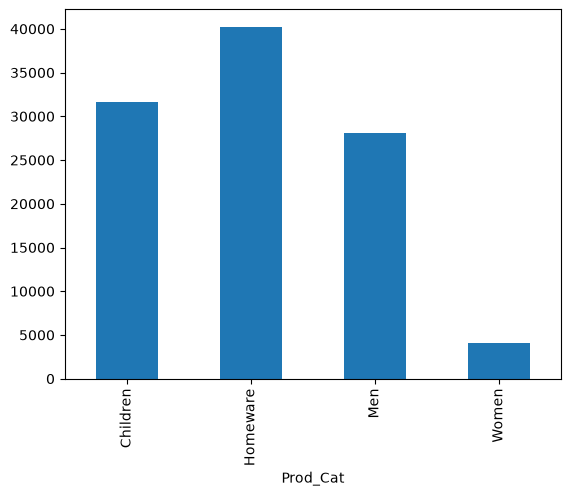

In [230]:
abt_grp3 = abt.groupby(["Prod_Cat"])
A3 = abt_grp3["Total_Profit"].sum()
A3.plot(kind = 'bar')
# abt_grp = abt.groupby(["Prod_Cat"])
# prod_cat_totals = abt_grp["Total_Profit"].sum()
# create the plot from the results
# prod_cat_totals.plot(kind="bar", 
#                    figsize=(5, 4), color="cornflowerblue",
#                    rot=0, width=0.9,
#                    ylabel="Overall Total Profit", xlabel="Category")
# plt.show()

### Aggregating Data - Further Example

In this example, we will look at a data manipulation example that includes both data aggreation and frequency tables.

We could apply both the `groupby` and `value_counts` methods to aggregate the transactions by date and then count the number of sales in different product categories on each date. 

The output is a new DataFrame containing the counts for the number of transactions per product category for each day.

In [231]:
GROUP = abt.groupby('Transaction_Date')['Prod_Cat'].value_counts().reset_index()
GROUP

,Transaction_Date,Prod_Cat,count
0,01/01/2019,Children,8
1,01/01/2019,Women,8
2,01/01/2019,Homeware,4
3,01/01/2019,Men,2
4,01/02/2019,Children,3
...,...,...,...
1183,31/10/2019,Men,6
1184,31/10/2019,Children,5
1185,31/12/2019,Children,11
1186,31/12/2019,Men,3


### Reshaping Data - Transpose

Different data analytics tools and techniques work with data in different formats or shapes. 

Pandas provides functionality for converting DataFrames between different shapes.

The simplest reshaping operation we can perform is a `transpose` of a DataFrame (i.e., swap rows and columns).

In [232]:
abt.head()

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41


In [233]:
abt.transpose()

Transaction_ID,T_ID_579441,T_ID_536370,T_ID_536367,T_ID_579462,T_ID_579472,T_ID_536371,T_ID_536425,T_ID_536526,T_ID_536405,T_ID_579508,...,T_ID_579403,T_ID_579408,T_ID_579350,T_ID_579270,T_ID_579358,T_ID_579402,T_ID_579431,T_ID_579328,T_ID_579288,T_ID_579301
Transaction_Date,01/01/2019,01/01/2019,01/01/2019,01/01/2019,01/01/2019,01/01/2019,01/01/2019,01/01/2019,01/01/2019,01/01/2019,...,31/12/2019,31/12/2019,31/12/2019,31/12/2019,31/12/2019,31/12/2019,31/12/2019,31/12/2019,31/12/2019,31/12/2019
Customer_ID,C_ID_38950,C_ID_39321,C_ID_40771,C_ID_41284,C_ID_42253,C_ID_42962,C_ID_42993,C_ID_43753,C_ID_43890,C_ID_44577,...,C_ID_45321,C_ID_45940,C_ID_47556,C_ID_49321,C_ID_53100,C_ID_54081,C_ID_54950,C_ID_55346,C_ID_55537,C_ID_56618
Product_ID,P_ID_100091,P_ID_100097,P_ID_100081,P_ID_100108,P_ID_100084,P_ID_100059,P_ID_100023,P_ID_100114,P_ID_100086,P_ID_100052,...,P_ID_100080,P_ID_100112,P_ID_100085,P_ID_100098,P_ID_100041,P_ID_100091,P_ID_100083,P_ID_100114,P_ID_100081,P_ID_100098
Prod_Cat,Children,Children,Children,Homeware,Children,Men,Women,Homeware,Children,Men,...,Children,Homeware,Children,Children,Men,Children,Children,Homeware,Children,Children
Prod_Description,White Colour Block T-Shirt,Multi Short Sleeve Character T-shirt,White Polo Two Pack,Feathers Printed Bed Set,Pink Cheque Shirt Dress,White Tie and Shirt Set,Harriet Chambray Top,Pennsylvania Notebooks,Lilac/Mint Long Sleeve Shirts,White Short Sleeve Bird Print Shirt,...,Hawaiian Print Sun Safe Two Piece,Mola Headlamp,Blue Floral Embroidered Mac,Navy Colourblock Crew and Jogger Set,Dark Blue Belted Jeans,White Colour Block T-Shirt,Multi Llama Vests Three Pack,Pennsylvania Notebooks,White Polo Two Pack,Navy Colourblock Crew and Jogger Set
Prod_Sub_Cat,Boys_wear,Boys_wear,Girls_wear,Bed_Bath,Girls_wear,Shirts,Tops,Design,Girls_wear,Shirts,...,Girls_wear,Design,Girls_wear,Boys_wear,Jeans,Boys_wear,Girls_wear,Design,Girls_wear,Boys_wear
Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,...,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,No Campaign,New Customer Offer
Cost_Per_Unit,11.03,8.09,3.67,22.75,8.09,21.70,14.00,6.90,12.74,17.98,...,8.57,25.80,17.15,8.57,17.40,11.03,8.57,6.90,3.67,8.57
Discount,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.10
On_Sale,No,No,No,No,No,No,No,No,No,No,...,No,No,No,No,No,No,No,No,No,Yes


### Reshaping Data - Pivot

We can convert from "long skinny" data to "short wide" data using a **pivot** operation.

As an example, we will consider the product category count data that we produced previously via aggregation.

In [234]:
GROUP.head()

,Transaction_Date,Prod_Cat,count
0,01/01/2019,Children,8
1,01/01/2019,Women,8
2,01/01/2019,Homeware,4
3,01/01/2019,Men,2
4,01/02/2019,Children,3


We could convert this "long skinny" data in "short wide" data by calling the Pandas `pivot` method

In [235]:
short_wide_counts = GROUP.pivot(index="Transaction_Date", 
                                      columns="Prod_Cat", 
                                      values="count")
short_wide_counts

Prod_Cat,Children,Homeware,Men,Women
Transaction_Date,,,,
01/01/2019,8.00,4.00,2.00,8.00
01/02/2019,3.00,2.00,3.00,1.00
01/03/2019,1.00,4.00,1.00,NaN
01/04/2019,6.00,1.00,3.00,NaN
01/05/2019,2.00,2.00,5.00,1.00
...,...,...,...,...
31/05/2019,3.00,3.00,3.00,1.00
31/07/2019,2.00,2.00,6.00,1.00
31/08/2019,7.00,3.00,3.00,NaN


Note that we have some missing values here, when there was no transaction for a given product category for a particular day. 

We will fill these with zeros using the Pandas `fillna` method that we saw previously.

In [236]:
short_wide_counts = short_wide_counts.fillna(0)
# check the data
short_wide_counts.head(10)

Prod_Cat,Children,Homeware,Men,Women
Transaction_Date,,,,
01/01/2019,8.00,4.00,2.00,8.00
01/02/2019,3.00,2.00,3.00,1.00
01/03/2019,1.00,4.00,1.00,0.00
01/04/2019,6.00,1.00,3.00,0.00
01/05/2019,2.00,2.00,5.00,1.00
01/06/2019,3.00,1.00,0.00,0.00
01/07/2019,6.00,1.00,2.00,0.00
01/08/2019,4.00,1.00,1.00,1.00
01/09/2019,3.00,4.00,10.00,0.00


### Reshaping Data - Melt

We can convert from "short wide" data to "long skinny" data using a **melt** operation.

As an example, we will reverse the previous pivot process applied to product category counts.

First, we need to reset the index so that `Transaction_Date` is restored as a column.

In [237]:
short_wide_counts = short_wide_counts.reset_index()
# check the data
short_wide_counts.head(10)

Prod_Cat,Transaction_Date,Children,Homeware,Men,Women
0,01/01/2019,8.00,4.00,2.00,8.00
1,01/02/2019,3.00,2.00,3.00,1.00
2,01/03/2019,1.00,4.00,1.00,0.00
3,01/04/2019,6.00,1.00,3.00,0.00
4,01/05/2019,2.00,2.00,5.00,1.00
5,01/06/2019,3.00,1.00,0.00,0.00
6,01/07/2019,6.00,1.00,2.00,0.00
7,01/08/2019,4.00,1.00,1.00,1.00
8,01/09/2019,3.00,4.00,10.00,0.00
9,01/10/2019,4.00,2.00,2.00,0.00


Now we can perform the melt operation by calling the Pandas `melt` method. 

This yields a "long skinny" version of the same data.

In [238]:
long_skinny_counts = pd.melt(short_wide_counts, id_vars=["Transaction_Date"], 
                             value_vars=["Children", "Homeware", "Men", "Women"],
                             var_name="Prod_Cat", 
                             value_name="Count")
long_skinny_counts.head(10)

,Transaction_Date,Prod_Cat,Count
0,01/01/2019,Children,8.00
1,01/02/2019,Children,3.00
2,01/03/2019,Children,1.00
3,01/04/2019,Children,6.00
4,01/05/2019,Children,2.00
5,01/06/2019,Children,3.00
6,01/07/2019,Children,6.00
7,01/08/2019,Children,4.00
8,01/09/2019,Children,3.00
9,01/10/2019,Children,4.00


In [239]:
short_wide_counts = long_skinny_counts.pivot(index="Transaction_Date", 
                                             columns="Prod_Cat", 
                                             values="Count")
short_wide_counts.sort_values(by="Transaction_Date").head(10)

Prod_Cat,Children,Homeware,Men,Women
Transaction_Date,,,,
01/01/2019,8.00,4.00,2.00,8.00
01/02/2019,3.00,2.00,3.00,1.00
01/03/2019,1.00,4.00,1.00,0.00
01/04/2019,6.00,1.00,3.00,0.00
01/05/2019,2.00,2.00,5.00,1.00
01/06/2019,3.00,1.00,0.00,0.00
01/07/2019,6.00,1.00,2.00,0.00
01/08/2019,4.00,1.00,1.00,1.00
01/09/2019,3.00,4.00,10.00,0.00


# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Multivariate Data Visualisation

In [240]:
pip install seaborn # INSTALL THE MISSING PACKAGE


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [241]:
# import the required packages
import pandas as pd # TO MANAGE DATABASES
import numpy as np # TO PERFORM COMPUTATIONS
import matplotlib # TO PLOT
import matplotlib.pyplot as plt # TO PLOT
# import the Seaborn visualisation lbirary
import seaborn as sns # TO PLOT

# ensure plots will appear in the notebook
%matplotlib inline

# we will limit the number of decimal places we display
pd.options.display.float_format = '{:,.2f}'.format 

### Introduction

In this notebook, we explore more advanced methods for generating data visualisations that work across multiple columns in a DataFrame. 

In particular, we will look at the use of the Python **Seaborn** library for visualisation.

### Data Loading

We will use the **cleaned version** of the retail transaction dataset which we created in Demo Notebook 3 and is stored in the CSV file `urban_wear_transactions_clean.csv`

In [242]:
datafile_name = "urban_wear_transactions_clean.csv"
abt = pd.read_csv(datafile_name, index_col=0)
# look at the first few rows
abt.head()

,Transaction_Date,Customer_ID,Product_ID,Prod_Cat,Prod_Description,Prod_Sub_Cat,Campaign,Cost_Per_Unit,Discount,On_Sale,Price_Per_Unit,Profit_Per_Unit,Quant,Sale_Amount,Total_Cost,Total_Product_Sale,Total_Profit
Transaction_ID,,,,,,,,,,,,,,,,,
T_ID_579441,01/01/2019,C_ID_38950,P_ID_100091,Children,White Colour Block T-Shirt,Boys_wear,No Campaign,11.03,0.00,No,22.50,11.47,3,22.50,33.08,67.50,34.42
T_ID_536370,01/01/2019,C_ID_39321,P_ID_100097,Children,Multi Short Sleeve Character T-shirt,Boys_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41
T_ID_536367,01/01/2019,C_ID_40771,P_ID_100081,Children,White Polo Two Pack,Girls_wear,No Campaign,3.67,0.00,No,7.50,3.83,1,7.50,3.67,7.50,3.83
T_ID_579462,01/01/2019,C_ID_41284,P_ID_100108,Homeware,Feathers Printed Bed Set,Bed_Bath,No Campaign,22.75,0.00,No,35.00,12.25,2,35.00,45.50,70.00,24.50
T_ID_579472,01/01/2019,C_ID_42253,P_ID_100084,Children,Pink Cheque Shirt Dress,Girls_wear,No Campaign,8.09,0.00,No,16.50,8.41,1,16.50,8.09,16.50,8.41


### Parallel Box Plots

A parallel box plot visualisation displays multiple box plots side by side for easy comparison.

The `boxplot` function in Seaborn allows us to create these directly from a Pandas DataFrame.

We can use a box plot to explore the values of a numeric feature *y* across levels of a categorical feature *x*. 

For example, for the transactions data we could investigate product category ('Prod_Cat') and 'Total_Product_Sale' amount.

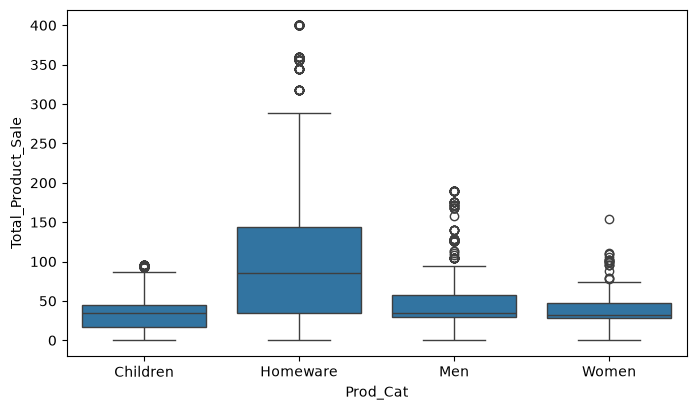

In [243]:
# create the figure with the specified size
plt.figure(figsize=(8, 4.5))
# now create the boxplot with Seaborn
sns.boxplot(data=abt, y="Total_Product_Sale", x="Prod_Cat")
plt.show()

We can customise the appearance of the boxplot in various ways by passing arguments to the `boxplot` function

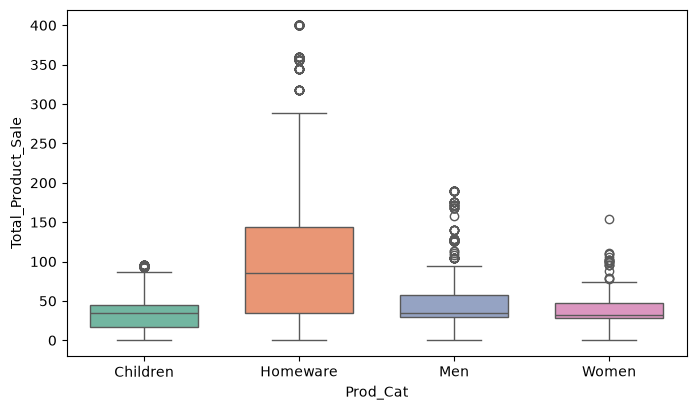

In [244]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=abt, y="Total_Product_Sale", x="Prod_Cat", 
            hue="Prod_Cat", palette="Set2", width=0.7) # assigns a different color to each product category
plt.show()

### Now you try...

- Based on the transaction data, create parallel box plots visualising the distribution the total profit per transaction across different product categories.

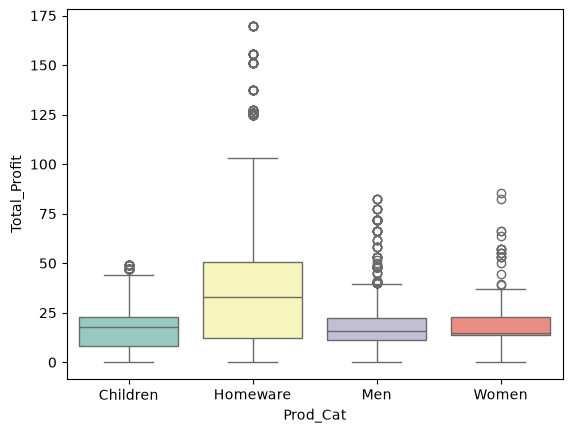

In [245]:
sns.boxplot(data=abt, y="Total_Profit", x="Prod_Cat", 
            hue="Prod_Cat", palette="Set3")
plt.show()
# plt.figure(figsize=(8, 4.5))
# sns.boxplot(data=abt, y="Total_Profit", x="Prod_Cat",  hue="Prod_Cat", palette="Set2")
# plt.show()

- Create parallel box plots visualising the distribution of the total profit per transaction across different values for the 'Campaign' feature

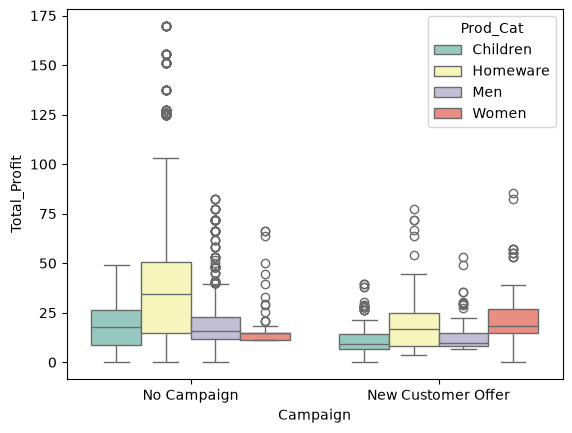

In [246]:
sns.boxplot(data=abt, y="Total_Profit", x="Campaign", 
            hue="Prod_Cat", palette="Set3" )
plt.show()
# plt.figure(figsize=(7, 4.5))
# sns.boxplot(data=abt, y="Total_Profit", x="Campaign",  hue="Campaign", palette="Set2")
# plt.show()

### Small Multiple Histograms

A series of small multiple histograms allow us to compare distributions according to the levels in a categorical variable.

The `displot` function in Seaborn allows us to easily create small multiple histograms from a DataFrame.

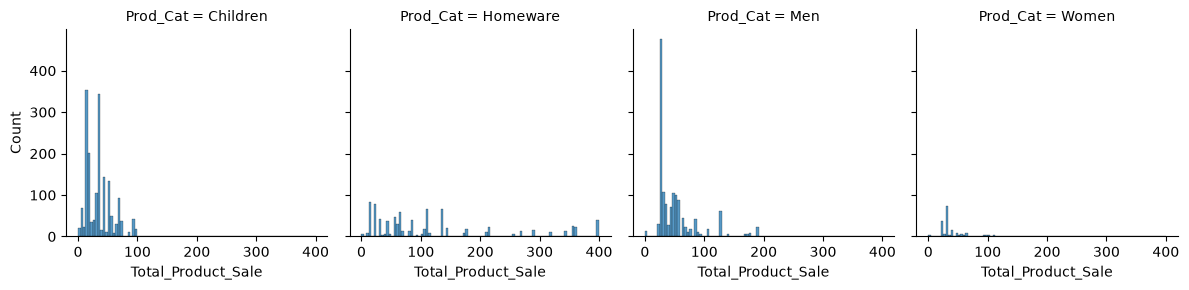

In [247]:
sns.displot(data=abt, x="Total_Product_Sale", col="Prod_Cat", height=3)
plt.show()

We can customise the appearance of the histograms in various ways by passing arguments to the `displot` function

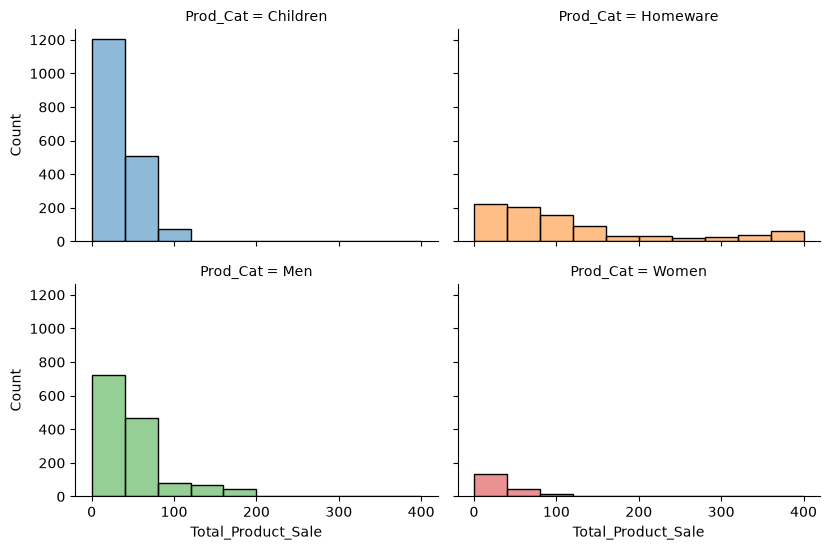

In [248]:
sns.displot(data=abt, x="Total_Product_Sale", col="Prod_Cat",
            hue="Prod_Cat", bins=10, legend=False, 
            col_wrap=2, height=2.8, aspect=1.5) # displays a maximum of 2 plots per row
plt.show()

### Now you try...

- Using the transactions dataset, create a set of **small multiple histograms** comparing the total profit amount for different product categories

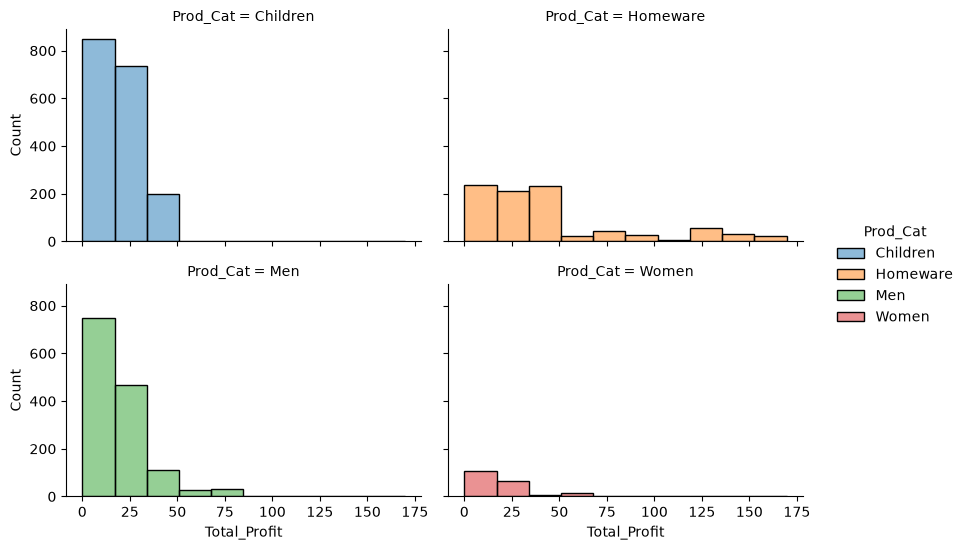

In [249]:
sns.displot(data=abt, x="Total_Profit", col="Prod_Cat", 
            hue="Prod_Cat", bins = 10,
            col_wrap=2, height=2.8, aspect=1.5)
plt.show()
# sns.displot(data=abt, x="Total_Profit", col="Prod_Cat",
#             hue="Prod_Cat", bins=10, legend=False, 
#             col_wrap=2, height=2.8, aspect=1.5)
# plt.show()

- Now create a set of **small multiple histograms** comparing the total profit amount for different marketing 'Campaign' values

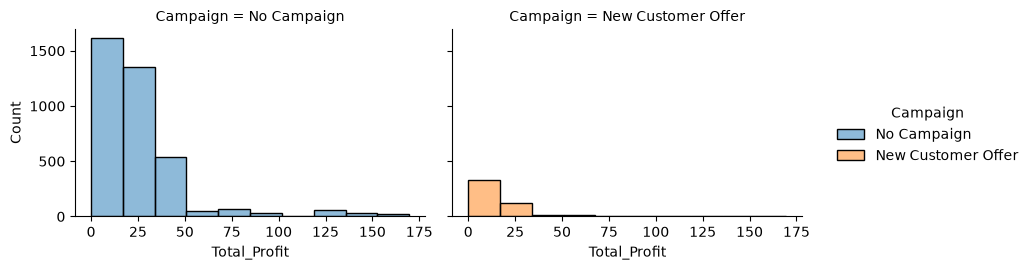

In [250]:
sns.displot(data=abt, x="Total_Profit", col="Campaign", 
            hue="Campaign", bins = 10,
            height=2.8, aspect=1.5)
plt.show()
# sns.displot(data=abt, x="Total_Profit", col="Campaign",
#             hue="Campaign", bins=10, legend=False, 
#             col_wrap=2, height=2.8, aspect=1.5)
# plt.show()

### Scatter Plots

Scatter plots are the easiest way to compare two numeric columns. 

We can create this kind of plot from a DataFrame by calling the Seaborn `scatterplot` function, specifying the source data, column to plot on the *x*-axis, and column to plot on the *y*-axis.

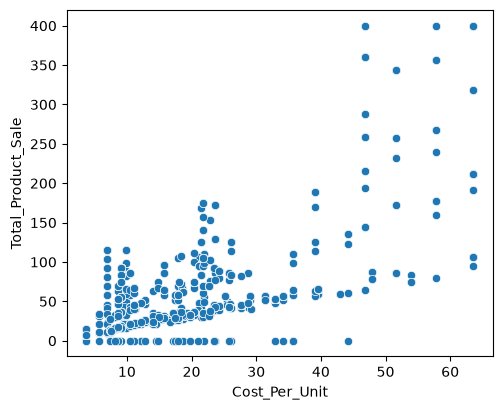

In [251]:
# set the size of the plot
plt.figure(figsize=(5.5, 4.5))
# create the plot
sns.scatterplot(data=abt, x="Cost_Per_Unit", y="Total_Product_Sale")
plt.show()

We can specify the `hue` argument, with the name of a column, to colour the points in the scatter plot. Normally this will be a categorical variable

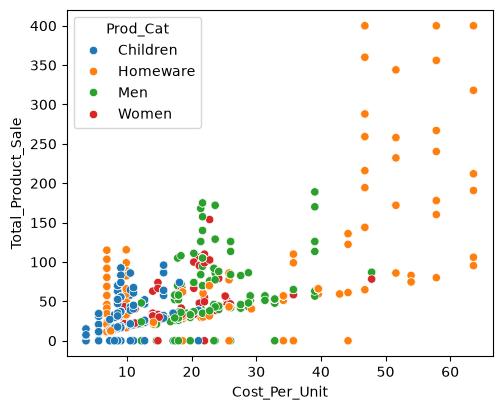

In [252]:
plt.figure(figsize=(5.5, 4.5))
sns.scatterplot(data=abt, x="Cost_Per_Unit", y="Total_Product_Sale", 
                hue="Prod_Cat")
plt.show()

We can customise the appearance of the plot in various ways by passing arguments to the `scatterplot` function

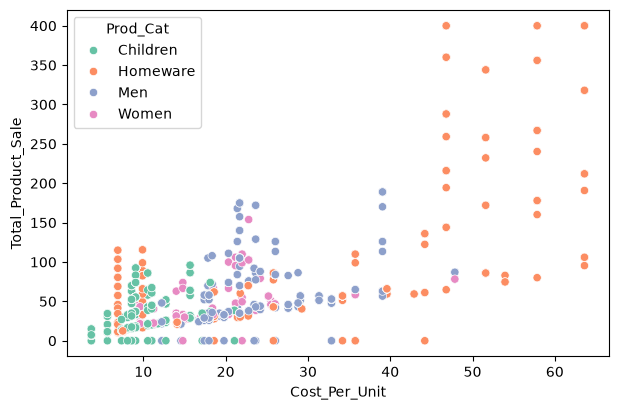

In [253]:
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=abt, x="Cost_Per_Unit", y="Total_Product_Sale", 
                hue="Prod_Cat", palette="Set2");
plt.show()

When we want to compare multiple numeric columns, we can use the `pairplot` function to create a matrix of scatter plots, consisting of each unique pair of columns specified. 

We can use the optional `vars` argument to specify the subset of columns to include in the visualisation.

Note the plots on the diagonal of the matrix (when the column is the same for both the x- and y-axes) instead display the distribution of the values for that column.

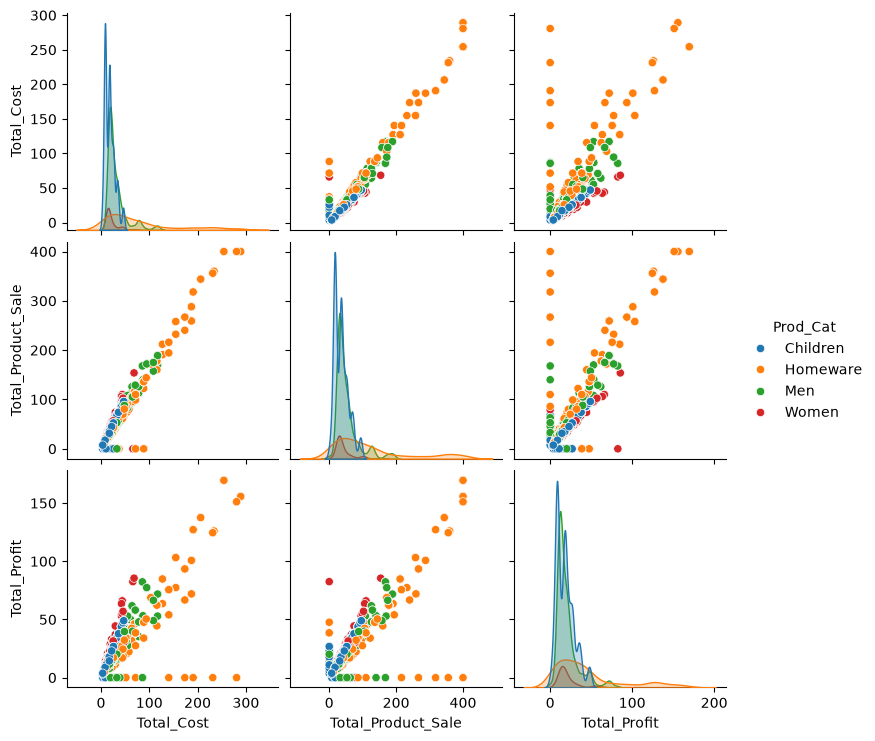

In [254]:
sns.pairplot(data=abt, 
             vars=["Total_Cost", "Total_Product_Sale", "Total_Profit"],
             hue="Prod_Cat")
plt.show()

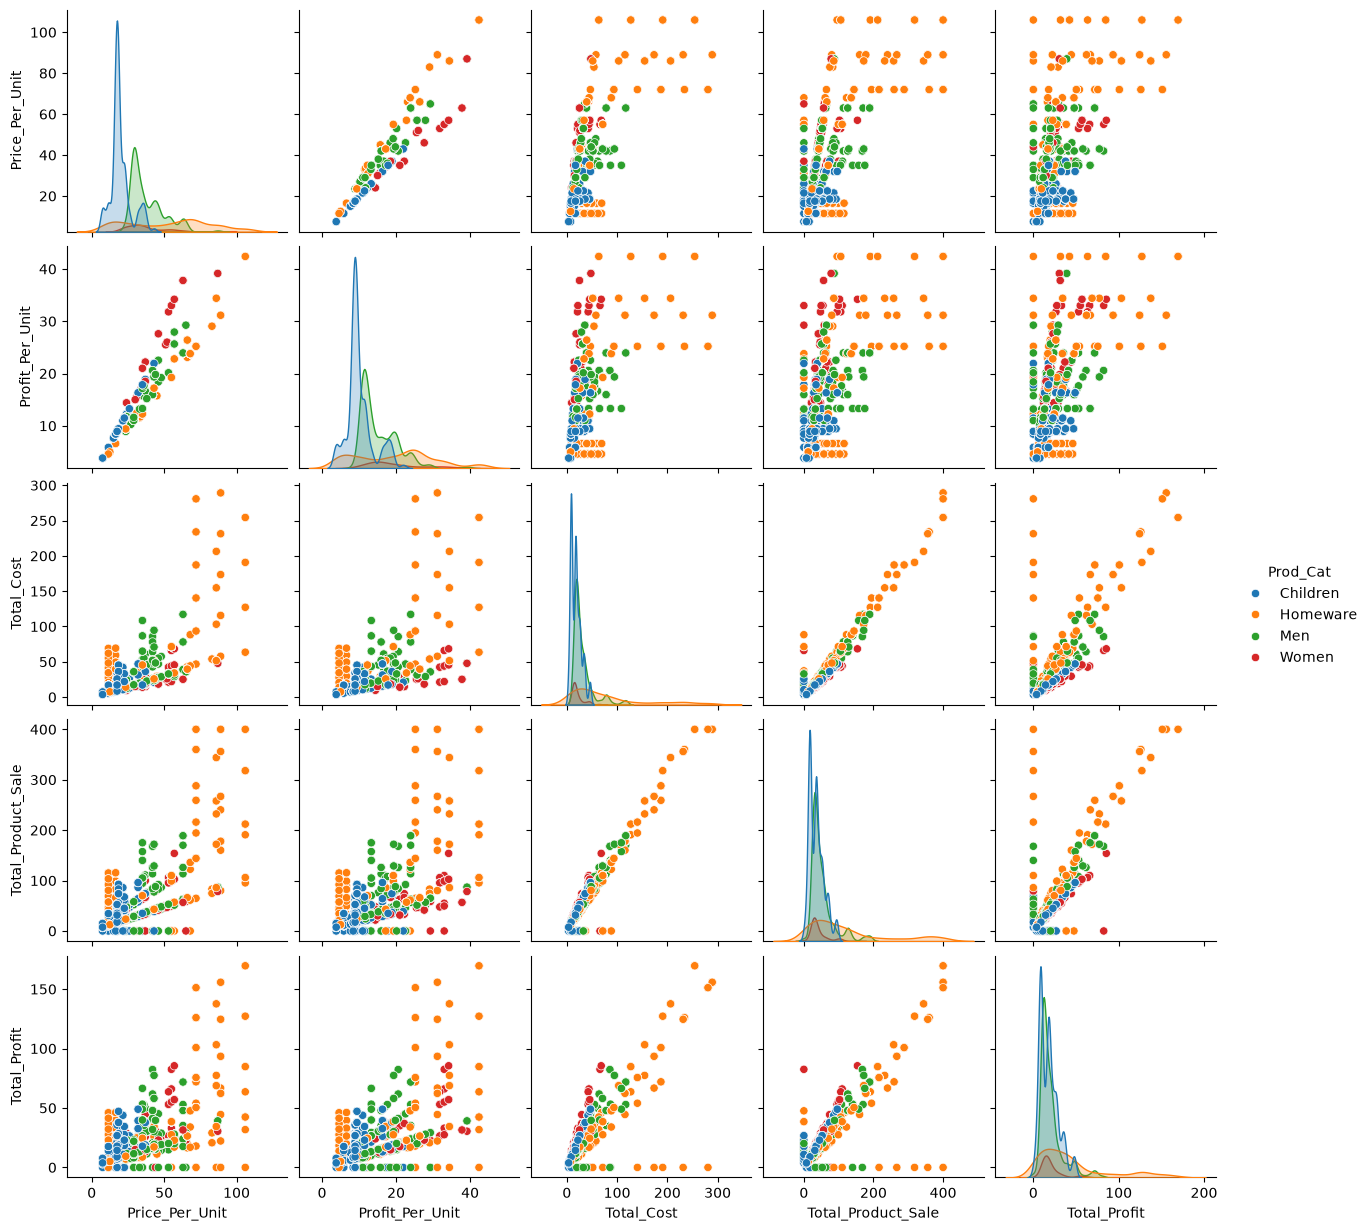

In [255]:
sns.pairplot(data=abt, 
             vars=["Price_Per_Unit", "Profit_Per_Unit", "Total_Cost", "Total_Product_Sale", "Total_Profit"],
             hue="Prod_Cat")
plt.show()

### Small Multiple Bar Plots

A set of small multiple bar plots is a set of bar plots showing the distribution of one categorical variable split by another. 

For instance, we could look at the relationship between product category and marketing campaign type.

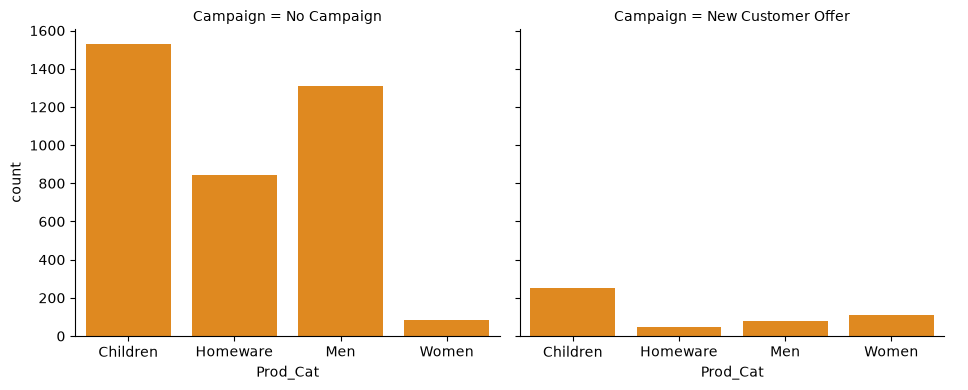

In [256]:
sns.catplot(data=abt, 
            x="Prod_Cat", col="Campaign", 
            kind="count", height=4, aspect=1.2, color="darkorange") # counts the number of observations in each product category
plt.show()

This is a visual equivalent of a cross-tabulation

In [257]:
pd.crosstab(abt["Prod_Cat"], abt["Campaign"])

Campaign,New Customer Offer,No Campaign
Prod_Cat,,
Children,254,1530
Homeware,46,846
Men,78,1311
Women,108,85


### Now you try...

- Use a **scatter plot** to examine the relationship between the price per unit and the profit per unit in the transaction data

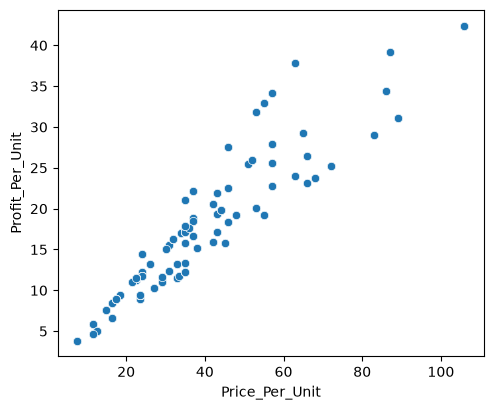

In [258]:
plt.figure(figsize=(5.5, 4.5))
sns.scatterplot(data=abt, x="Price_Per_Unit", y="Profit_Per_Unit")
plt.show()

- Change the previous scatter plot to change the colour (`hue`) of the points based on the product category involved in the transactions

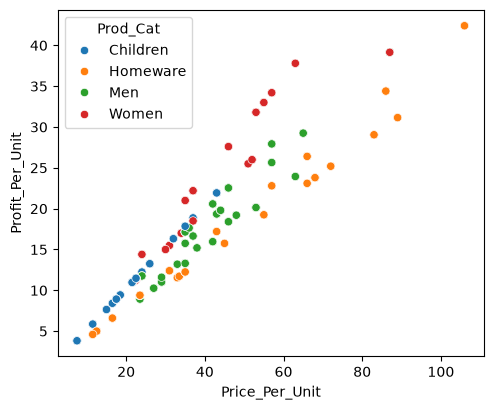

In [259]:
plt.figure(figsize=(5.5, 4.5))
sns.scatterplot(data=abt, x="Price_Per_Unit", y="Profit_Per_Unit", 
                hue="Prod_Cat")
plt.show()

- Use **small multiple bar plots** to investigate the relationship between the 'On_Sale' column and product sub-categories in the transactions dataset

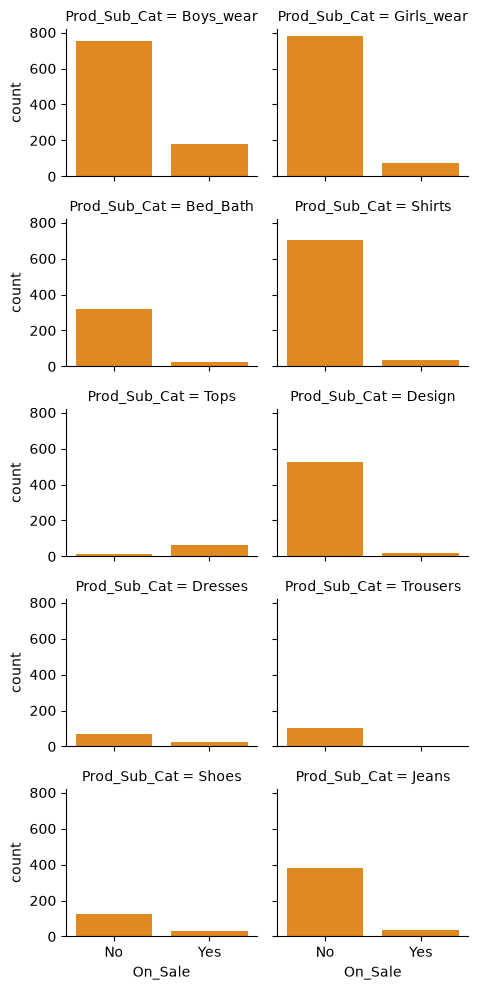

In [260]:
sns.catplot(data=abt, 
            x="On_Sale", col="Prod_Sub_Cat", 
            kind="count", col_wrap=2, height=2, aspect=1.2, color="darkorange")
plt.show()
# sns.catplot(data=abt, 
#             x="On_Sale", col="Prod_Sub_Cat", kind="count", 
#             color="darkorange", height=3, aspect=0.9,
#             col_wrap=4)
# plt.show()

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## NumPy Arrays

This notebook provides a short exploration of using NumPy data arrays. 

First, import NumPy. Note the use of the short nickname, `np`. 

There is no real reason for this name change other than laziness! 

Almost every Python example you will ever see does it, though, so it is a practice worth adopting. 

In [261]:
import numpy as np

### NumPy 1D Arrays

The simplest type of `array` is 1-dimensional (1D). 

We can create an `array` from an existing Python list.

In [262]:
a = np.array([12,18,4,12,20,0,37, 87])
print(a)

[12 18  4 12 20  0 37 87]


The `shape` property can be used to query the size of a NumPy `array`

In [263]:
a.shape

(8,)

The `ndim` property tells us the number of dimensions in the `array`

In [264]:
a.ndim

1

The `size` property tells us the number of elements in the `array`

In [265]:
a.size

8

NumPy arrays can only contain values of a single type, such as an integer or a float. 

We use the `dtype` property to query the type of an array. 

In [266]:
a.dtype

dtype('int64')

A different type

In [267]:
b = np.array([0.3, 0.12, 1.4, 2.3, 4.5])
print(b)

[0.3  0.12 1.4  2.3  4.5 ]


In [268]:
b.dtype

dtype('float64')

### Accessing 1D NumPy Arrays

Use square brackets to access `array` elements

In [269]:
a[1]

np.int64(18)

Array values can be changed in this way

In [270]:
a[1] = 42
print(a)

[12 42  4 12 20  0 37 87]


Negative indices access elements from the end of a list

In [271]:
a[-1]

np.int64(87)

Slicing allows us to access segments of an `array`

In [272]:
a[3:6]

array([12, 20,  0])

In [273]:
a[2:]

array([ 4, 12, 20,  0, 37, 87])

In [274]:
a[:5]

array([12, 42,  4, 12, 20])

We can even use slicing for assignments

In [275]:
a[2:] = 42
print(a)

[12 42 42 42 42 42 42 42]


### Now you try...

Create a 1D NumPy `array` containing the following daily sales values for a week's trading at a store: 4567, 2341, 1987, 2345, 1234, 9876, 1021, 871.

(The first day in the list is Monday, and the last day is Sunday.)

In [276]:
a = np.array([4567, 2341, 1987, 2345, 9876, 1021, 871])

Check the `type` and `shape` of the `array` you have created

In [277]:
print(type(a))
print(a.shape)

<class 'numpy.ndarray'>
(7,)


Print the sales from only the weekdays (i.e. exclude Saturday and Sunday)

In [278]:
print(a[0:5])

[4567 2341 1987 2345 9876]


The `argmax` function is a nice NumPy `array` function that returns the index of the maximum value in an `array`. 

Use it to determine which day of the week had the highest sales. 

In [279]:
print(a.argmax())

4


In [280]:
weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
max_sales_day = a.argmax()

print("Most sales are on", weekdays[max_sales_day])

Most sales are on Friday


The weekly sales at a second store in our chain were as follows: 3456, 1234, 908, 9762, 2134, 8643, 103.

Create another NumPy `array` containing these sales values.

In [281]:
week_2_sales = np.array([3456, 1234, 908, 9762, 2134, 8643, 103])

Add the two arrays together (simply use the `+` operator) to get the combined daily sales for the chain

In [282]:
combined_sales = a + week_2_sales
print(combined_sales)

[ 8023  3575  2895 12107 12010  9664   974]


Which day of the week had the highest combined sales (use `argmax` again)? 

In [283]:
print(combined_sales.argmax())

3


In [284]:
max_sales_day = combined_sales.argmax()

print("Most sales are on", weekdays[max_sales_day])

Most sales are on Thursday


### NumPy 2D Arrays

A 2D `array` can be viewed as a matrix, with rows and columns.

In [285]:
m = np.array([[1,2,3], [4,5,6], [7,8,9]])
print(m)

[[1 2 3]
 [4 5 6]
 [7 8 9]]


There are a number of functions that tell us about the size structure of an array

In [286]:
m.dtype

dtype('int64')

In [287]:
m.ndim

2

In [288]:
m.shape

(3, 3)

In [289]:
m.size

9

### Accessing 2D NumPy Arrays

For 2D arrays, use the notation `[row, col]` where `row` and `col` are the row and column indices respectively

In [290]:
m = np.array( [ [1,2,3], [4,5,6], [7,8,9] ] )
print(m)

[[1 2 3]
 [4 5 6]
 [7 8 9]]


In [291]:
m[0,1]

np.int64(2)

In [292]:
m[2,1]

np.int64(8)

We can use slicing with 2D arrays as well

In [293]:
m[1:3, 0:2]

array([[4, 5],
       [7, 8]])

In [294]:
m[1:, :2]

array([[4, 5],
       [7, 8]])

In [295]:
m[1,:]

array([4, 5, 6])

In [296]:
m[:, 2]

array([3, 6, 9])

### Utility Methods for Creating NumPy Arrays

NumPy provides some nice utility methods for creating new `arrays` containing `ones` or `zeros`

In [297]:
all_zeros = np.zeros((100, 100))

print(all_zeros)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [298]:
all_ones = np.ones((20, 100))

print(all_ones)

[[1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 ...
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]]


### Now you try...

Create a NumPy `array` called **pattern**, filled with zeros, with 9 rows and 9 columns

In [299]:
pattern = np.zeros((9, 9))
print(pattern)

[[0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Change the values of the elements in this `array` that lie within a large square in the middle (rows 1 to 7 and columns 1 to 7) to values of 1. 

Print the `array` to view the pattern.

In [300]:
pattern[1:8, 1:8] = 1
print(pattern)

[[0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Change the values of the elements in this `array` that lie within a smaller square in the middle (rows 2 to 6 and columns 2 to 6) to values of 2. 

Print the `array` to view the pattern.

In [301]:
pattern[2:7, 2:7] = 2
print(pattern)

[[0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Change the values of the elements in this `array` that lie within an even smaller square in the middle (rows 3 to 5 and columns 3 to 5) to values of 3. 

Print the `array` to view the pattern.

In [302]:
pattern[3:6, 3:6] = 3
print(pattern)

[[0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 2. 3. 3. 3. 2. 1. 0.]
 [0. 1. 2. 3. 3. 3. 2. 1. 0.]
 [0. 1. 2. 3. 3. 3. 2. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Change the value of the middle element to 4. 

Print the `array` to view the pattern.

In [303]:
pattern[4, 4] = 4
print(pattern)

[[0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 2. 3. 3. 3. 2. 1. 0.]
 [0. 1. 2. 3. 4. 3. 2. 1. 0.]
 [0. 1. 2. 3. 3. 3. 2. 1. 0.]
 [0. 1. 2. 2. 2. 2. 2. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]]


The following code uses the `matplotlib` library to plot an image based on the pattern created. 

Run it to view what you have made!

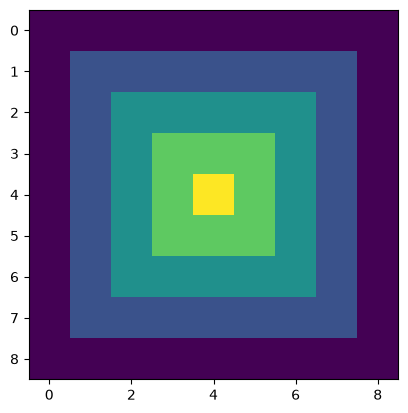

In [304]:
import matplotlib.pyplot as plt

plt.imshow(pattern)
plt.show()

The following function checks if a number is a prime number

In [305]:
import math

def isPrime(n):
    
    if n == 2 or n == 3: 
        return True
    if n%2 == 0 or n < 2: 
        return False

    for i in range(3, int(math.sqrt(n))+1, 2):   # only odd numbers
        if n%i == 0:
            return False    

    return True

Assuming that our `array` contains the integers from 1 to 100, check whether each number is prime. 

If a number is prime, change its value to 1. 

Print the resulting pattern. 

In [306]:
primes = np.zeros((10, 10))
counter = 1

for i in range(primes.shape[0]):
    for j in range(primes.shape[1]):
        if isPrime(counter):
            primes[i,j] = 1
        counter = counter +1
        
print(primes)

[[0. 1. 1. 0. 1. 0. 1. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0. 1. 0. 1. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]]


Use the code below to print the pattern created

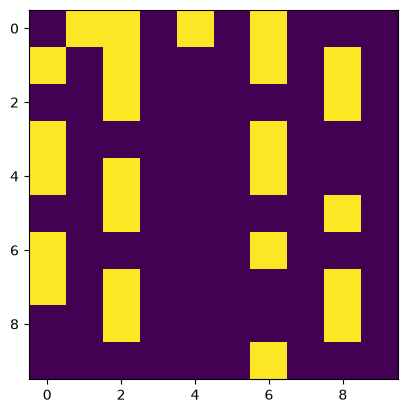

In [307]:
import matplotlib.pyplot as plt
plt.imshow(primes)
plt.show()

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Confidence Intervals 

This notebook introduces the use of the **scipy.stats** package to calculate a simple confidence interval

### Import Libraries

To get started we import the **pandas** library (and the **numpy** library as much of pandas is based on this). 

We import the **scipy.stats** library for basic statistical functions. 

Check out [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html) for more details.

In [308]:
import pandas as pd
import numpy as np

import scipy.stats as st

### Import Data
Next, we will import our data. For this section, we will use the Titanic dataset from *Titanic.csv*. 

The variables in this dataset are:

- **survival:** Survival	0 = No; 1 = Yes
- **pclass:**	Passenger Class	1 = 1st; 2 = 2nd; 3 = 3rd
- **name:**	First and Last Name	 
- **sex:**	Sex	 
- **age:**	Age	 
- **sibsp:**	Number of Siblings/Spouses Aboard	 
- **parch:**	Number of Parents/Children Aboard	 
- **ticket:**	Ticket Number	 
- **fare:**	Passenger Fare	 
- **cabin:**	Cabin	 
- **embarked:**	Port of Embarkation	C = Cherbourg; Q = Queenstown (Cobh); S = Southampton

In [309]:
datafile_name="Titanic.csv"
dataset = pd.read_csv(datafile_name)
display(dataset.head(10))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.46,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.00,0,0,17463,51.86,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.00,3,1,349909,21.07,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.00,0,2,347742,11.13,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.00,1,0,237736,30.07,NaN,C


### Confidence Interval

An interval estimate for a population parameter is called a confidence interval. 

The key elements of a confidence interval are:
- A confidence level 
- An upper and lower confidence bound

We can use the `interval` method from **scipy.stats.norm** library to calculate confidence intervals for a normally distributed dataset. 

The `interval` method has three parameters:
- `alpha`: confidence level
- `loc`: mean
- `scale`: standard deviation

In [310]:
confidenceLevel = 0.95         
sampleMean = dataset['Age'].mean()         # sample mean 
sampleStandardError = dataset['Age'].sem() # sample standard error


st.norm.interval(confidence = confidenceLevel, 
                 loc = sampleMean, 
                 scale = sampleStandardError)

(np.float64(28.633601847600097), np.float64(30.764633446517543))

### Now you try...

Calculate a confidence interval for the mean of the `Fare` variable with a confidence level of **95%**

In [311]:
confidenceLevel = 0.95         
sampleMean = dataset['Fare'].mean()         # sample mean 
sampleStandardError = dataset['Fare'].sem() # sample standard error


st.norm.interval(confidence = confidenceLevel, 
                 loc = sampleMean, 
                 scale = sampleStandardError)

(np.float64(28.94127463271884), np.float64(35.46714130443043))

# Programming with Python for Data Analytics
[Krisolis](http://www.krisolis.ie)

## Hypothesis Testing

This notebook introduces the use of the **scipy.stats** and **statsmodels** libraries to perform hypothesis testing

### Import Libraries

To get started we import the **pandas** library (and the **numpy** library as much of pandas is based on this)

In [312]:
pip install statsmodels


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [313]:
import pandas as pd
import numpy as np

from scipy.stats import chi2_contingency
import statsmodels.api as sm
from statsmodels.formula.api import ols

import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

### Import Data
Next, we will import our data. For this section, we will use the Titanic dataset from *Titanic.csv*. 

The variables in this dataset are:

- **survival:** Survival	0 = No; 1 = Yes
- **pclass:**	Passenger Class	1 = 1st; 2 = 2nd; 3 = 3rd
- **name:**	First and Last Name	 
- **sex:**	Sex	 
- **age:**	Age	 
- **sibsp:**	Number of Siblings/Spouses Aboard	 
- **parch:**	Number of Parents/Children Aboard	 
- **ticket:**	Ticket Number	 
- **fare:**	Passenger Fare	 
- **cabin:**	Cabin	 
- **embarked:**	Port of Embarkation	C = Cherbourg; Q = Queenstown (Cobh); S = Southampton

In [314]:
datafile_name="Titanic.csv"
dataset = pd.read_csv(datafile_name)
display(dataset.head(10))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.46,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.00,0,0,17463,51.86,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.00,3,1,349909,21.07,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.00,0,2,347742,11.13,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.00,1,0,237736,30.07,NaN,C


### Examining Associations Using Cross Tabulations

**Question:** Is there an association between a passenger surviving (`Survived`) the wreck of the Titanic and the class in which they traveled (`Pclass`)?

We can answer this using a **cross tabulation** (or **contingency table**). 

We compute a simple cross tabulation of two (or more) factors using the `crosstab` function. 

In [315]:
pd.crosstab(dataset["Survived"], 
            dataset["Pclass"])

Pclass,1,2,3
Survived,,,
0,80,97,372
1,136,87,119


We can normalize data in a cross tabulation using the `normalize` option passed to the `crosstab` function. 

The different ways we can normalize are:

- ‘all’ (or True): normalize over all values
- ‘index’: normalize over each row
- ‘columns’: normalize over each column

If the `margins` parameter is set to `True`, the margin values will also be normalised.

In [316]:
pd.crosstab(dataset["Survived"], 
            dataset["Pclass"], 
            normalize="all")

Pclass,1,2,3
Survived,,,
0,0.09,0.11,0.42
1,0.15,0.10,0.13


In [317]:
pd.crosstab(dataset["Survived"], 
            dataset["Pclass"], 
            margins = True)

Pclass,1,2,3,All
Survived,,,,
0,80,97,372,549
1,136,87,119,342
All,216,184,491,891


In [318]:
pd.crosstab(dataset["Survived"], 
            dataset["Pclass"], 
            margins = True, normalize="all")

Pclass,1,2,3,All
Survived,,,,
0,0.09,0.11,0.42,0.62
1,0.15,0.10,0.13,0.38
All,0.24,0.21,0.55,1.00


In [319]:
pd.crosstab(dataset["Survived"], 
            dataset["Pclass"], 
            margins = True, normalize="index")

Pclass,1,2,3
Survived,,,
0,0.15,0.18,0.68
1,0.40,0.25,0.35
All,0.24,0.21,0.55


In [320]:
pd.crosstab(dataset["Survived"], 
            dataset["Pclass"], 
            margins = True, normalize="columns")

Pclass,1,2,3,All
Survived,,,,
0,0.37,0.53,0.76,0.62
1,0.63,0.47,0.24,0.38


A **heat map** can be used to visualise a cross-tabulation. 

A heat map uses a colour-coded system to represent the data graphically and highlights extreme values in the data. 

Typically darker shades indicate higher values and lighter shades indicate lower values in the data. 

The `heatmap` function from the **seaborn** package draws nice heat maps. 

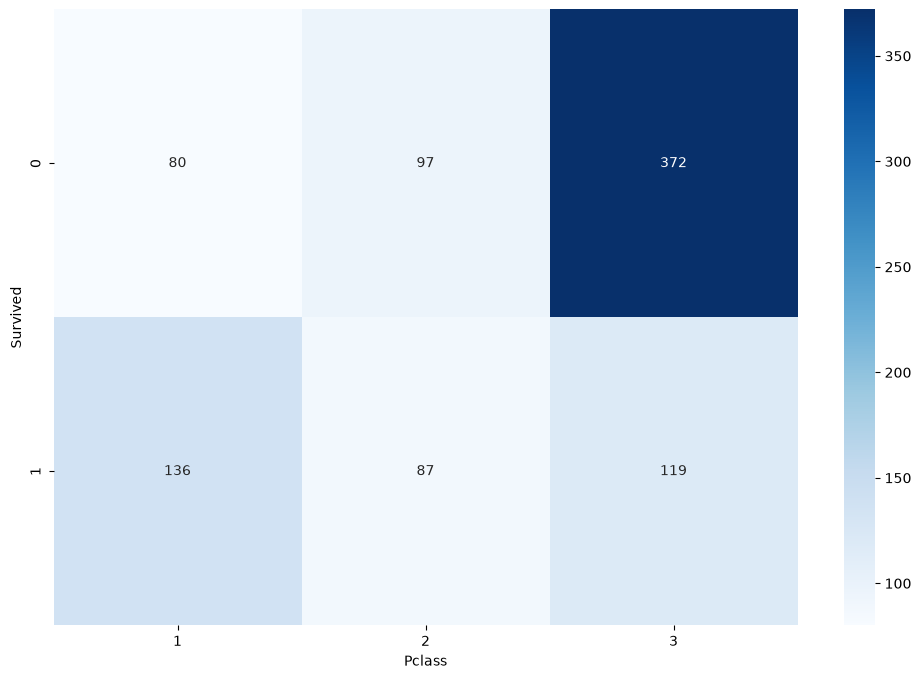

In [321]:
contigency = pd.crosstab(dataset["Survived"], 
                         dataset["Pclass"])

plt.figure(figsize=(12,8))
sns.heatmap(contigency, annot=True, cmap="Blues", fmt = 'd')
plt.show()

### Now you try...

**Question:** Is there an association between somebody surviving the wreck of the Titanic (`Survived`) and their sex (`Sex`)?

1. Create a contingency table with count values and create a heat map to visualize this.

In [322]:
contigency_sex_survived = pd.crosstab(dataset["Survived"], dataset["Sex"])
contigency_sex_survived

Sex,female,male
Survived,,
0,81,468
1,233,109


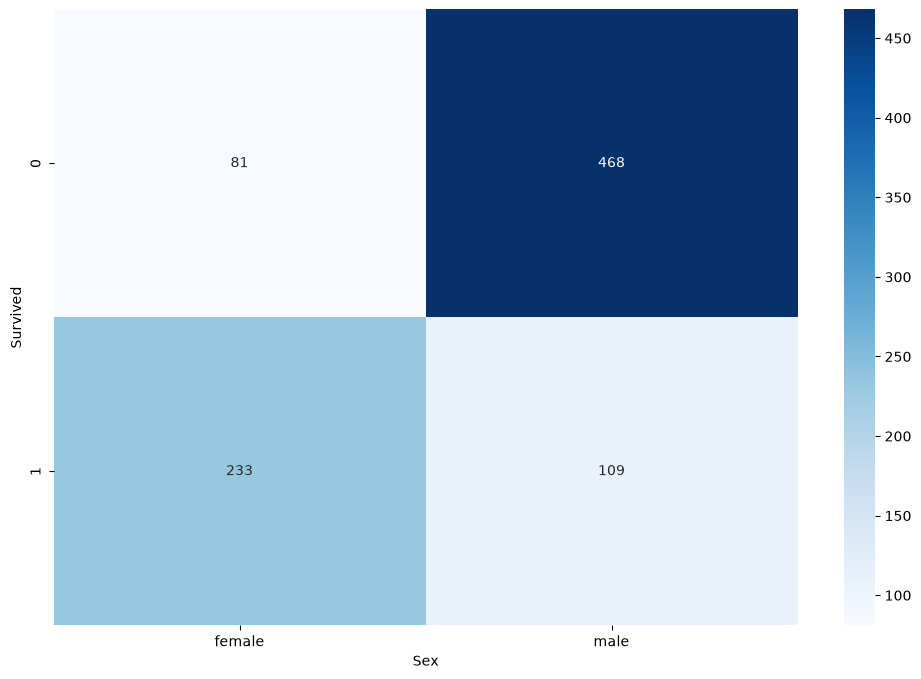

In [323]:
plt.figure(figsize=(12,8)) 
sns.heatmap(contigency_sex_survived, annot=True, cmap="Blues", fmt = 'd')
plt.show()

2. Create a contingency table showing total values and calculate the proportions of Male and Female values for both Survived and Not Survived. (Hint: normalize='columns')

In [324]:
pd.crosstab(dataset["Survived"], 
            dataset["Sex"], 
            margins = True, normalize="columns")

Sex,female,male,All
Survived,,,
0,0.26,0.81,0.62
1,0.74,0.19,0.38


### Hypothesis Testing Using $\chi^2$

The steps in performing a hypothesis test are:

1. Perform some exploratory analysis
2. Select the appropriate test
3. State the null hypothesis, H0 
4. Specify an appropriate alternative hypothesis, H1
5. Choose a significance level, $\alpha$
6. Calculate the $p$-value using a software package of choice
7. Decide whether or not H0 should be rejected and report that in the problem context: reject H0 when $p$-value is less than $\alpha$

**Question:** Is there a statistically significant association between a passenger surviving (`Survived`) the wreck of the Titanic and the class in which they traveled (`Pclass`)?

We can assess this using a $\chi^2$ hypothesis test conducted on a contingency table:

- H0: there is no association between `Survived` and `Pclass`
- H1: there is an association between `Survived` and `Pclass`

In this example we set $\alpha=0.05$.

The `chi2_contingency` function from the **scipy.stats** module takes as input a contingency table and returns a tuple containing test statistics, the p-value, degrees of freedom and the expected frequencies table (generated by calculating the expected counts that would appear if the two variables were independent) in that order. 

In [325]:
# Chi-square test of independence
c, p, dof, expected = chi2_contingency(contigency) 

print('The Chi-Squared Statistic is:', c)
print('The p-value for the test is:', p)
print('The DoF for the test is:', dof)
print('The expected frequencies table for the test is:')
print(expected)

The Chi-Squared Statistic is: 102.88898875696056
The p-value for the test is: 4.549251711298793e-23
The DoF for the test is: 2
The expected frequencies table for the test is:
[[133.09090909 113.37373737 302.53535354]
 [ 82.90909091  70.62626263 188.46464646]]


The independence test checks to see if the actual data is "close enough" to the expected counts. 

We reject the null hypothesis, H0 (which assumes independence), if the $p$-value is small ($<\alpha$). 

In this case as $\alpha=0.05$ we reject H0 and conclude that there is a statistically significant relationship between `Survived` and `Pclass`. 

### Now you try...

**Question:** Is there a statistically significant association between a passenger surviving (`Survived`) the wreck of the Titanic and their sex (`Sex`)?

To determine this perform a $\chi^2$ test as follows:

- H0: there is no association between `Survived` and `Sex`
- H1: there is an association between `Survived` and `Sex`

and interpret the test statistic using $\alpha=0.05$.

In [326]:
# Chi-square test of independence. 
c, p, dof, expected = chi2_contingency(contigency_sex_survived) 
print('The Chi-Squared Statistic is:', c)
print('The p-value for the test is:', p)
print('The DoF for the test is:', dof)
print('The expected frequencies table for the test is:')
print(expected)
# c, p, dof, expected = chi2_contingency(contigency_sex_survived) 
# print('The p-value for the test is:', p)
# print('The Chi-Squared Statistic is:', c)

The Chi-Squared Statistic is: 260.71702016732104
The p-value for the test is: 1.197357062775565e-58
The DoF for the test is: 1
The expected frequencies table for the test is:
[[193.47474747 355.52525253]
 [120.52525253 221.47474747]]


### Hypothesis Testing Using ANOVA

Frequently we want to analyze the mean of a continuous variable broken into groups based on a categorical variable. 

The method, called **Analysis of Variance** (or **ANOVA** for short), allows us to compare the means of two or more samples. 

**Question:** Is there an association between a passenger surviving (`Survived`) the wreck of the Titanic and their age (`Age`)?

Let's look at some descriptive statistics.

In [327]:
grouped_data = dataset.groupby('Survived')
display(grouped_data[['Age']].describe())

Age                                         
          count  mean   std  min   25%   50%   75%   max
Survived                                                
0        424.00 30.63 14.17 1.00 21.00 28.00 39.00 74.00
1        290.00 28.34 14.95 0.42 19.00 28.00 36.00 80.00

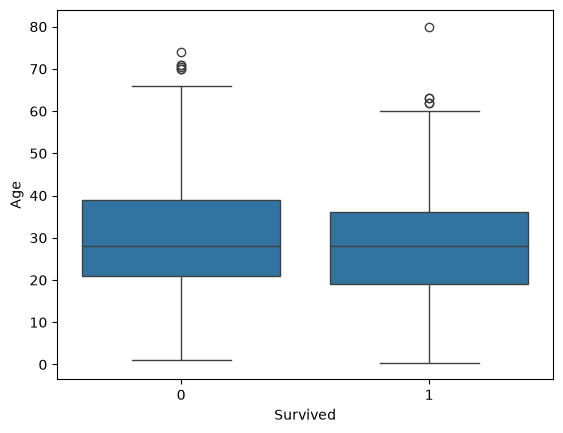

In [328]:
sns.boxplot(data=dataset, x="Survived", y="Age")
plt.show() # Where 0 signifies 'survived'

It looks like there is not an association but we can test this using ANOVA: 
- H0: mean `Age` values are equal for the 0 (did not survive) and 1 (survived) groups of `Survived`
- H1: mean `Age` values are not equal for the 0 (did not survive) and 1 (survived) groups of `Survived`

The `anova_lm` function from the **statsmodels** package implements an ANOVA test. 

We pass it a regression model calculated using the `ols` function, also from the **statsmodels** package. 

In [329]:
model = ols('Age ~ C(Survived)', data=dataset).fit() # Linear regression: the formula is an R-style formula, such as "y ~ x1 + x2" where y is a response to x1+x2, and data is a data frame that contains the variables. 
anova_table = sm.stats.anova_lm(model, typ=2)
anova_table

,sum_sq,df,F,PR(>F)
C(Survived),897.19,1.00,4.27,0.04
Residual,"149,559.45",712.00,NaN,NaN


The key question here is whether the difference in the means of 28 for those that survived and 30 for those that did not survive is likely to be maintained if this experiment was run again

### Now you try...

**Question:** Is there an association between a passenger's ticket class (`Pclass`) and the fare they paid (`Fare`)?

Perform an ANOVA test to answer this question. 

In [330]:
grouped_data = dataset.groupby('Pclass')
display(grouped_data[['Fare']].describe())

Fare                                          
        count  mean   std  min   25%   50%   75%    max
Pclass                                                 
1      216.00 84.15 78.38 0.00 30.92 60.29 93.50 512.33
2      184.00 20.66 13.42 0.00 13.00 14.25 26.00  73.50
3      491.00 13.68 11.78 0.00  7.75  8.05 15.50  69.55

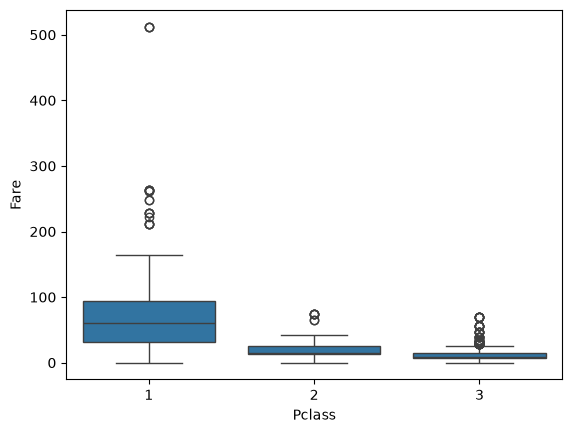

In [331]:
sns.boxplot(data=dataset, x="Pclass", y="Fare")
plt.show()

In [332]:
model = ols('Fare ~ C(Pclass)', data=dataset).fit() 
# Linear regression: the formula is an R-style formula, such as "y ~ x1 + x2" 
# where y is a response to x1+x2, and data is a data frame that contains the variables
anova_table = sm.stats.anova_lm(model, typ=2)
anova_table

,sum_sq,df,F,PR(>F)
C(Pclass),"776,030.06",2.00,242.34,0.00
Residual,"1,421,768.74",888.00,NaN,NaN
